# **Project Name**    - DeepFER: Facial Emotion Recognition Using Deep Learning



##### **Project Type**    - Classification (deep learning, computer vision: 7 facial emotions)
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee

# **Project Summary -**

This project builds DeepFER, a system that recognises seven emotions (angry, disgust, fear, happy, neutral, sad and surprise) from photos of faces and runs in real time on a webcam. The data is 35,887 grayscale face pictures of 48x48 pixels in a train folder (28,821) and a validation folder (7,066), which I use as the final test set and never touch for any choice.

Cleaning mattered more than expected. Comparing the pixels of every picture found 1,853 exact copies, including 627 training pictures that were copies of test pictures (a leak) and 57 pictures saved under two different emotions. Checking the flattest pictures by eye found 58 that are not faces at all (warning signs, "image removed" banners, icons) and 14 blank ones. After removing them, 33,919 pictures (94.5%) remain: 22,921 for training, 4,046 for validation (early stopping and model choice) and 6,952 for the test.

The analysis shows why the task is hard. The emotions overlap in every simple measure (brightness, contrast, edges) and on a t-SNE map of handcrafted features. The average faces show the main signals: the smile and raised cheeks for happy, wide eyes and an open mouth for surprise. Fear looks like surprise and sad, and angry like sad, which is exactly where the models fail later. Disgust is only 1.3% of the training pictures.

I compared three kinds of models:
1. A classic baseline: HOG and LBP features with CLAHE lighting correction and a logistic regression tuned with a cross-validated grid search. Test accuracy 45.2%, macro F1 0.385.
2. DeepFER-Net, a CNN I designed for 48x48 faces, with residual blocks and squeeze-excitation attention (6.4M parameters). Without augmentation it overfits (58.9%). With GPU data augmentation, class weights and a tuned learning rate it reaches 68.2% accuracy and macro F1 0.661.
3. Transfer learning with ResNet18 and EfficientNet-B0 from ImageNet. With the pre-trained body frozen they only reach about 45%, but fine-tuning the whole network gives 68.7% and 67.6%.

The final model averages ResNet18 and my CNN, each scoring the face and its mirror image, chosen on the validation set. On the 6,952 test faces it reaches **70.7% accuracy** (95% interval 69.7-71.7%) and **macro F1 0.688**, significantly better than every single model. People agree on this kind of data only about 65% of the time. Happy (F1 0.89) and surprise (0.79) are easy, fear (0.54) and sad (0.58) are hard, and the most common error is sad read as neutral. On the half of the faces it is most confident about, it is right 89% of the time.

Grad-CAM and occlusion tests show what the model uses: hiding the eyes and brows cuts the recall of disgust by 46 points and angry by 32, hiding the mouth cuts happy by 35. It copes well with dark lighting (CLAHE recovers most of the loss on very dark faces) but not with heavy noise or a covered mouth.

For real time, OpenCV finds the faces, they are cropped like the training faces and scored in one batch, at about 13 ms per face on a laptop CPU, so a webcam runs at over 20 frames per second. The system is deployed locally as a Streamlit app and a live webcam window. Training ran on a Colab T4 GPU, because PyTorch on my Mac's brand new Apple GPU froze and corrupted weights.

# **GitHub Link -**

https://github.com/Tahascommit/deepfer-emotion-recognition

# **Problem Statement**


**Can a computer tell how a person feels from a photo of their face?**

People show emotions on their faces all the time, and many services would work better if a machine could read them: a virtual assistant that notices the user is confused, a support desk that sees a customer getting angry on a video call, or a wellbeing app that tracks mood over weeks. Reading faces is hard for a machine because the differences between emotions are small (a little more tension around the eyes, a slightly lowered mouth corner), people show the same emotion in different ways, and real photos vary in lighting, head angle and background.

The task: build a deep learning system that takes an image of a face and classifies it into one of seven emotions: **angry, disgust, fear, happy, neutral, sad and surprise**. The data is a public set of 35,887 grayscale face images of 48x48 pixels, already sorted into a train and a validation folder by emotion. The system should:
1. clean and prepare the images and use data augmentation (rotation, scaling, flipping) to generalise better,
2. compare a CNN designed and trained from scratch with transfer learning from pre-trained ImageNet models,
3. be evaluated with accuracy, precision, recall and F1-score per emotion, with an honest look at which emotions it confuses,
4. run in real time on a webcam and be usable through a simple application.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

### How this notebook covers the project objectives

| Objective | Where to find it |
|---|---|
| Data collection and cleaning: duplicates, leaks between folders, conflicting labels, blank and non-face pictures | Sections 1 to 3, 6.1 and 6.2 |
| Feature engineering and selection | Section 6.4: HOG and LBP features, CLAHE test, pixel and HOG F-tests |
| Pre-processing and data augmentation (rotation, scaling, flipping, lighting, cut-out) | Section 6.5 to 6.9 and `deepfer.augment` |
| CNN design | ML Model 2 (DeepFER-Net, a residual CNN with squeeze-excitation attention) |
| Transfer learning and fine-tuning | ML Model 3 (ResNet18 and EfficientNet-B0 from ImageNet) |
| Training: mini-batches, learning-rate schedule, early stopping, mixed precision on the GPU | `deepfer.train_model`, ML Models 2 and 3 |
| Evaluation: accuracy, precision, recall, F1, confusion matrix, confidence intervals, McNemar tests | Every model, then section 7, steps 4 to 6 |
| Innovative techniques: attention blocks, GPU augmentation, test-time mirroring, ensemble, calibration, Grad-CAM | ML Models 2 and 3, section 7 steps 3, 6 and the explainability part |
| Real-time processing and speed | Section 7 step 8 and section 7.1 |
| Application | Section 7.2: Streamlit app (`app/app.py`) and live webcam window (`app/webcam.py`) |

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import sys
import json
import time
import copy
import zipfile
import warnings
import importlib
import itertools
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

import cv2
from skimage.feature import hog
import torch
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)


def save(name):
    """Save the current chart to outputs/figures (used in the README and the app) and show it."""
    plt.savefig(FIG / name, dpi=110, bbox_inches="tight")
    plt.show()


# QUICK is only for a fast check that every cell runs (tiny subsets and 1-2 epochs). The real run has it off.
QUICK = os.environ.get("DEEPFER_QUICK") == "1"
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| opencv", cv2.__version__, "| quick test run" if QUICK else "| full run")

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | opencv 4.14.0 | full run


### Dataset Loading

#### The shared code (`deepfer.py`)
The loading, cleaning, augmentation, model, training, explanation and face detection code is written to `deepfer.py`. The Streamlit app and the live webcam script import the same file, so they prepare a face in exactly the same way as this notebook.

In [2]:
%%writefile deepfer.py
# DeepFER: shared code for the notebook, the Streamlit app and the live webcam script.
# The notebook writes this file, so the app and the webcam script use exactly the same steps.
import copy
import hashlib
import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
IMG = 48                                           # every image in the dataset is 48x48 grayscale
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_device():
    """NVIDIA GPU on Colab, the Apple GPU (MPS) on a Mac, otherwise the CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def sync(device):
    """Wait for the GPU to finish, so timings are real."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def log_line(msg):
    """Print a training line. If the DEEPFER_LOG variable names a file, the line is also added to it,
    which makes it easy to follow a long training run from outside the notebook."""
    import os
    print(msg)
    if os.environ.get("DEEPFER_LOG"):
        with open(os.environ["DEEPFER_LOG"], "a") as fh:
            fh.write(msg + "\n")


def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)


# ---------------------------------------------------------------- data
def load_images(root):
    """Read every jpg under root/<folder>/<emotion>/ into a table plus one uint8 array (n, 48, 48)."""
    rows, pix = [], []
    for folder in ("train", "validation"):
        for label in CLASSES:
            for f in sorted(Path(root, folder, label).glob("*.jpg")):
                img = Image.open(f)
                rows.append((f"{folder}/{label}/{f.name}", folder, label, img.size[0], img.size[1], img.mode))
                pix.append(np.array(img.convert("L").resize((IMG, IMG))))
    df = pd.DataFrame(rows, columns=["file", "folder", "label", "width", "height", "mode"])
    return df, np.stack(pix)


def hog_lbp_features(X, use_clahe=False):
    """Handcrafted features for the classic baseline: HOG (edge directions in 8x8 cells, 900 numbers)
    plus LBP texture histograms in a 4x4 grid of regions (160 numbers)."""
    from skimage.feature import hog, local_binary_pattern
    out = np.empty((len(X), 1060), dtype=np.float32)
    for k, a in enumerate(X):
        if use_clahe:
            a = equalize(a)
        h = hog(a, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True)
        lbp = local_binary_pattern(a, P=8, R=1, method="uniform").astype(int)
        hist = [np.bincount(lbp[r:r + 12, c:c + 12].ravel(), minlength=10) / 144 for r in range(0, 48, 12) for c in range(0, 48, 12)]
        out[k] = np.concatenate([h, np.concatenate(hist)])
    return out


def image_stats(X, chunk=4000):
    """Simple numbers per image: brightness, contrast, sharpness, edge strength by face region and more."""
    out = []
    for s in range(0, len(X), chunk):
        x = X[s:s + chunk].astype(np.float32)
        gy, gx = np.gradient(x, axis=(1, 2))
        edge = np.hypot(gx, gy)
        lap = x[:, :-2, 1:-1] + x[:, 2:, 1:-1] + x[:, 1:-1, :-2] + x[:, 1:-1, 2:] - 4 * x[:, 1:-1, 1:-1]
        flat = []
        for a in X[s:s + chunk]:
            h = np.bincount(a.ravel(), minlength=256)
            m = h.argmax()
            flat.append(h[max(0, m - 3):m + 4].sum() / a.size)
        p = np.stack([np.bincount(a.ravel(), minlength=256) for a in X[s:s + chunk]]) / (IMG * IMG)
        ent = -(p * np.log2(np.where(p > 0, p, 1))).sum(1)
        out.append(pd.DataFrame({
            "brightness": x.mean((1, 2)),
            "contrast": x.std((1, 2)),
            "sharpness": lap.var((1, 2)),
            "entropy": ent,
            "edge_eyes": edge[:, 10:24, 6:42].mean((1, 2)),     # band with the brows and eyes
            "edge_nose": edge[:, 22:32, 14:34].mean((1, 2)),
            "edge_mouth": edge[:, 31:45, 10:38].mean((1, 2)),   # band with the mouth
            "asymmetry": np.abs(x - x[:, :, ::-1]).mean((1, 2)),
            "flat_share": flat,
            "hash": [hashlib.md5(a.tobytes()).hexdigest() for a in X[s:s + chunk]],
        }))
    return pd.concat(out, ignore_index=True)


def clean_dataset(df, non_face_files, blank_contrast=5.0):
    """Mark the rows to drop, in this order: blank images, non-face images, copies with conflicting
    labels, training copies of a test image, and repeated copies inside the same folder."""
    df = df.copy()
    df["drop_reason"] = ""
    df.loc[df["contrast"] < blank_contrast, "drop_reason"] = "blank image"
    df.loc[(df["drop_reason"] == "") & df["file"].isin(set(non_face_files)), "drop_reason"] = "not a face"
    keep = df["drop_reason"] == ""
    n_labels = df[keep].groupby("hash")["label"].transform("nunique")
    df.loc[n_labels[n_labels > 1].index, "drop_reason"] = "same image, different labels"
    keep = df["drop_reason"] == ""
    test_hashes = set(df.loc[keep & (df["folder"] == "validation"), "hash"])
    leak = keep & (df["folder"] == "train") & df["hash"].isin(test_hashes)
    df.loc[leak, "drop_reason"] = "copy of a test image"
    keep = df["drop_reason"] == ""
    dup = keep & df[keep].duplicated(["folder", "hash"]).reindex(df.index, fill_value=False)
    df.loc[dup, "drop_reason"] = "duplicate in the same folder"
    return df


# ---------------------------------------------------------------- augmentation on the GPU
def augment(x, rot=15, scale=0.12, shift=0.1, flip=True, bright=0.2, contrast=0.3, erase_p=0.25):
    """Random flip, rotation, zoom, shift, lighting change and a cut-out patch, for a whole batch at once.
    x: (B, 1, 48, 48) floats in [0, 1] on any device. Every image gets its own random values."""
    B, dev = x.size(0), x.device
    u = lambda *s: torch.rand(*s, device=dev) * 2 - 1           # uniform in [-1, 1]
    ang = u(B) * math.radians(rot)
    sc = 1 + u(B) * scale
    fl = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0) if flip else torch.ones(B, device=dev)
    t = u(B, 2) * shift
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos * fl, -sin, t[:, 0]], 1),
                         torch.stack([sin * fl, cos, t[:, 1]], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, list(x.shape), align_corners=False),
                      padding_mode="border", align_corners=False)
    m = x.mean((2, 3), keepdim=True)
    x = ((x - m) * (1 + u(B, 1, 1, 1) * contrast) + m + u(B, 1, 1, 1) * bright).clamp(0, 1)
    if erase_p > 0:                                              # random erasing: hide a patch
        H = x.size(-1)
        h = (torch.rand(B, device=dev) * 0.25 + 0.1) * H
        w = (torch.rand(B, device=dev) * 0.25 + 0.1) * H
        y0 = torch.rand(B, device=dev) * (H - h)
        x0 = torch.rand(B, device=dev) * (H - w)
        r = torch.arange(H, device=dev).float()
        my = (r.view(1, H) >= y0.view(B, 1)) & (r.view(1, H) < (y0 + h).view(B, 1))
        mx = (r.view(1, H) >= x0.view(B, 1)) & (r.view(1, H) < (x0 + w).view(B, 1))
        mask = (my.view(B, H, 1) & mx.view(B, 1, H)) & (torch.rand(B, 1, 1, device=dev) < erase_p)
        x = torch.where(mask.unsqueeze(1), torch.full_like(x, 0.5), x)
    return x


# ---------------------------------------------------------------- models
class InputAdapter(nn.Module):
    """Every saved model takes the same input: grayscale 48x48 in [0, 1]. This layer resizes it,
    copies it to 3 channels for the ImageNet models and normalises it."""

    def __init__(self, size, rgb, mean, std):
        super().__init__()
        self.size, self.rgb = size, rgb
        c = 3 if rgb else 1
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32).view(1, c, 1, 1))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32).view(1, c, 1, 1))

    def forward(self, x):
        if self.size != x.size(-1):
            x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        if self.rgb:
            x = x.expand(-1, 3, -1, -1)
        return (x - self.mean) / self.std


class SqueezeExcite(nn.Module):
    """Channel attention: the block learns which feature maps matter for the current face."""

    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c // r, 1), nn.ReLU(inplace=True),
                                nn.Conv2d(c // r, c, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ResBlock(nn.Module):
    """Two 3x3 convolutions with batch norm, squeeze-excitation and a shortcut connection."""

    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout), SqueezeExcite(cout))
        self.skip = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        return F.relu(self.body(x) + self.skip(x))


class DeepFERNet(nn.Module):
    """Custom CNN for 48x48 faces: a stem at full resolution, then three residual stages that halve
    the size (48 -> 24 -> 12 -> 6) while the channels grow (64 -> 128 -> 256 -> 512)."""

    def __init__(self, n_classes=7, width=64, dropout=0.4):
        super().__init__()
        w = width
        self.stem = nn.Sequential(nn.Conv2d(1, w // 2, 3, 1, 1, bias=False), nn.BatchNorm2d(w // 2), nn.ReLU(inplace=True),
                                  nn.Conv2d(w // 2, w, 3, 1, 1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True))
        self.stage1 = nn.Sequential(ResBlock(w, 2 * w, 2), ResBlock(2 * w, 2 * w))
        self.stage2 = nn.Sequential(ResBlock(2 * w, 4 * w, 2), ResBlock(4 * w, 4 * w))
        self.stage3 = ResBlock(4 * w, 8 * w, 2)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(8 * w, n_classes))

    def forward(self, x):
        return self.head(self.stage3(self.stage2(self.stage1(self.stem(x)))))


def build_model(name, pretrained=True, dropout=0.3, size=128, pixel_mean=0.5, pixel_std=0.25):
    """deepfer_cnn (from scratch), resnet18 or efficientnet_b0 (ImageNet weights, new 7-class head)."""
    import torchvision
    if name == "deepfer_cnn":
        net = DeepFERNet(len(CLASSES), dropout=max(dropout, 0.4))
        return nn.Sequential(InputAdapter(IMG, False, [pixel_mean], [pixel_std]), net)
    if name == "resnet18":
        w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.resnet18(weights=w)
        net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.fc.in_features, len(CLASSES)))
    elif name == "efficientnet_b0":
        w = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.efficientnet_b0(weights=w)
        net.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.classifier[1].in_features, len(CLASSES)))
    else:
        raise ValueError(name)
    return nn.Sequential(InputAdapter(size, True, IMAGENET_MEAN, IMAGENET_STD), net)


def head_and_body(model):
    """Split the parameters into the new classifier head and the rest (the pre-trained body)."""
    net = model[1]
    head = net.head if isinstance(net, DeepFERNet) else (net.fc if hasattr(net, "fc") else net.classifier)
    head_ids = {id(p) for p in head.parameters()}
    return list(head.parameters()), [p for p in net.parameters() if id(p) not in head_ids]


def cam_layer(model):
    """The last convolution block, used by Grad-CAM."""
    net = model[1]
    if isinstance(net, DeepFERNet):
        return net.stage3
    return net.layer4 if hasattr(net, "layer4") else net.features[-1]


def count_params(model):
    return sum(p.numel() for p in model.parameters())


# ---------------------------------------------------------------- training
def to_batch(xu8, device):
    """uint8 (B, 48, 48) -> float (B, 1, 48, 48) in [0, 1]."""
    return xu8.to(device).float().div(255).unsqueeze(1)


def amp_ok(device):
    return device.type in ("cuda", "mps")


def amp_dtype(device):
    """Half precision for speed: bfloat16 on the Apple GPU (same number range as float32, so no loss scaling
    is needed), float16 with loss scaling on an NVIDIA GPU."""
    return torch.bfloat16 if device.type == "mps" else torch.float16


@torch.no_grad()
def predict_logits(model, X, device, batch=512, tta=False):
    """Raw scores for a uint8 tensor of faces. tta=True also scores the mirrored face and averages."""
    model.eval()
    out = []
    for s in range(0, len(X), batch):
        x = to_batch(X[s:s + batch], device)
        with torch.autocast(device.type, dtype=amp_dtype(device), enabled=amp_ok(device)):
            z = model(x).float()
            if tta:
                z = (z + model(torch.flip(x, dims=[3])).float()) / 2
        out.append(z.cpu())
    return torch.cat(out)


def scores(y, pred):
    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
    return {"accuracy": accuracy_score(y, pred),
            "macro precision": precision_score(y, pred, average="macro", zero_division=0),
            "macro recall": recall_score(y, pred, average="macro", zero_division=0),
            "macro F1": f1_score(y, pred, average="macro", zero_division=0),
            "weighted F1": f1_score(y, pred, average="weighted", zero_division=0)}


def train_model(model, Xtr, ytr, Xva, yva, device, epochs=30, batch=128, lr=1e-3, lr_body=None,
                weight_decay=1e-4, label_smoothing=0.1, class_weights=None, patience=6,
                freeze_body=False, aug=None, seed=42, log=log_line):
    """Mini-batch training with AdamW, a one-cycle learning rate (warm-up then cosine decay),
    mixed precision on the GPU (bfloat16 on Apple, float16 on NVIDIA), GPU augmentation and early stopping
    on validation macro F1.
    The weights of the best epoch are put back at the end."""
    set_seed(seed)
    model = model.to(device)
    head, body = head_and_body(model)
    for p in body:
        p.requires_grad_(not freeze_body)
    groups = [{"params": head, "lr": lr}]
    if not freeze_body:
        groups.append({"params": body, "lr": lr_body or lr})
    opt = torch.optim.AdamW(groups, weight_decay=weight_decay)
    steps = math.ceil(len(Xtr) / batch)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], total_steps=epochs * steps,
                                                pct_start=0.15, div_factor=10, final_div_factor=100)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    w = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float32, device=device)
    ytr = ytr.to(Xtr.device)
    aug = aug or {}
    best, best_state, wait, hist = -1, None, 0, []
    g = torch.Generator().manual_seed(seed)
    for ep in range(1, epochs + 1):
        model.train()
        if freeze_body:                      # keep the frozen body's batch-norm statistics fixed
            for m in model[1].modules():
                if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                    m.eval()
        t0, tot, n = time.time(), 0.0, 0
        order = torch.randperm(len(Xtr), generator=g).to(Xtr.device)
        for s in range(0, len(Xtr), batch):
            idx = order[s:s + batch]
            x = augment(to_batch(Xtr[idx], device), **aug)
            yb = ytr[idx].to(device)
            with torch.autocast(device.type, dtype=amp_dtype(device), enabled=amp_ok(device)):
                loss = F.cross_entropy(model(x).float(), yb, weight=w, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched.last_epoch < sched.total_steps - 1:
                sched.step()
            tot += loss.item() * len(idx)
            n += len(idx)
        zva = predict_logits(model, Xva, device)
        va_loss = F.cross_entropy(zva, yva).item()
        sc = scores(yva.numpy(), zva.argmax(1).numpy())
        hist.append({"epoch": ep, "train loss": tot / n, "val loss": va_loss, "val accuracy": sc["accuracy"],
                     "val macro F1": sc["macro F1"], "lr": opt.param_groups[0]["lr"], "seconds": time.time() - t0})
        log(f"epoch {ep:2d}  train loss {tot / n:.3f}  val loss {va_loss:.3f}  val acc {sc['accuracy']:.3f}  "
            f"val macro F1 {sc['macro F1']:.3f}  ({time.time() - t0:.0f}s)")
        if sc["macro F1"] > best + 1e-4:
            best, wait = sc["macro F1"], 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            wait += 1
            if wait >= patience:
                log(f"early stop: no gain for {patience} epochs, best val macro F1 {best:.3f}")
                break
    model.load_state_dict(best_state)
    for p in model.parameters():
        p.requires_grad_(True)
    return model, pd.DataFrame(hist)


def fit_temperature(logits, y):
    """Temperature scaling: one number that makes the probabilities honest (calibrated) on validation."""
    grid = np.linspace(0.5, 3.0, 51)
    nll = [F.cross_entropy(logits / t, y).item() for t in grid]
    return float(grid[int(np.argmin(nll))])


def save_model(model, path, name, extra=None):
    torch.save({"name": name, "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "extra": extra or {}}, path)


def load_model(path, device="cpu"):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    ex = ck.get("extra", {})
    model = build_model(ck["name"], pretrained=False, size=ex.get("size", 128),
                        pixel_mean=ex.get("pixel_mean", 0.5), pixel_std=ex.get("pixel_std", 0.25))
    model.load_state_dict(ck["state_dict"])
    return model.to(device).eval(), ex


# ---------------------------------------------------------------- explainability
def grad_cam(model, x, target=None):
    """Grad-CAM heat map: which parts of the face pushed the model towards the class.
    x: (B, 1, 48, 48) on the model's device. Returns maps (B, 48, 48) in [0, 1] and the classes used."""
    model.eval()
    layer, store = cam_layer(model), {}

    def keep(module, inputs, out):
        store["a"] = out
        out.register_hook(lambda grad: store.__setitem__("g", grad))

    hook = layer.register_forward_hook(keep)
    x = x.clone().requires_grad_(True)
    z = model(x)
    cls = z.argmax(1) if target is None else torch.as_tensor(target, device=x.device).view(-1)
    model.zero_grad()
    z.gather(1, cls.view(-1, 1)).sum().backward()
    hook.remove()
    a, g = store["a"], store["g"]
    cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy(), cls.cpu().numpy()


# ---------------------------------------------------------------- real time: faces in a photo or a video frame
class FaceFinder:
    """OpenCV's Haar cascade face detector (it ships with OpenCV, so nothing to download)."""

    def __init__(self):
        import cv2
        self.cv2 = cv2
        self.det = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

    def find(self, gray, scale_to=480, min_face=40):
        """Boxes (x, y, w, h) of the faces in a grayscale image. Large images are shrunk first for speed."""
        f = min(1.0, scale_to / max(gray.shape))
        small = self.cv2.resize(gray, None, fx=f, fy=f) if f < 1 else gray
        boxes = self.det.detectMultiScale(small, scaleFactor=1.1, minNeighbors=5,
                                          minSize=(int(min_face * f), int(min_face * f)))
        return [tuple(int(v / f) for v in b) for b in boxes] if len(boxes) else []


def crop_face(gray, box, scale=1.03, shift=0.02):
    """Cut the face out the same way the training faces were cut and make it 48x48. Measured on enlarged
    test faces: the dataset crop is almost exactly OpenCV's face box, 3% larger and 2% further right and down."""
    import cv2
    x, y, w, h = box
    size = int(round(w * scale))
    x0, y0 = int(round(x + shift * w)), int(round(y + shift * w))
    pad = size                                              # pad with edge pixels in case the face touches the border
    big = cv2.copyMakeBorder(gray, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
    face = big[y0 + pad:y0 + pad + size, x0 + pad:x0 + pad + size]
    return cv2.resize(face, (IMG, IMG), interpolation=cv2.INTER_AREA)


def equalize(img):
    """CLAHE histogram equalisation: evens out dark or flat lighting, tile by tile."""
    import cv2
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(img)


class EmotionPredictor:
    """The deployed model: one or more saved networks (averaged), mirrored-face averaging and temperature,
    exactly as chosen in the notebook and written to models/model_card.json."""

    def __init__(self, model_dir="models", device="cpu"):
        import json
        self.card = json.loads(Path(model_dir, "model_card.json").read_text())
        self.device = torch.device(device)          # the CPU by default: fast enough for a few faces and works everywhere
        self.models = [load_model(Path(model_dir, f), self.device)[0] for f in self.card["members"]]
        self.temperature = self.card["temperature"]
        self.tta = self.card["tta"]

    @torch.no_grad()
    def logits(self, x):
        z = 0
        for m in self.models:
            z = z + m(x).float()
            if self.tta:
                z = z + m(torch.flip(x, dims=[3])).float()
        return z / (len(self.models) * (2 if self.tta else 1))

    def predict(self, faces):
        """Probabilities (n, 7) for a list or array of 48x48 uint8 faces."""
        if len(faces) == 0:
            return np.zeros((0, len(CLASSES)))
        x = to_batch(torch.from_numpy(np.stack(faces)), self.device)
        return torch.softmax(self.logits(x) / self.temperature, 1).cpu().numpy()

    def explain(self, face):
        """Grad-CAM heat map of the first network for one 48x48 face."""
        cam, _ = grad_cam(self.models[0], to_batch(torch.from_numpy(face[None]), self.device))
        return cam[0]


@torch.no_grad()
def predict_faces(model, faces, device, temperature=1.0):
    """Emotion probabilities for a list of 48x48 uint8 faces."""
    if len(faces) == 0:
        return np.zeros((0, len(CLASSES)))
    x = to_batch(torch.from_numpy(np.stack(faces)), device)
    model.eval()
    return torch.softmax(model(x).float() / temperature, 1).cpu().numpy()


def analyse_image(gray, finder, predictor):
    """The real-time pipeline for one photo or video frame: find faces, crop them like the training faces,
    and score them all in one batch. Returns the boxes, the 48x48 faces and the probabilities."""
    boxes = finder.find(gray)
    faces = [crop_face(gray, b) for b in boxes]
    return boxes, faces, predictor.predict(faces)


Writing deepfer.py


In [3]:
# Load Dataset
# The images sit in data/images/<train|validation>/<emotion>/*.jpg. On Colab that folder is missing,
# so the zip of the images is downloaded from the project's GitHub repo and unpacked first.
DATA = Path("data/images")
REPO_RAW = "https://raw.githubusercontent.com/Tahascommit/deepfer-emotion-recognition/main"
if not DATA.exists():
    Path("data").mkdir(exist_ok=True)
    for name in ["face_emotion_images.zip", "non_face_images.csv"]:
        if not Path("data", name).exists():
            print("downloading", name)
            urllib.request.urlretrieve(f"{REPO_RAW}/data/{name}", f"data/{name}")
    with zipfile.ZipFile("data/face_emotion_images.zip") as z:
        z.extractall("data")

import deepfer
importlib.reload(deepfer)                 # pick up the file written above if the cell is run again
CLASSES = deepfer.CLASSES
DEVICE = deepfer.get_device()

t0 = time.time()
df, X = deepfer.load_images(DATA)         # df: one row per image, X: all pixels as uint8 (n, 48, 48)
print(f"{len(df):,} images loaded in {time.time() - t0:.1f}s into one array of shape {X.shape} ({X.nbytes / 1e6:.0f} MB)")
print("device used for training:", DEVICE, "(mps = Apple GPU, cuda = NVIDIA GPU)")

downloading face_emotion_images.zip
downloading non_face_images.csv
35,887 images loaded in 7.0s into one array of shape (35887, 48, 48) (83 MB)
device used for training: cuda (mps = Apple GPU, cuda = NVIDIA GPU)


### Dataset First View

,file,folder,label,width,height,mode
0,train/angry/0.jpg,train,angry,48,48,L
1,train/angry/1.jpg,train,angry,48,48,L
2,train/angry/10.jpg,train,angry,48,48,L
3,train/angry/10002.jpg,train,angry,48,48,L
4,train/angry/10016.jpg,train,angry,48,48,L
5,train/angry/10037.jpg,train,angry,48,48,L
6,train/angry/10038.jpg,train,angry,48,48,L
7,train/angry/10057.jpg,train,angry,48,48,L


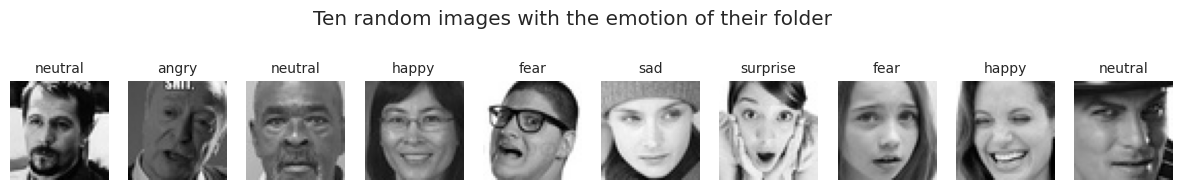

In [4]:
# Dataset First Look
display(df.head(8))
rs = np.random.RandomState(SEED)
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, rs.choice(len(df), 10, replace=False)):
    ax.imshow(X[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(df.label[i], fontsize=10)
    ax.axis("off")
plt.suptitle("Ten random images with the emotion of their folder", y=1.1)
plt.show()

### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print(f"images (rows): {len(df):,}   columns in the table: {df.shape[1]}   "
      f"pixels per image: {X.shape[1]} x {X.shape[2]} = {X.shape[1] * X.shape[2]:,}")
display(pd.crosstab(df["label"], df["folder"], margins=True, margins_name="total"))

images (rows): 35,887   columns in the table: 6   pixels per image: 48 x 48 = 2,304


folder,train,validation,total
label,,,
angry,3993,960,4953
disgust,436,111,547
fear,4103,1018,5121
happy,7164,1825,8989
neutral,4982,1216,6198
sad,4938,1139,6077
surprise,3205,797,4002
total,28821,7066,35887


### Dataset Information

In [6]:
# Dataset Info
df.info()
print()
print(df[["width", "height", "mode"]].value_counts().rename("images"))
print(f"\npixel values from {X.min()} to {X.max()}, stored as {X.dtype}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   file    35887 non-null  object
 1   folder  35887 non-null  object
 2   label   35887 non-null  object
 3   width   35887 non-null  int64 
 4   height  35887 non-null  int64 
 5   mode    35887 non-null  object
dtypes: int64(2), object(4)
memory usage: 1.6+ MB

width  height  mode
48     48      L       35887
Name: images, dtype: int64

pixel values from 0 to 255, stored as uint8


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
# Numbers per image (brightness, contrast, sharpness, edge strength by face region ...) and an md5 hash
# of the pixels, so two files with exactly the same picture get the same hash.
stats_df = deepfer.image_stats(X)
df = pd.concat([df, stats_df], axis=1)

print("repeated file paths:", df["file"].duplicated().sum())
by_hash = df.groupby("hash")
size = by_hash.size()
print(f"pixel-identical pictures: {(size > 1).sum():,} groups with {int((size[size > 1] - 1).sum()):,} extra copies")
print("groups that appear in both the train and the validation folder:", int((by_hash["folder"].nunique() > 1).sum()))
print("groups whose copies carry different emotion labels:", int((by_hash["label"].nunique() > 1).sum()))
print("largest group:", size.max(), "copies of the same picture")

repeated file paths: 0
pixel-identical pictures: 1,516 groups with 1,853 extra copies
groups that appear in both the train and the validation folder: 510
groups whose copies carry different emotion labels: 57
largest group: 12 copies of the same picture


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print("empty cells in the table:", int(df.isnull().sum().sum()))
print("files that could not be read: 0 (all", f"{len(df):,}", "opened)")
blank = df["contrast"] < 5
print("blank pictures (almost one colour, pixel standard deviation below 5):", int(blank.sum()))
non_face = pd.read_csv("data/non_face_images.csv")
print("pictures that are not faces (icons, warning signs, 'image removed' text), checked by eye:", len(non_face))

empty cells in the table: 0
files that could not be read: 0 (all 35,887 opened)
blank pictures (almost one colour, pixel standard deviation below 5): 14
pictures that are not faces (icons, warning signs, 'image removed' text), checked by eye: 58


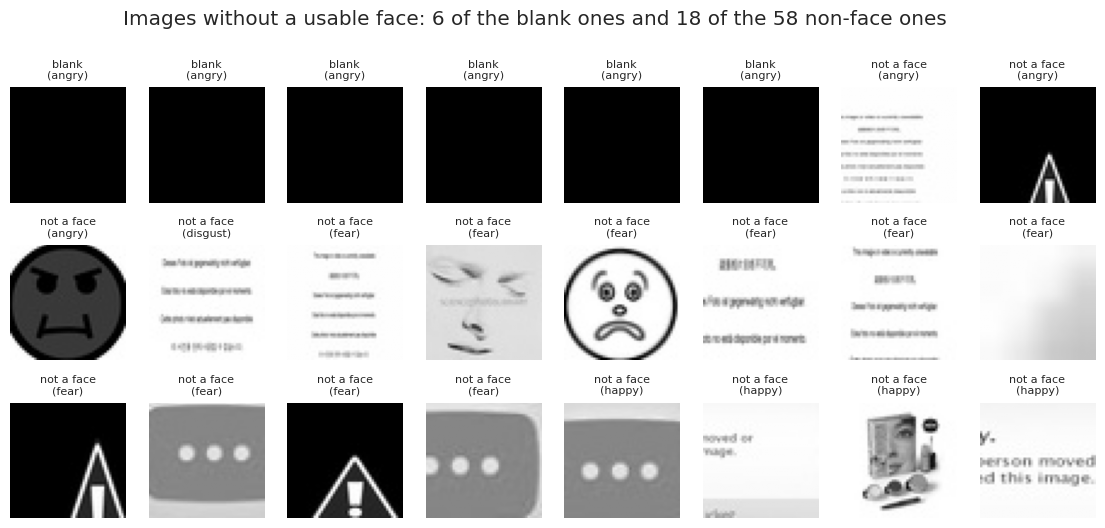

In [9]:
# Visualizing the missing values
# In an image dataset a "missing value" is a picture with no usable face. These are examples of both kinds.
show = list(df.index[blank][:6]) + list(df.index[df["file"].isin(non_face["file"])][:18])
fig, axes = plt.subplots(3, 8, figsize=(14, 5.8))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(("blank" if blank[i] else "not a face") + f"\n({df.label[i]})", fontsize=8)
    ax.axis("off")
plt.suptitle("Images without a usable face: 6 of the blank ones and 18 of the 58 non-face ones", y=1.0)
save("data_missing_faces.png")

### What did you know about your dataset?

- There are **35,887 images**, all 48x48 pixels in grayscale (mode L), so there is nothing to resize or convert. The labels come from the folder names: 28,821 pictures in `train` and 7,066 in `validation`.
- The table has no empty cells and every file opens. In an image dataset the missing values are pictures without a usable face: **14 blank pictures** and **58 that are not faces** at all (icons, warning signs, "this image has been removed" text).
- **Duplicates are the big problem.** Comparing a hash of the pixels finds 1,516 groups of identical pictures with 1,853 extra copies (one picture appears 12 times). 510 groups are in both the train and the validation folder, which would leak test answers into training, and 57 groups carry different emotion labels for the same picture.
- The classes are imbalanced: happy has 8,989 pictures, disgust only 547.
- The emotions are spread over both folders in very similar shares, so the validation folder can serve as a fair test set.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print(list(df.columns))

['file', 'folder', 'label', 'width', 'height', 'mode', 'brightness', 'contrast', 'sharpness', 'entropy', 'edge_eyes', 'edge_nose', 'edge_mouth', 'asymmetry', 'flat_share', 'hash']


In [11]:
# Dataset Describe
STAT_COLS = ["brightness", "contrast", "sharpness", "entropy", "edge_eyes", "edge_nose", "edge_mouth", "asymmetry", "flat_share"]
df[STAT_COLS].describe().round(2)

,brightness,contrast,sharpness,entropy,edge_eyes,edge_nose,edge_mouth,asymmetry,flat_share
count,35887.00,35887.00,35887.00,35887.00,35887.00,35887.00,35887.00,35887.00,35887.00
mean,129.38,54.08,2298.48,7.25,19.86,17.05,18.94,49.23,0.10
std,33.52,13.65,1543.45,0.41,5.71,6.49,6.13,19.68,0.06
min,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.02
25%,106.78,44.55,1392.66,7.07,15.98,12.40,14.72,35.21,0.07
50%,129.54,53.67,2025.41,7.32,19.44,16.11,18.33,46.71,0.09
75%,152.64,63.16,2842.10,7.50,23.23,20.63,22.48,60.34,0.12
max,247.95,113.93,32713.60,7.89,65.55,67.50,64.23,171.73,1.00


### Variables Description 

| Variable | Meaning |
|---|---|
| `file` | path of the picture: folder / emotion / file name |
| `folder` | `train` or `validation` (the validation folder is my test set) |
| `label` | the emotion, the target: angry, disgust, fear, happy, neutral, sad, surprise |
| `width`, `height`, `mode` | picture size and colour mode (always 48, 48, L = grayscale) |
| the pixels (array `X`) | 48 x 48 = 2,304 grey values from 0 (black) to 255 (white), the real input of the models |
| `brightness` | mean grey value of the picture |
| `contrast` | standard deviation of the grey values |
| `sharpness` | variance of the Laplacian (low = blurry) |
| `entropy` | how many different grey levels are used, in bits |
| `edge_eyes`, `edge_nose`, `edge_mouth` | mean edge strength (gradient size) in the band of the brows and eyes, the nose and the mouth |
| `asymmetry` | mean difference between the face and its mirror image |
| `flat_share` | share of pixels close to the most common grey value (high for icons and text) |
| `hash` | md5 of the pixels, equal for identical pictures |

The image statistics are not model inputs. They describe the data, find problems (blank pictures, non-faces, duplicates) and test hypotheses. The models learn from the pixels.

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
display(df[["file", "folder", "label", "width", "height", "mode", "hash"]].nunique().rename("unique values").to_frame())
print(df["label"].value_counts())

,unique values
file,35887
folder,2
label,7
width,1
height,1
mode,1
hash,34034


label
happy       8989
neutral     6198
sad         6077
fear        5121
angry       4953
surprise    4002
disgust      547
Name: count, dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

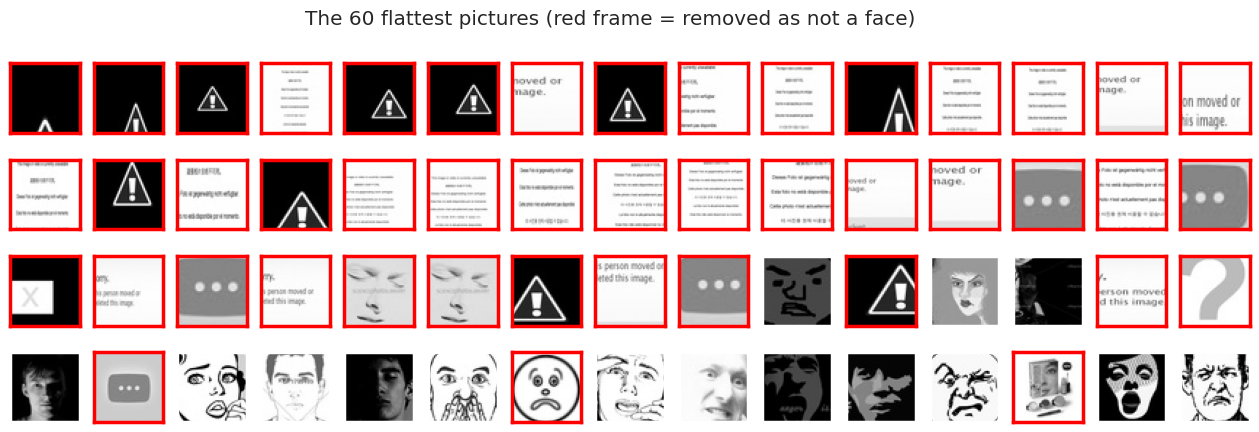

folder,train,validation,total
status,,,
blank image,11,3,14
copy of a test image,627,0,627
duplicate in the same folder,1042,79,1121
kept,26967,6952,33919
not a face,45,13,58
"same image, different labels",129,19,148
total,28821,7066,35887


clean pictures: 33,919 of 35,887 (94.5%)
train 22,921 | validation 4,046 | test 6,952


In [13]:
# Write your code to make your dataset analysis ready.

# 1) How the non-face pictures were found: icons and "image removed" banners are mostly one flat colour,
#    so I ranked all pictures by the share of pixels close to their most common grey value and looked
#    at the 250 flattest ones by eye. The 58 that are not faces are listed in data/non_face_images.csv.
cand = df[df["contrast"] >= 5].sort_values("flat_share", ascending=False).head(60)
flagged = set(non_face["file"])
fig, axes = plt.subplots(4, 15, figsize=(16, 4.8))
for ax, (i, row) in zip(axes.ravel(), cand.iterrows()):
    ax.imshow(X[i], cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color("red" if row["file"] in flagged else "white"); sp.set_linewidth(2.5)
plt.suptitle("The 60 flattest pictures (red frame = removed as not a face)", y=0.98)
save("wrangling_flat_candidates.png")

# 2) Apply the cleaning rules in order (see deepfer.clean_dataset)
df = deepfer.clean_dataset(df, non_face["file"])
df["status"] = df["drop_reason"].replace("", "kept")
display(pd.crosstab(df["status"], df["folder"], margins=True, margins_name="total"))

# 3) The clean data, the integer label of every picture and the three splits.
#    The validation folder is kept apart as the TEST set (never used for any choice). From the train
#    folder 15% goes to a VALIDATION set for early stopping and model choice, stratified by emotion.
LABEL_ID = {c: i for i, c in enumerate(CLASSES)}
Y = df["label"].map(LABEL_ID).to_numpy()
clean = df[df["drop_reason"] == ""].copy()
te_idx = clean.index[clean["folder"] == "validation"].to_numpy()
pool = clean[clean["folder"] == "train"]
tr_idx, va_idx = train_test_split(pool.index.to_numpy(), test_size=0.15, stratify=pool["label"], random_state=SEED)
clean["split"] = "train"
clean.loc[va_idx, "split"] = "validation"
clean.loc[te_idx, "split"] = "test"
print(f"clean pictures: {len(clean):,} of {len(df):,} ({len(clean) / len(df):.1%})")
print(f"train {len(tr_idx):,} | validation {len(va_idx):,} | test {len(te_idx):,}")

### What all manipulations have you done and insights you found?

**Manipulations, in this order:**
1. **Blank pictures removed (14):** pixel standard deviation below 5, almost one flat colour.
2. **Non-face pictures removed (58):** I ranked all pictures by `flat_share` and checked the 250 flattest by eye. Icons and text banners are mostly one colour, so they float to the top. The 58 I found are listed in `data/non_face_images.csv` (red frames in the figure).
3. **Same picture with different labels removed (148 copies):** when the same picture is saved as fear and as surprise, there is no right answer to learn, so all copies go.
4. **Training copies of test pictures removed (627):** otherwise the model would be tested on pictures it has already seen.
5. **Repeated copies in the same folder removed (1,121):** they give some faces two or more votes in training and in the test.
6. **Splits:** the validation folder becomes the test set (6,952 pictures). The train folder is split 85/15, stratified by emotion, into training (22,921) and validation (4,046). The split is made here, right after cleaning, so every later choice only looks at training rows.

**Insights:** 94.5% of the pictures survive. Duplicates were far more common than real junk. Surprise lost 19.1% of its pictures and disgust 16.5%, mostly duplicates, so these classes were the most inflated by copies. The label conflicts are mostly between emotions that really look alike (fear and surprise, angry and sad), which is the first sign of where a model will struggle.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - How many faces per emotion?

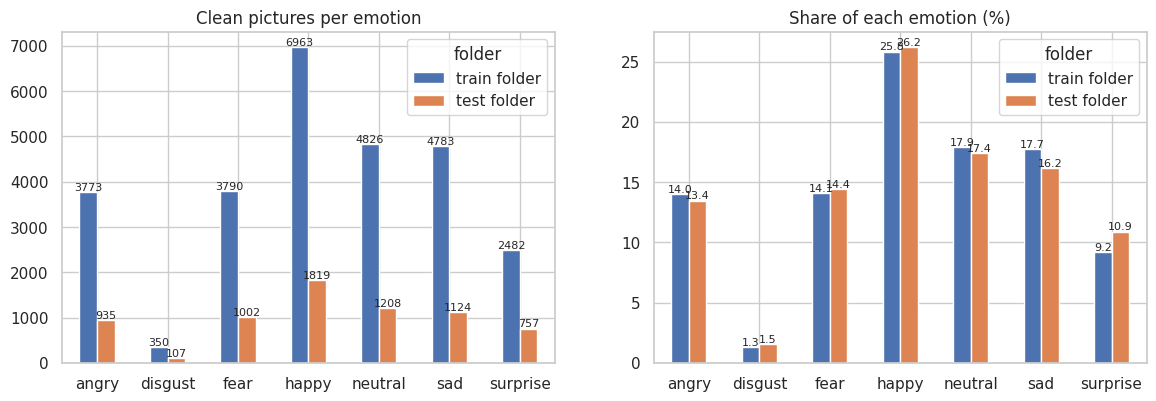

folder    train folder  test folder
label                              
angry             14.0         13.4
disgust            1.3          1.5
fear              14.1         14.4
happy             25.8         26.2
neutral           17.9         17.4
sad               17.7         16.2
surprise           9.2         10.9
largest / smallest class: 19.9


In [14]:
# Chart - 1 visualization code
# Univariate: how many clean pictures each emotion has, in the train folder and in the test folder
cnt = pd.crosstab(clean["label"], clean["folder"]).rename(columns={"train": "train folder", "validation": "test folder"})
share = cnt / cnt.sum() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
cnt.plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"], rot=0)
for c in ax[0].containers:
    ax[0].bar_label(c, fontsize=8)
ax[0].set_title("Clean pictures per emotion")
ax[0].set_xlabel("")
share.plot.bar(ax=ax[1], color=["#4C72B0", "#DD8452"], rot=0)
for c in ax[1].containers:
    ax[1].bar_label(c, fmt="%.1f", fontsize=8)
ax[1].set_title("Share of each emotion (%)")
ax[1].set_xlabel("")
save("chart01_class_balance.png")
print(share.round(1))
print("largest / smallest class:", round(cnt["train folder"].max() / cnt["train folder"].min(), 1))

##### 1. Why did you pick the specific chart?

A grouped bar chart puts the two folders side by side, and the second panel with shares shows whether the test folder has the same mix as the train folder. Class balance is the first thing to check for a classification problem.

##### 2. What is/are the insight(s) found from the chart?

Happy is the largest class with about 26% of the pictures, followed by neutral and sad (17-18%), fear and angry (14%) and surprise (9-11%). Disgust is tiny: 1.3% of the train folder and 1.5% of the test folder, so happy has about 20 times more pictures. The shares of the two folders differ by less than 2 points for every emotion.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It tells me that accuracy alone would hide a model that ignores disgust, so I report macro F1 (every emotion counts the same) and test class weights. The negative side for a product: disgust will always be the weakest class with so few examples, so any use that depends on detecting disgust (for example spotting reactions to a bad product) needs more data first.

#### Chart - 2 - What the faces look like

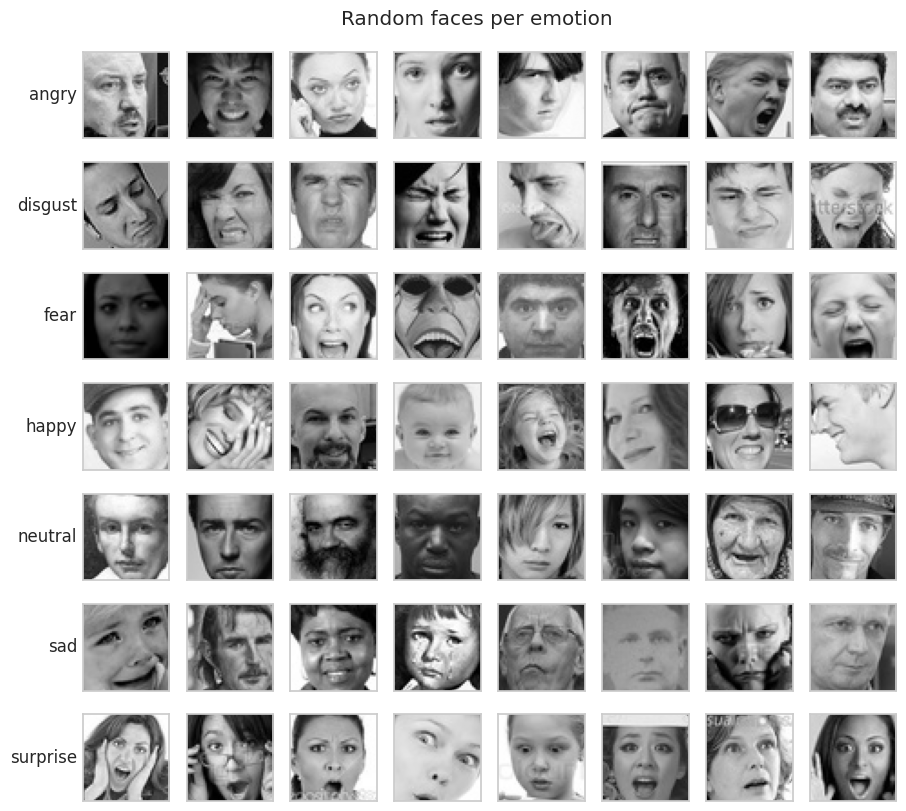

In [15]:
# Chart - 2 visualization code
# Univariate (the images themselves): eight random clean faces of every emotion
rs = np.random.RandomState(1)
fig, axes = plt.subplots(7, 8, figsize=(10.5, 9.8))
for r, c in enumerate(CLASSES):
    for k, i in enumerate(rs.choice(clean.index[clean["label"] == c], 8, replace=False)):
        axes[r, k].imshow(X[i], cmap="gray", vmin=0, vmax=255)
        axes[r, k].set_xticks([]); axes[r, k].set_yticks([])
    axes[r, 0].set_ylabel(c, fontsize=12, rotation=0, ha="right", va="center")
plt.suptitle("Random faces per emotion", y=0.92)
save("chart02_sample_faces.png")

##### 1. Why did you pick the specific chart?

Before any statistics it helps to look at the pictures themselves. A grid of random faces per emotion shows how varied the data is and how hard some classes are to tell apart even for a person.

##### 2. What is/are the insight(s) found from the chart?

The faces vary a lot: babies and old people, different skin tones, glasses, hands on the face, side views, strong shadows and watermarks. Some emotions are easy to see (happy smiles, surprised open mouths), while many fear, sad and angry faces look alike and a few disgust faces look like anger. Some labels look questionable even to me.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The variety is good for a real product because real users look just as different. But it also shows the ceiling: if a person can't be sure whether a face shows fear or sadness, a model won't be either. For a business this means using the model to see trends over many faces, not to judge one person from one photo.

#### Chart - 3 - The average face of each emotion

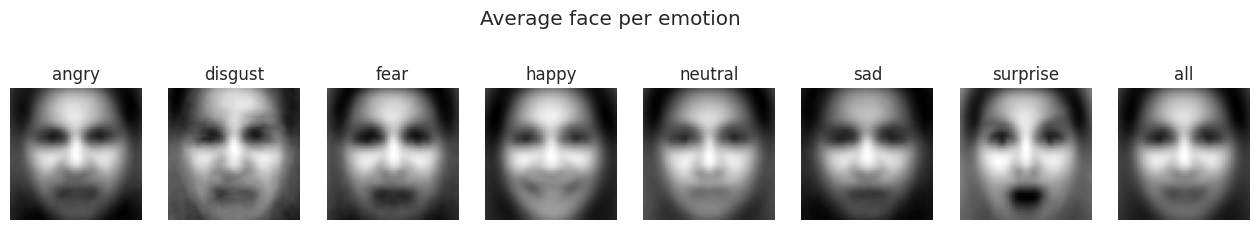

In [16]:
# Chart - 3 visualization code
# Multivariate: the average face of every emotion (all 2,304 pixels averaged per class)
mean_face = {c: X[clean.index[clean["label"] == c]].mean(0) for c in CLASSES}
overall = X[clean.index].mean(0)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, c in zip(axes, CLASSES + ["all"]):
    ax.imshow(overall if c == "all" else mean_face[c], cmap="gray")
    ax.set_title(c)
    ax.axis("off")
plt.suptitle("Average face per emotion", y=1.05)
save("chart03_average_faces.png")

##### 1. Why did you pick the specific chart?

Averaging all faces of one emotion removes the person, the lighting and the background and leaves what the emotion has in common. It is a simple way to see the typical shape of each expression.

##### 2. What is/are the insight(s) found from the chart?

Even averaged over thousands of people the expressions are clear. The happy average face has a wide bright mouth and raised cheeks, surprise has a dark open mouth and a bright face, sad and neutral are flatter and darker, and angry and disgust show a tense lower face. Fear is a blurry mix of surprise and sadness, which already hints why it is hard.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It confirms that the faces are roughly aligned (eyes and mouth at the same place), so a CNN can learn where to look. It also shows that the mouth region carries a lot of the signal, which matters for a product used by people wearing masks.

#### Chart - 4 - Where each emotion differs from the average face

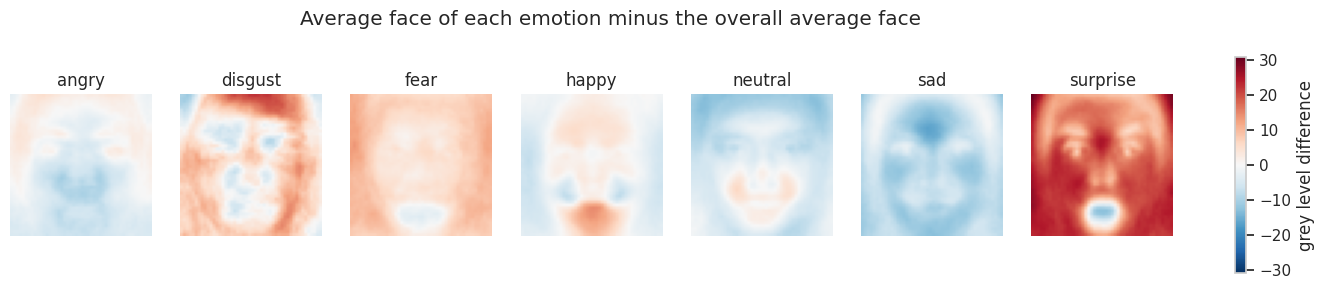

angry     eyes band  -0.4   mouth band  -6.6
disgust   eyes band  +3.3   mouth band  +3.5
fear      eyes band  +6.3   mouth band  +3.1
happy     eyes band  -0.1   mouth band  +2.9
neutral   eyes band  -6.0   mouth band  -0.2
sad       eyes band  -7.4   mouth band  -8.9
surprise  eyes band +15.8   mouth band +13.2


In [17]:
# Chart - 4 visualization code
# Bivariate (pixel value vs emotion): where each emotion's average face is brighter (red) or darker (blue)
# than the average face of all emotions
diff = {c: mean_face[c] - overall for c in CLASSES}
lim = max(np.abs(d).max() for d in diff.values())
fig, axes = plt.subplots(1, 7, figsize=(16, 2.8))
for ax, c in zip(axes, CLASSES):
    im = ax.imshow(diff[c], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(c)
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.012, label="grey level difference")
plt.suptitle("Average face of each emotion minus the overall average face", y=1.05)
save("chart04_face_difference_maps.png")
for c in CLASSES:
    d = diff[c]
    print(f"{c:9s} eyes band {d[10:24].mean():+5.1f}   mouth band {d[31:45, 10:38].mean():+5.1f}")

##### 1. Why did you pick the specific chart?

The average faces of chart 3 look alike at first glance. Subtracting the overall average face shows only the differences, and a red-blue colour map makes it clear where each emotion is lighter or darker.

##### 2. What is/are the insight(s) found from the chart?

- **Surprise** is much brighter than average almost everywhere (+15.8 grey levels in the eye band, +13.2 in the mouth band), with a dark spot in the open mouth.
- **Sad** is darker everywhere (-7.4 eyes, -8.9 mouth) and **neutral** darker around the eyes (-6.0).
- **Angry** is darker in the mouth band (-6.6), from pressed lips and shadows.
- **Happy** is brighter around the mouth (+2.9) from the teeth, and **fear** brighter around the eyes (+6.3) from the widened eyes.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The differences sit exactly where people show emotions (eyes, brows, mouth), so a model has real facial signals to learn. The warning is that part of the difference is overall brightness (surprise faces are brighter as a whole), which a model could use as a shortcut that fails in other lighting. That is why lighting augmentation and the lighting tests are part of the project.

#### Chart - 5 - Brightness by emotion

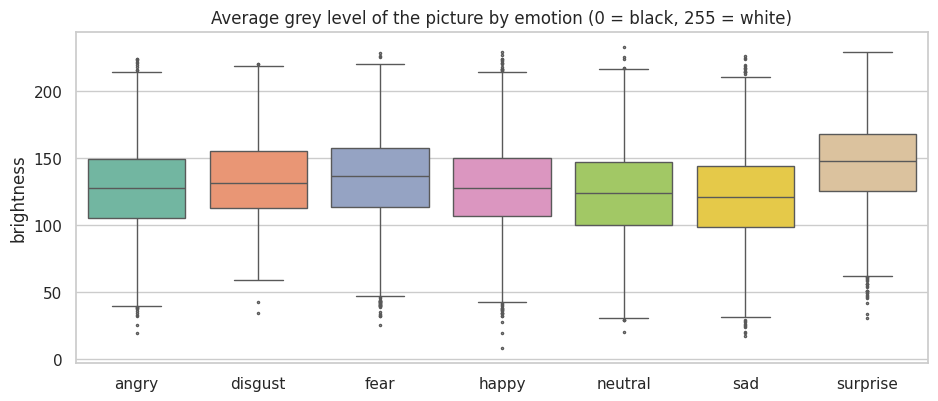

label
sad         121.000000
neutral     123.699997
angry       127.300003
happy       127.599998
disgust     131.300003
fear        136.600006
surprise    147.699997
Name: brightness, dtype: float32


In [18]:
# Chart - 5 visualization code
# Numerical vs categorical: brightness of the picture by emotion
order = CLASSES
fig, ax = plt.subplots(figsize=(11, 4.3))
sns.boxplot(data=clean, x="label", y="brightness", order=order, palette="Set2", fliersize=1.5, ax=ax)
ax.set_title("Average grey level of the picture by emotion (0 = black, 255 = white)")
ax.set_xlabel("")
save("chart05_brightness_by_emotion.png")
print(clean.groupby("label")["brightness"].median().round(1).sort_values())

##### 1. Why did you pick the specific chart?

A box plot compares the spread and the median of one number across the seven classes at once. Brightness tells me whether lighting differs between the emotions, which a model could wrongly learn instead of the expression.

##### 2. What is/are the insight(s) found from the chart?

Surprise pictures are the brightest (median grey level 147.7) and sad the darkest (121.0), with fear at 136.6 and the rest between 124 and 131. The boxes overlap heavily though: every emotion has dark and bright pictures.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, as a warning. A model could learn that bright means surprise, which would make it worse in a bright office or a dark room. The data augmentation changes the brightness of every training picture by up to 20% for this reason, and the stress test later checks dark and bright faces. It is tested formally in hypothesis 1.

#### Chart - 6 - Contrast and sharpness by emotion

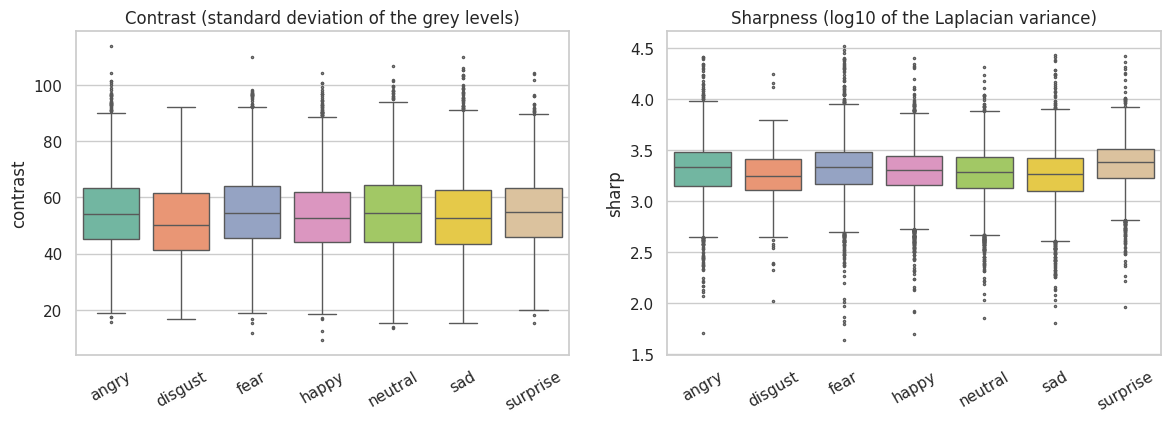

label
angry       0.051
disgust     0.068
fear        0.045
happy       0.039
neutral     0.061
sad         0.068
surprise    0.029
Name: share of blurriest 5%, dtype: float64


In [19]:
# Chart - 6 visualization code
# Numerical vs categorical: contrast and sharpness by emotion
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.boxplot(data=clean, x="label", y="contrast", order=order, palette="Set2", fliersize=1.5, ax=ax[0])
ax[0].set_title("Contrast (standard deviation of the grey levels)")
sns.boxplot(data=clean.assign(sharp=np.log10(clean["sharpness"] + 1)), x="label", y="sharp", order=order,
            palette="Set2", fliersize=1.5, ax=ax[1])
ax[1].set_title("Sharpness (log10 of the Laplacian variance)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=30)
save("chart06_contrast_sharpness.png")
print((clean["sharpness"] < clean["sharpness"].quantile(0.05)).groupby(clean["label"]).mean().round(3).rename("share of blurriest 5%"))

##### 1. Why did you pick the specific chart?

Contrast and sharpness are the two other basic quality measures of a photo. Two box plots next to each other show if some emotions come with blurrier or flatter pictures.

##### 2. What is/are the insight(s) found from the chart?

Contrast is very similar for all emotions (medians around 50-55). Sharpness is also similar, but the blurriest 5% of pictures are more common for disgust and sad (6.8% each) and least common for surprise (2.9%).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The quality of the pictures does not depend much on the emotion, so the model can't cheat with it. Blurry pictures exist in every class, which is close to real webcam conditions, so I keep them and measure later how much blur hurts the model.

#### Chart - 7 - Edge strength in the eye, nose and mouth regions

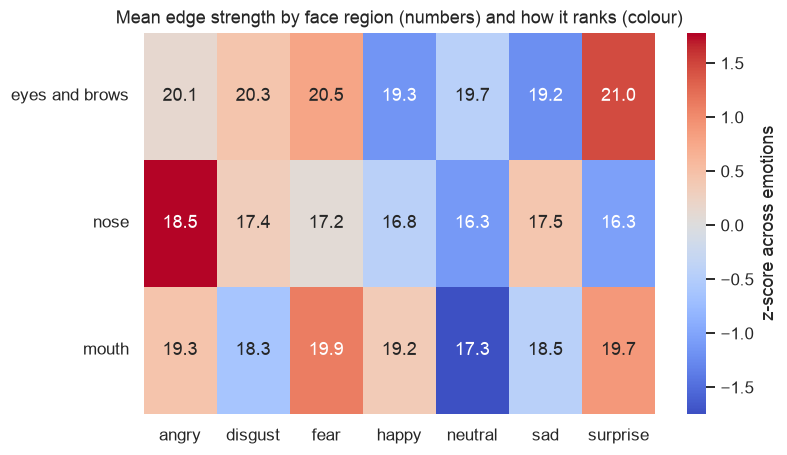

In [20]:
# Chart - 7 visualization code
# Bivariate: how strong the edges are in the eye, nose and mouth bands of the face, per emotion
reg = clean.groupby("label")[["edge_eyes", "edge_nose", "edge_mouth"]].mean().loc[CLASSES]
z = (reg - reg.mean()) / reg.std()
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(z.T, annot=reg.T.values, fmt=".1f", cmap="coolwarm", center=0, cbar_kws={"label": "z-score across emotions"}, ax=ax)
ax.set_yticklabels(["eyes and brows", "nose", "mouth"], rotation=0)
ax.set_title("Mean edge strength by face region (numbers) and how it ranks (colour)")
ax.set_xlabel("")
save("chart07_edges_by_region.png")

##### 1. Why did you pick the specific chart?

A heatmap fits a small table of 3 face regions by 7 emotions. The numbers show the real edge strength and the colour shows how each emotion ranks, so I can see which region moves for which emotion.

##### 2. What is/are the insight(s) found from the chart?

Surprise has the strongest edges around the eyes and brows (21.0, raised brows and wide eyes) followed by fear (20.5). Angry has the strongest edges around the nose (18.5, the wrinkled nose and frown). Fear, surprise, angry and happy have strong mouth edges (19.2-19.9) from open mouths and teeth, while neutral is the calmest in every region (mouth 17.3, nose 16.3).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Each emotion moves its own part of the face, which is what a CNN can pick up with local filters. It also says which regions a product must see clearly: a camera angle that cuts off the mouth or hides the brows will lose information for specific emotions.

#### Chart - 8 - Removed pictures by reason and emotion

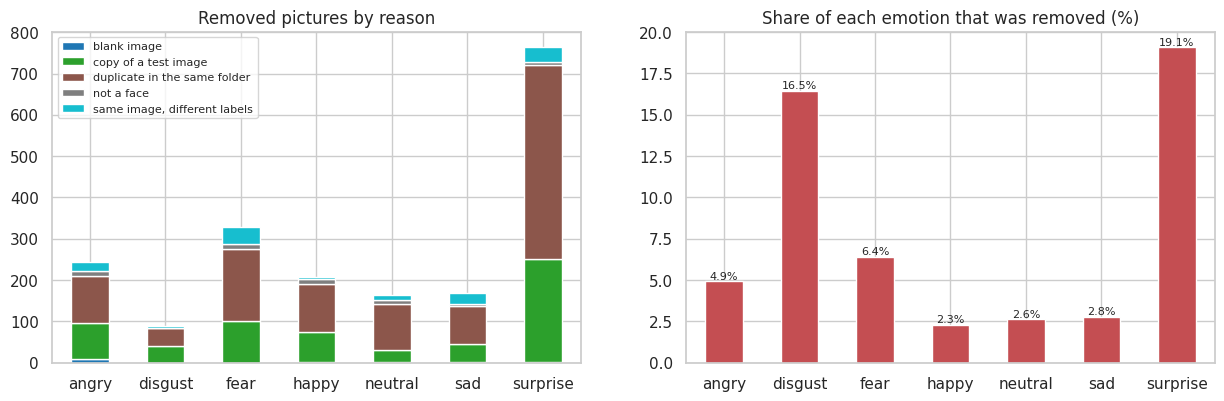

drop_reason
duplicate in the same folder    1121
copy of a test image             627
same image, different labels     148
not a face                        58
blank image                       14
dtype: int64


In [21]:
# Chart - 8 visualization code
# Categorical vs categorical: the pictures that were removed, by reason and emotion
rem = pd.crosstab(df.loc[df["drop_reason"] != "", "label"], df.loc[df["drop_reason"] != "", "drop_reason"]).loc[CLASSES]
rate = (df["drop_reason"] != "").groupby(df["label"]).mean().loc[CLASSES] * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
rem.plot.bar(stacked=True, ax=ax[0], colormap="tab10", rot=0)
ax[0].set_title("Removed pictures by reason")
ax[0].legend(fontsize=8)
ax[0].set_xlabel("")
rate.plot.bar(ax=ax[1], color="#C44E52", rot=0)
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", fontsize=8)
ax[1].set_title("Share of each emotion that was removed (%)")
ax[1].set_xlabel("")
save("chart08_removed_by_reason.png")
print(rem.sum().sort_values(ascending=False))

##### 1. Why did you pick the specific chart?

A stacked bar chart shows both how many pictures each reason removed and how they are spread over the emotions, and the second panel turns it into a share so the small classes are not hidden.

##### 2. What is/are the insight(s) found from the chart?

Duplicates in the same folder (1,121) and training copies of test pictures (627) make up most of the removed pictures, far more than the 148 conflicting copies, 58 non-faces and 14 blank pictures. Surprise lost 19.1% and disgust 16.5% of their pictures, while happy, neutral and sad lost less than 3%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Without cleaning, the test score would be too high because the model would partly be tested on pictures it trained on, and surprise and disgust would look easier than they are. Honest scores matter for any business decision built on the model. The negative side is that disgust, already rare, lost more pictures.

#### Chart - 9 - Same picture, different labels

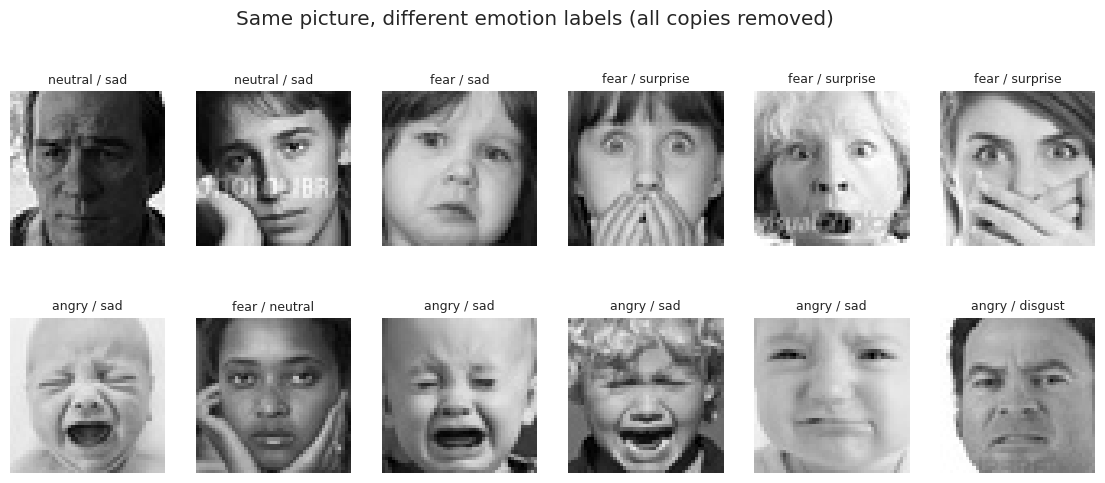

label
fear / surprise     12
angry / sad         10
fear / sad           8
angry / fear         8
fear / neutral       4
happy / surprise     4
neutral / sad        3
angry / neutral      2
Name: count, dtype: int64


In [22]:
# Chart - 9 visualization code
# Label noise: the same picture saved under two or more emotions
conf = df[df["drop_reason"] == "same image, different labels"]
groups = [g for _, g in conf.groupby("hash")][:12]
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
for ax, g in zip(axes.ravel(), groups):
    ax.imshow(X[g.index[0]], cmap="gray", vmin=0, vmax=255)
    labels = " / ".join(sorted(g["label"].unique()))
    ax.set_title(labels, fontsize=9)
    ax.axis("off")
plt.suptitle("Same picture, different emotion labels (all copies removed)", y=1.0)
save("chart09_conflicting_labels.png")
pairs = conf.groupby("hash")["label"].apply(lambda s: " / ".join(sorted(s.unique()))).value_counts()
print(pairs.head(8))

##### 1. Why did you pick the specific chart?

Label noise is hard to show with numbers alone. Showing the actual pictures with their two labels makes it clear why these copies had to go.

##### 2. What is/are the insight(s) found from the chart?

The same picture was labelled as two different emotions in 57 groups. The most common pairs are fear / surprise (12), angry / sad (10), fear / sad (8) and angry / fear (8). Looking at the pictures, both labels are often defensible: a hand over an open mouth can be fear or surprise.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that the labels themselves are noisy, which puts a ceiling on any model. For a business it means the model's output should be treated as an estimate. These same pairs later appear in the confusion matrix, so they are a weakness of the data, not only of the model.

#### Chart - 10 - What HOG features see

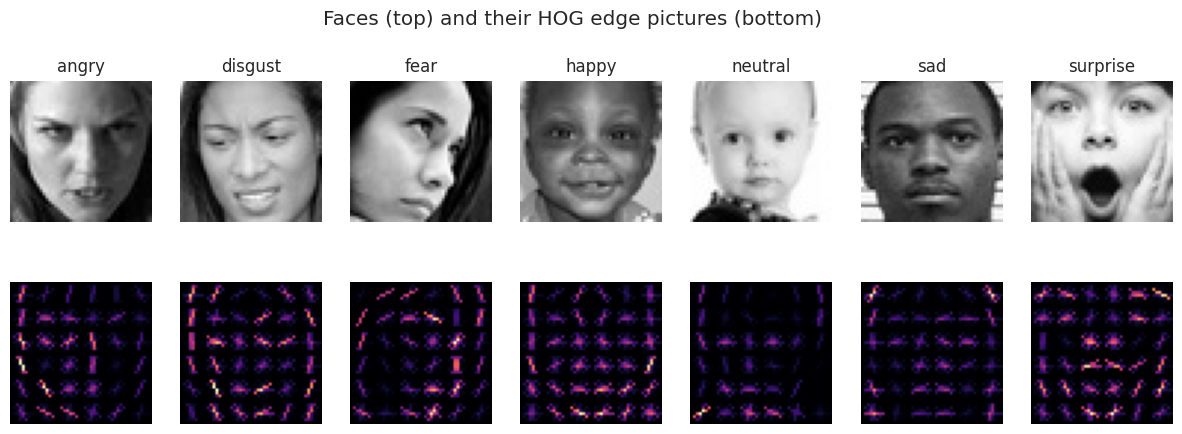

In [23]:
# Chart - 10 visualization code
# What the handcrafted features see: one face per emotion and its HOG picture (edge directions per 8x8 cell)
rs = np.random.RandomState(3)
fig, axes = plt.subplots(2, 7, figsize=(15, 4.8))
for k, c in enumerate(CLASSES):
    i = rs.choice(clean.index[clean["label"] == c])
    _, hog_img = hog(X[i], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    axes[0, k].imshow(X[i], cmap="gray"); axes[0, k].set_title(c); axes[0, k].axis("off")
    axes[1, k].imshow(hog_img, cmap="magma"); axes[1, k].axis("off")
plt.suptitle("Faces (top) and their HOG edge pictures (bottom)", y=1.0)
save("chart10_hog_examples.png")

##### 1. Why did you pick the specific chart?

HOG is the main handcrafted feature for the classic baseline. Showing a face next to its HOG picture explains what the baseline model actually gets as input.

##### 2. What is/are the insight(s) found from the chart?

HOG turns each 8x8 cell into a histogram of edge directions. The outlines of the eyes, brows, nose and mouth are visible in the HOG pictures, and the open mouth of surprise and the smile of happy stand out. Subtle differences like a slight frown are much weaker.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, as a baseline. HOG and LBP are cheap and explainable, and they show how far classic computer vision gets. If deep learning didn't beat them clearly, the extra cost of a CNN would not be worth it. It does, by more than 20 points.

#### Chart - 11 - Eigenfaces (pixel PCA)

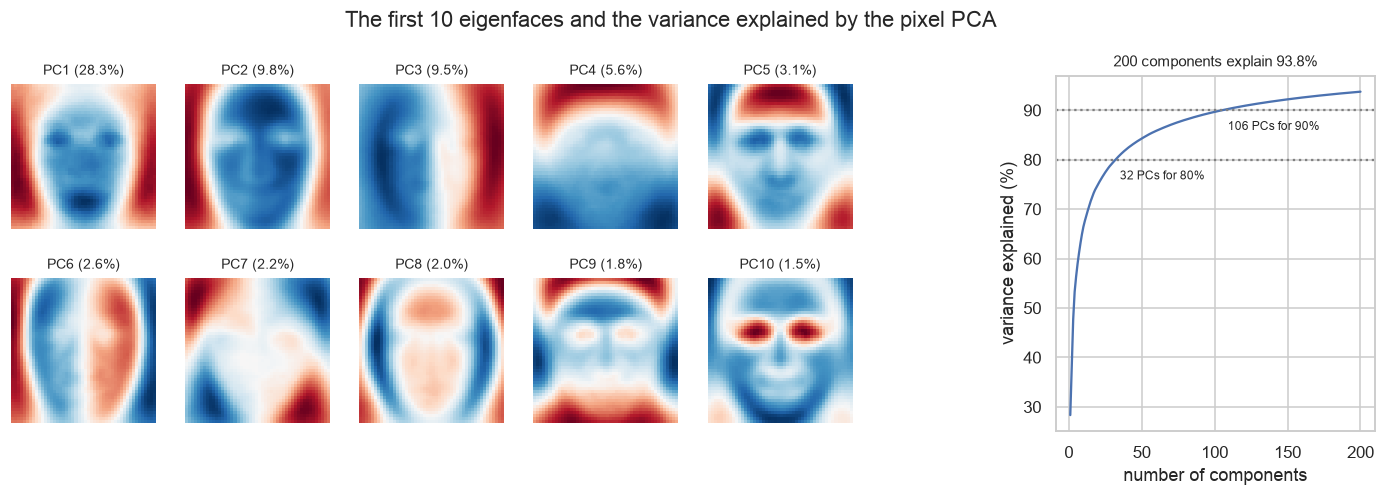

In [24]:
# Chart - 11 visualization code
# Eigenfaces: PCA on the raw pixels of the training rows. The first components are the main ways faces vary.
pix = X[tr_idx].reshape(len(tr_idx), -1).astype(np.float32) / 255
pca_pix = PCA(n_components=200, random_state=SEED).fit(pix)
cum = np.cumsum(pca_pix.explained_variance_ratio_)
fig = plt.figure(figsize=(16, 4.2))
for k in range(10):
    ax = fig.add_subplot(2, 8, k + 1 + (k // 5) * 3)
    ax.imshow(pca_pix.components_[k].reshape(48, 48), cmap="RdBu_r")
    ax.set_title(f"PC{k + 1} ({pca_pix.explained_variance_ratio_[k]:.1%})", fontsize=9)
    ax.axis("off")
ax = fig.add_subplot(1, 8, (7, 8))
ax.plot(np.arange(1, 201), cum * 100)
for t in (80, 90):
    n = int(np.searchsorted(cum, t / 100) + 1)
    ax.axhline(t, ls=":", c="grey"); ax.text(n + 3, t - 4, f"{n} PCs for {t}%", fontsize=8)
ax.set_xlabel("number of components"); ax.set_ylabel("variance explained (%)")
ax.set_title(f"200 components explain {cum[-1]:.1%}", fontsize=10)
plt.suptitle("The first 10 eigenfaces and the variance explained by the pixel PCA", y=1.02)
save("chart11_eigenfaces.png")

##### 1. Why did you pick the specific chart?

Eigenfaces show the main directions in which the 2,304 pixels vary together, and the curve of explained variance shows how much the pictures can be compressed. It is the standard way to look at the structure of face data.

##### 2. What is/are the insight(s) found from the chart?

The first eigenfaces mostly capture lighting, not emotion: PC1 (28.3% of the variance) is a bright face against a dark background, PC3 (9.5%) is light from one side. Only later components show eyes and mouth shapes. 32 components explain 80% of the pixel variance and 106 explain 90%; 200 components explain 93.8%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Most of the variation between pictures is lighting and pose, not emotion, which is why simple models on raw pixels do poorly and why lighting augmentation is useful. The negative side is that a model trained on studio-like pictures would struggle in unusual lighting.

#### Chart - 12 - t-SNE map of the handcrafted features

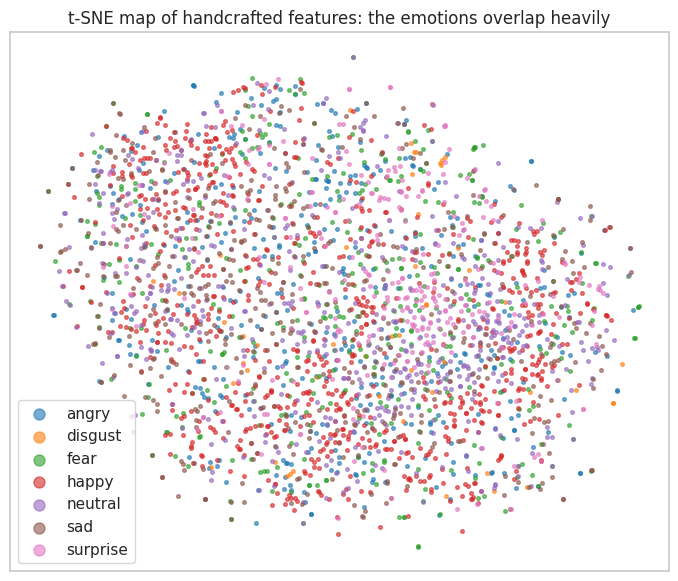

In [25]:
# Chart - 12 visualization code
# Multivariate: a 2D map (t-SNE) of the HOG + LBP features of 3,000 training faces, coloured by emotion
rs = np.random.RandomState(SEED)
sample = rs.choice(tr_idx, 1000 if QUICK else 3000, replace=False)
feat = deepfer.hog_lbp_features(X[sample])
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(
    PCA(50, random_state=SEED).fit_transform(StandardScaler().fit_transform(feat)))
fig, ax = plt.subplots(figsize=(8.5, 7))
pal = dict(zip(CLASSES, sns.color_palette("tab10", 7)))
for c in CLASSES:
    m = Y[sample] == LABEL_ID[c]
    ax.scatter(emb[m, 0], emb[m, 1], s=7, alpha=0.6, color=pal[c], label=c)
ax.legend(markerscale=3)
ax.set_title("t-SNE map of handcrafted features: the emotions overlap heavily")
ax.set_xticks([]); ax.set_yticks([])
save("chart12_tsne_hog.png")

##### 1. Why did you pick the specific chart?

t-SNE squeezes 1,060 features into a 2D map while keeping close points close. If the emotions formed separate islands, a simple model would be enough. This is a multivariate view of all features at once.

##### 2. What is/are the insight(s) found from the chart?

The emotions overlap heavily. Happy faces gather loosely in one area and surprise a little in another, but angry, fear, sad, neutral and disgust are mixed together everywhere.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that handcrafted features are not enough to separate the emotions, which justifies a deep learning model that learns its own features. It also sets expectations: even the best model will confuse fear, sad and angry.

#### Chart - 13 - Lighting conditions

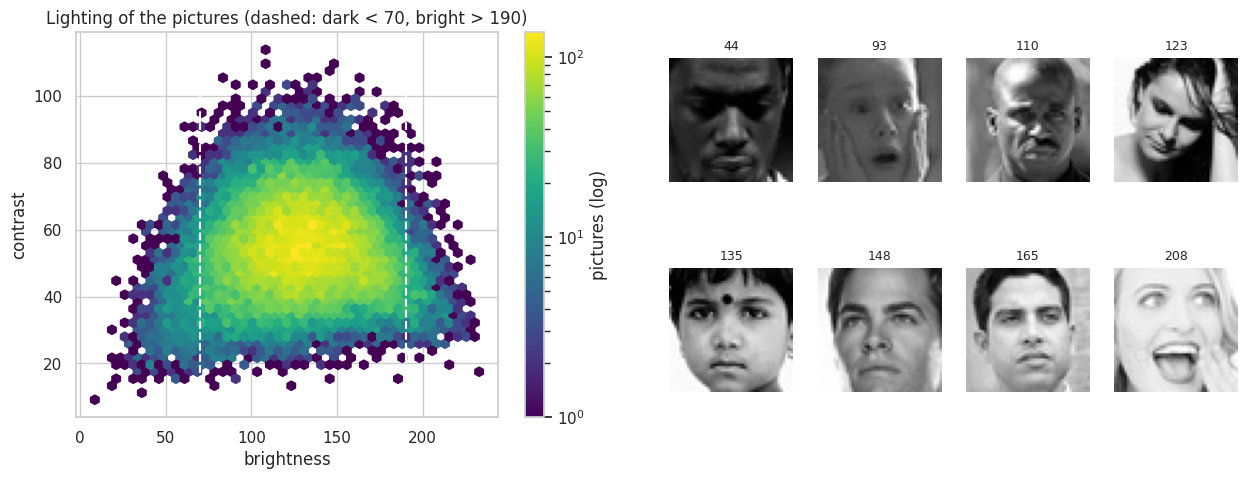

dark (<70): 4.0%   bright (>190): 3.1%   low contrast (<25): 0.9%


In [26]:
# Chart - 13 visualization code
# Lighting conditions: brightness against contrast for all clean pictures, with examples from dark to bright
fig = plt.figure(figsize=(15, 5))
ax = fig.add_subplot(1, 2, 1)
hb = ax.hexbin(clean["brightness"], clean["contrast"], gridsize=45, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="pictures (log)")
ax.axvline(70, c="w", ls="--"); ax.axvline(190, c="w", ls="--")
ax.set_xlabel("brightness"); ax.set_ylabel("contrast")
ax.set_title("Lighting of the pictures (dashed: dark < 70, bright > 190)")
q = clean["brightness"].quantile(np.linspace(0.005, 0.995, 8)).to_numpy()
for k, b in enumerate(q):
    i = (clean["brightness"] - b).abs().idxmin()
    a = fig.add_subplot(2, 8, 5 + k + (k // 4) * 4)
    a.imshow(X[i], cmap="gray", vmin=0, vmax=255); a.set_title(f"{clean.brightness[i]:.0f}", fontsize=9); a.axis("off")
save("chart13_lighting.png")
print(f"dark (<70): {(clean.brightness < 70).mean():.1%}   bright (>190): {(clean.brightness > 190).mean():.1%}   "
      f"low contrast (<25): {(clean.contrast < 25).mean():.1%}")

##### 1. Why did you pick the specific chart?

A hexbin plot handles 34,000 points without turning into a blob, and the strip of example faces shows what the numbers mean. Lighting is one of the named challenges of the project.

##### 2. What is/are the insight(s) found from the chart?

Most pictures have medium brightness (100-160) and contrast (40-70), but there is a wide spread: 4.0% are dark (below 70) and 3.1% very bright (above 190), while only 0.9% have very low contrast. The example strip shows faces in deep shadow next to over-exposed ones.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The training data already contains some hard lighting, which helps the model in real rooms. But dark and bright pictures are only about 7% of the data, so poor lighting remains a risk for a product. That is why I test CLAHE (histogram equalisation) as a fix for dark faces later.

#### Chart - 14 - Correlation Heatmap

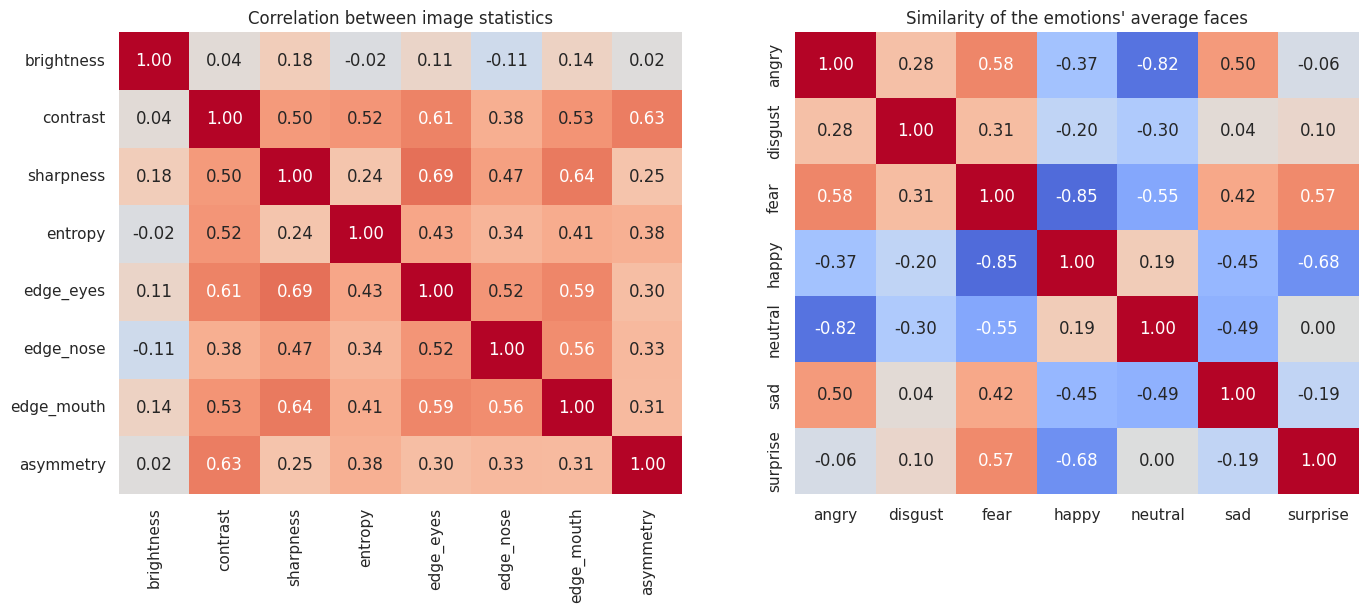

In [27]:
# Correlation Heatmap visualization code
# Left: correlation between the image statistics. Right: how similar the average faces of the emotions are
# (Pearson correlation of the 2,304 pixels of the average faces after removing the overall average face).
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
corr = clean[STAT_COLS[:-1]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Correlation between image statistics")
sim = pd.DataFrame(np.corrcoef(np.stack([diff[c].ravel() for c in CLASSES])), index=CLASSES, columns=CLASSES)
sns.heatmap(sim, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Similarity of the emotions' average faces")
save("chart14_correlation.png")

##### 1. Why did you pick the specific chart?

A correlation heatmap is the quickest way to see which numbers move together. The second panel uses the same idea on the average faces, which tells me which emotions look alike before any model is trained.

##### 2. What is/are the insight(s) found from the chart?

- **Image statistics:** contrast goes together with edge strength (0.61 with the eye band, 0.53 with the mouth band) and sharpness with edges (0.69 and 0.64). Brightness is almost unrelated to everything else (all below 0.2), so dark faces are not automatically blurry or flat.
- **Average faces:** angry and fear (0.58), fear and surprise (0.57) and angry and sad (0.50) look alike. Happy is the opposite of fear (-0.85) and surprise (-0.68), and neutral the opposite of angry (-0.82).

#### Chart - 15 - Pair Plot 

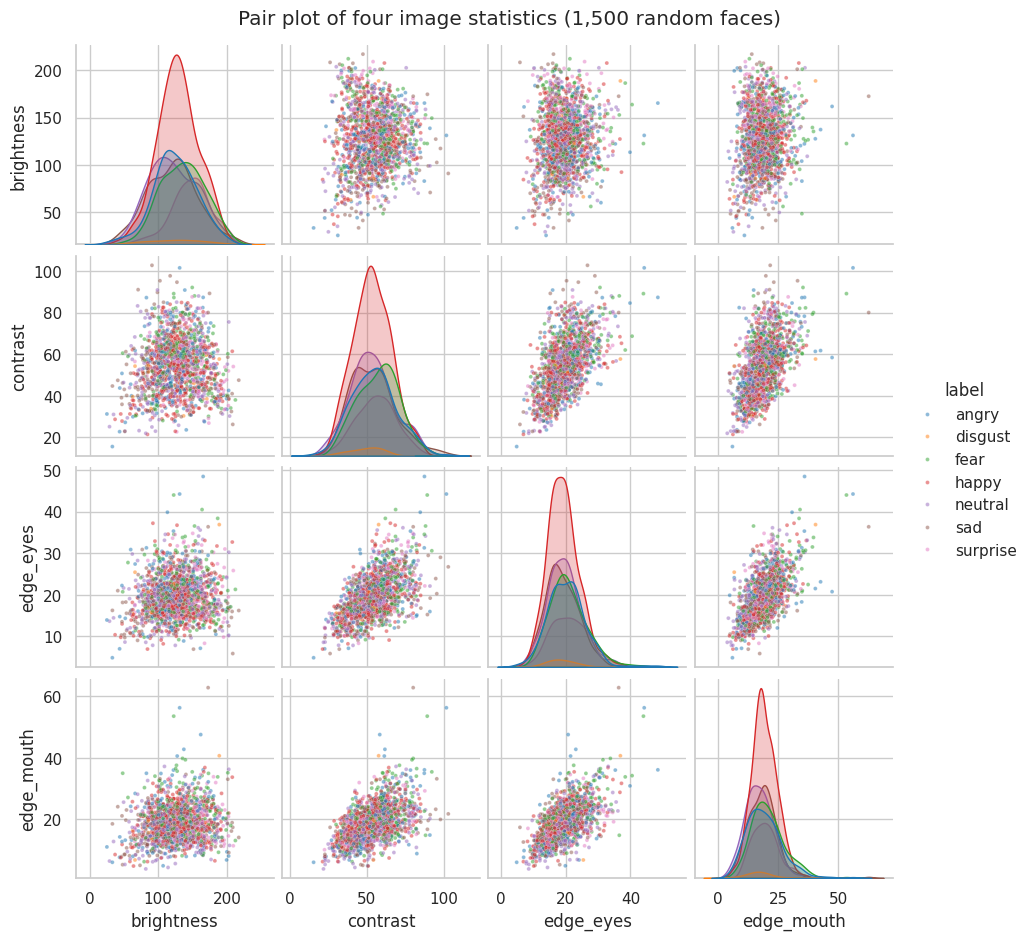

In [28]:
# Pair Plot visualization code
rs = np.random.RandomState(SEED)
pp = clean.loc[rs.choice(clean.index, 1500, replace=False), ["brightness", "contrast", "edge_eyes", "edge_mouth", "label"]]
g = sns.pairplot(pp, hue="label", hue_order=CLASSES, palette="tab10", plot_kws={"s": 8, "alpha": 0.5}, diag_kind="kde", height=2.3)
g.fig.suptitle("Pair plot of four image statistics (1,500 random faces)", y=1.02)
save("chart15_pairplot.png")

##### 1. Why did you pick the specific chart?

A pair plot shows every pair of the four statistics as a scatter plot and the distribution of each one per emotion on the diagonal. It is the multivariate check of whether simple image statistics could separate the emotions.

##### 2. What is/are the insight(s) found from the chart?

Happy has the most pictures, so its curves are the tallest, but all emotions cover the same ranges on every pair of statistics. Edge strength in the eye and mouth bands goes up together with contrast. No pair of simple statistics separates the emotions, so the information is in the shapes of the face, which a CNN has to learn.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Three statements based on the charts:
1. **Brightness differs between emotions** (chart 5 shows small shifts in the medians). If it does, the model must not be allowed to use lighting as a shortcut.
2. **The train and test folders have the same emotion mix** (chart 1). If not, test scores would be biased.
3. **Happy faces have stronger edges in the mouth region than neutral faces** (charts 4 and 7: the smile adds teeth and deep lines). This is the kind of local detail a CNN should pick up.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** the brightness of the pictures has the same distribution for all seven emotions.

**Alternative hypothesis (H1):** the brightness distribution differs for at least one emotion.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
groups = [clean.loc[clean["label"] == c, "brightness"] for c in CLASSES]
h, p = stats.kruskal(*groups)
eps2 = (h - len(CLASSES) + 1) / (len(clean) - len(CLASSES))        # epsilon squared effect size
print(f"Kruskal-Wallis H = {h:.1f}, p-value = {p:.2e}, effect size (epsilon squared) = {eps2:.4f}")
print(clean.groupby("label")["brightness"].median().round(1).to_string())
print("reject H0" if p < 0.05 else "cannot reject H0", "at the 5% level")

Kruskal-Wallis H = 1485.1, p-value = 0.00e+00, effect size (epsilon squared) = 0.0436
label
angry       127.300003
disgust     131.300003
fear        136.600006
happy       127.599998
neutral     123.699997
sad         121.000000
surprise    147.699997
reject H0 at the 5% level


##### Which statistical test have you done to obtain P-Value?

The Kruskal-Wallis H test: H = 1,485.1, p-value effectively 0, epsilon squared = 0.044. **H0 is rejected**: the brightness differs between emotions, with surprise the brightest (median 147.7) and sad the darkest (121.0). The effect is small though: the emotion explains only about 4% of the brightness ranking.

##### Why did you choose the specific statistical test?

There are seven independent groups and brightness is not normally distributed (chart 5 shows skewed boxes and many outliers), so the rank-based Kruskal-Wallis test is safer than a one-way ANOVA. With 34,000 pictures almost any difference becomes significant, so the effect size says whether it matters.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** the share of each emotion is the same in the train folder and in the test folder.

**Alternative hypothesis (H1):** the emotion shares differ between the two folders.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
tab = pd.crosstab(clean["label"], clean["folder"])
chi2, p, dof, expected = stats.chi2_contingency(tab)
cramer_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"chi-square = {chi2:.2f}, degrees of freedom = {dof}, p-value = {p:.3f}, Cramer's V = {cramer_v:.3f}")
print((tab / tab.sum() * 100).round(2))
print("reject H0" if p < 0.05 else "cannot reject H0", "at the 5% level")

chi-square = 29.40, degrees of freedom = 6, p-value = 0.000, Cramer's V = 0.029
folder    train  validation
label                      
angry     13.99       13.45
disgust    1.30        1.54
fear      14.05       14.41
happy     25.82       26.17
neutral   17.90       17.38
sad       17.74       16.17
surprise   9.20       10.89
reject H0 at the 5% level


##### Which statistical test have you done to obtain P-Value?

The chi-square test of homogeneity: chi-square = 29.40 with 6 degrees of freedom, p-value = 0.00005, Cramer's V = 0.029. **H0 is rejected**, but the effect is tiny. With almost 34,000 pictures even small differences are significant: surprise is 9.2% of the train folder and 10.9% of the test folder, sad 17.7% and 16.2%. Because of this I report macro F1 and the scores of each emotion, not only accuracy.

##### Why did you choose the specific statistical test?

Both variables are categorical and the counts are large (the smallest expected count is above 80), which is exactly the setting of the chi-square test.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** the mouth-region edge strength of happy faces is not larger than that of neutral faces.

**Alternative hypothesis (H1):** happy faces have stronger edges in the mouth region than neutral faces.

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
happy = clean.loc[clean["label"] == "happy", "edge_mouth"]
neutral = clean.loc[clean["label"] == "neutral", "edge_mouth"]
u, p = stats.mannwhitneyu(happy, neutral, alternative="greater")
cles = u / (len(happy) * len(neutral))       # chance that a random happy face has stronger mouth edges than a random neutral one
print(f"Mann-Whitney U = {u:,.0f}, one-sided p-value = {p:.2e}")
print(f"median mouth edge strength: happy {happy.median():.2f} vs neutral {neutral.median():.2f}; "
      f"P(happy > neutral) = {cles:.3f}")
print("reject H0" if p < 0.05 else "cannot reject H0", "at the 5% level")

Mann-Whitney U = 31,768,638, one-sided p-value = 9.93e-95
median mouth edge strength: happy 18.65 vs neutral 16.80; P(happy > neutral) = 0.600
reject H0 at the 5% level


##### Which statistical test have you done to obtain P-Value?

The one-sided Mann-Whitney U test: U = 31,768,638, p-value = 1e-94. **H0 is rejected**: happy faces have stronger mouth edges (median 18.65 against 16.80), and a random happy face has stronger mouth edges than a random neutral face 60% of the time. The smile is a real, measurable local signal, but 60% also shows how much the two classes overlap on any single number.

##### Why did you choose the specific statistical test?

Two independent groups, a one-directional question and a skewed measure, so a one-sided rank test fits better than a t-test. The effect size is easy to explain: the chance that a random happy face has stronger mouth edges than a random neutral face.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [32]:
# Handling Missing Values & Missing Value Imputation
removed = df["drop_reason"].isin(["blank image", "not a face"])
print(f"pictures without a usable face that were removed: {removed.sum()} "
      f"({(df.drop_reason == 'blank image').sum()} blank, {(df.drop_reason == 'not a face').sum()} not a face)")
print("missing labels left in the clean data:", int(clean["label"].isnull().sum()), "| pixels are uint8, so they can't be missing")
print("every clean picture is 48x48 grayscale:", bool((clean[["width", "height"]] == 48).all().all() and (clean["mode"] == "L").all()))

pictures without a usable face that were removed: 72 (14 blank, 58 not a face)
missing labels left in the clean data: 0 | pixels are uint8, so they can't be missing
every clean picture is 48x48 grayscale: True


#### What all missing value imputation techniques have you used and why did you use those techniques?

In an image dataset nothing is "empty" in the usual sense: every file opened and every label is there. The missing values are pictures without a face to learn from:
- **14 blank pictures** (almost one colour), found with the pixel standard deviation.
- **58 non-face pictures** (warning signs, "image removed" banners, speech-bubble icons, a product photo), found by ranking pictures by how flat they are and checking by eye.

I removed them instead of imputing anything. A picture can't be filled in with a made-up face, and keeping them would teach the model that a warning sign is "fear" or "happy".

### 2. Handling Outliers

pictures beyond 3 standard deviations: {'brightness': 22, 'contrast': 104, 'sharpness': 326} | any: 419 (1.24%)


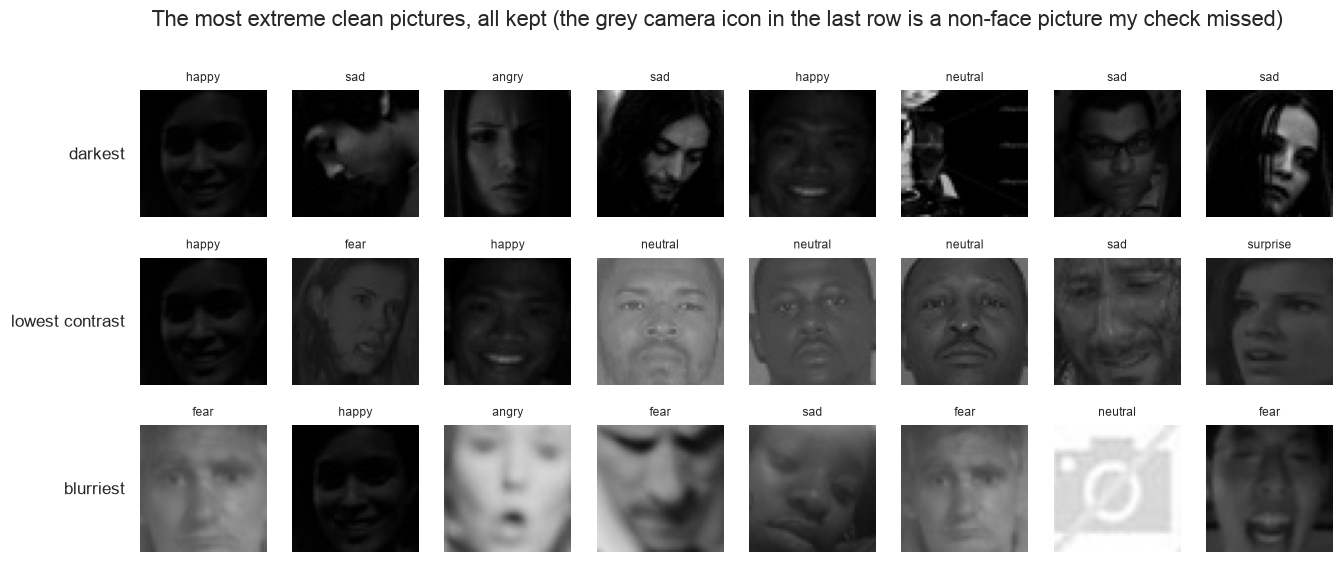

In [33]:
# Handling Outliers & Outlier treatments
# Outliers in a face dataset are pictures with extreme lighting, very low contrast or blur.
z = clean[["brightness", "contrast"]].apply(lambda s: (s - s.mean()) / s.std())
z["sharpness"] = np.log10(clean["sharpness"] + 1)
z["sharpness"] = (z["sharpness"] - z["sharpness"].mean()) / z["sharpness"].std()
out = (z.abs() > 3)
print("pictures beyond 3 standard deviations:", out.sum().to_dict(), "| any:", int(out.any(axis=1).sum()),
      f"({out.any(axis=1).mean():.2%})")
fig, axes = plt.subplots(3, 8, figsize=(14, 5.6))
for r, (col, asc, name) in enumerate([("brightness", True, "darkest"), ("contrast", True, "lowest contrast"),
                                      ("sharpness", True, "blurriest")]):
    for k, i in enumerate(clean.sort_values(col, ascending=asc).index[:8]):
        axes[r, k].imshow(X[i], cmap="gray", vmin=0, vmax=255)
        axes[r, k].set_title(clean.label[i], fontsize=8)
        axes[r, k].axis("off")
    axes[r, 0].text(-6, 24, name, ha="right", va="center", fontsize=11)
plt.suptitle("The most extreme clean pictures, all kept (the grey camera icon in the last row is a non-face picture my check missed)", y=1.0)
save("prep_outliers_kept.png")

##### What all outlier treatment techniques have you used and why did you use those techniques?

Outliers here are pictures with extreme lighting, contrast or blur. 419 pictures (1.24%) are more than 3 standard deviations from the mean on brightness (22), contrast (104) or sharpness (326).

I **kept** them. The figure shows they are real faces in deep shadow, washed-out light or motion blur, which is exactly what a webcam produces in a real room. Removing them would make the model worse in practice. Instead the model learns to handle them through:
- standardised inputs,
- data augmentation that changes brightness and contrast,
- the stress tests later, which measure the effect of darkness, blur and noise.

One honest note: the last row shows a grey camera placeholder icon among the blurriest pictures. My by-eye check of the 250 flattest pictures missed it because it is not flat enough. A handful of such pictures may be left (out of 33,919), too few to affect the results.

### 3. Categorical Encoding

In [34]:
# Encode your categorical columns
# The only categorical column is the target (the emotion). It becomes an integer 0-6, which is what
# PyTorch's cross-entropy loss and scikit-learn expect. No one-hot columns are needed.
print(LABEL_ID)
print("example:", df.loc[clean.index[:5], ["file", "label"]].assign(y=Y[clean.index[:5]]).to_string(index=False))

{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
example:                  file label  y
    train/angry/0.jpg angry  0
    train/angry/1.jpg angry  0
   train/angry/10.jpg angry  0
train/angry/10002.jpg angry  0
train/angry/10016.jpg angry  0


#### What all categorical encoding techniques have you used & why did you use those techniques?

The emotion is the only categorical column and it is the target. I mapped the 7 emotions to the integers 0-6 in alphabetical order. PyTorch's cross-entropy loss and scikit-learn take integer labels directly, so one-hot encoding is not needed. The same order is saved in the model card, so the app turns the outputs back into names correctly.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

This dataset has no text, only face images, so the ten text steps below don't apply. The image pre-processing (cleaning, scaling, resizing, augmentation) is in steps 1-3 above and 5-9 below.

#### 1. Expand Contraction

In [35]:
# Expand Contraction
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 2. Lower Casing

In [36]:
# Lower Casing
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 3. Removing Punctuations

In [37]:
# Remove Punctuations
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 4. Removing URLs & Removing words and digits contain digits.

In [38]:
# Remove URLs & Remove words and digits contain digits
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 5. Removing Stopwords & Removing White spaces

In [39]:
# Remove Stopwords
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


In [40]:
# Remove White spaces
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 6. Rephrase Text

In [41]:
# Rephrase Text
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 7. Tokenization

In [42]:
# Tokenization
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 8. Text Normalization

In [43]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


##### Which text normalization technique have you used and why?

Not applicable: there is no text in this dataset.

#### 9. Part of speech tagging

In [44]:
# POS Taging
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


#### 10. Text Vectorization

In [45]:
# Vectorizing Text
# not needed here: the data are images, there is no text column
print("not applicable: the dataset has no text, only face images")

not applicable: the dataset has no text, only face images


##### Which text vectorization technique have you used and why?

Not applicable: there is no text in this dataset.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [46]:
# Manipulate Features to minimize feature correlation and create new features
# Two kinds of features are used in this project:
#  a) for the CNNs: the 2,304 raw pixels. The networks learn their own features, and new variations of every
#     training face are created on the fly by data augmentation (section 5 below).
#  b) for the classic baseline: handcrafted features, HOG (edge directions in 8x8 cells, 900 numbers) and
#     LBP (texture codes counted in a 4x4 grid of regions, 160 numbers).
t0 = time.time()
H_raw = deepfer.hog_lbp_features(X)                    # all pictures, so the arrays line up with X and Y
H_eq = deepfer.hog_lbp_features(X, use_clahe=True)     # the same after CLAHE histogram equalisation
print(f"HOG + LBP features: {H_raw.shape[1]} per picture, computed in {time.time() - t0:.0f}s")

# Does CLAHE (evening out the lighting) make the handcrafted features better? Quick check on validation.
quick_tr = tr_idx[:4000] if QUICK else tr_idx
check = {}
for name, H in [("raw pictures", H_raw), ("after CLAHE", H_eq)]:
    m = make_pipeline(StandardScaler(), PCA(150, random_state=SEED), LogisticRegression(max_iter=1000))
    m.fit(H[quick_tr], Y[quick_tr])
    p = m.predict(H[va_idx])
    check[name] = {"val accuracy": accuracy_score(Y[va_idx], p), "val macro F1": f1_score(Y[va_idx], p, average="macro")}
check = pd.DataFrame(check).T.round(4)
display(check)
USE_CLAHE = check.loc["after CLAHE", "val macro F1"] > check.loc["raw pictures", "val macro F1"]
H = H_eq if USE_CLAHE else H_raw
print("handcrafted features use", "CLAHE pictures" if USE_CLAHE else "raw pictures")

# how correlated are the features? (neighbouring HOG blocks share cells)
c = np.corrcoef(H[tr_idx[:3000]].T)
print(f"share of feature pairs with |correlation| > 0.5: {(np.abs(c[np.triu_indices_from(c, 1)]) > 0.5).mean():.2%}")

HOG + LBP features: 1060 per picture, computed in 127s


,val accuracy,val macro F1
raw pictures,0.4328,0.3470
after CLAHE,0.4429,0.3586


handcrafted features use CLAHE pictures
share of feature pairs with |correlation| > 0.5: 0.28%


#### 2. Feature Selection

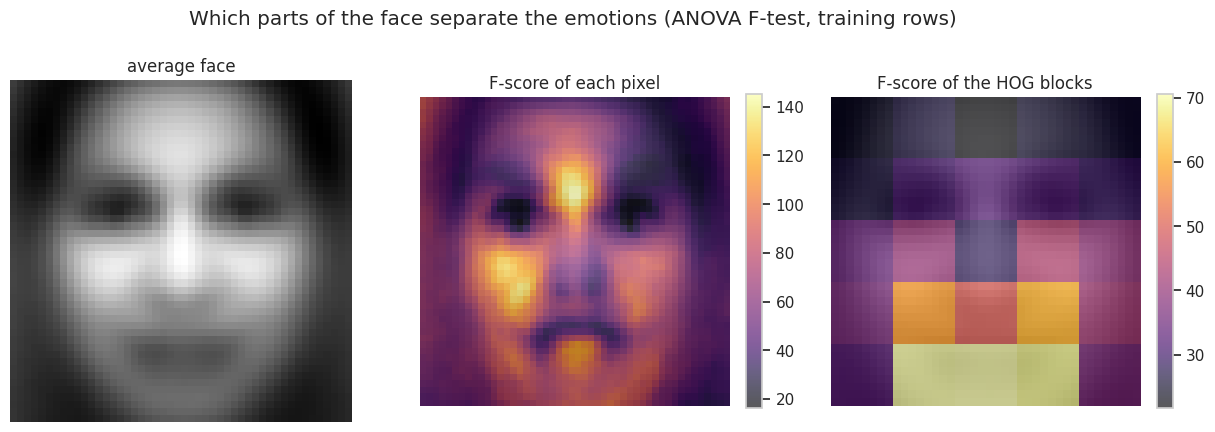

forehead (rows 0-9)       53.0
eyes and brows (10-23)    57.8
nose (24-30)              76.3
mouth and chin (31-47)    69.8

pixels with F > 50: 68.3% | the weakest 25% of pixels have F below 46.1


In [47]:
# Select your features wisely to avoid overfitting
# ANOVA F-test on the training rows only: how strongly each pixel (and each HOG cell) differs between the 7 emotions
pix_tr = X[tr_idx].reshape(len(tr_idx), -1).astype(np.float32)
f_pix, _ = f_classif(pix_tr, Y[tr_idx])
f_map = f_pix.reshape(48, 48)
f_hog, _ = f_classif(H[tr_idx][:, :900], Y[tr_idx])
# HOG: 5x5 blocks of 2x2 cells x 9 directions -> average F per block, shown on the face grid
f_block = f_hog.reshape(5, 5, 36).mean(2)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(overall, cmap="gray"); ax[0].set_title("average face"); ax[0].axis("off")
ax[1].imshow(overall, cmap="gray"); im = ax[1].imshow(f_map, cmap="inferno", alpha=0.65)
ax[1].set_title("F-score of each pixel"); ax[1].axis("off"); fig.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].imshow(overall, cmap="gray", extent=(0, 48, 48, 0))
im = ax[2].imshow(f_block, cmap="inferno", alpha=0.65, extent=(4, 44, 44, 4))
ax[2].set_title("F-score of the HOG blocks"); ax[2].axis("off"); fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.suptitle("Which parts of the face separate the emotions (ANOVA F-test, training rows)", y=1.02)
save("prep_feature_importance_f_test.png")

regions = {"forehead (rows 0-9)": f_map[:10], "eyes and brows (10-23)": f_map[10:24], "nose (24-30)": f_map[24:31],
           "mouth and chin (31-47)": f_map[31:]}
print(pd.Series({k: v.mean() for k, v in regions.items()}).round(1).rename("mean F-score").to_string())
print(f"\npixels with F > 50: {(f_pix > 50).mean():.1%} | the weakest 25% of pixels have F below {np.percentile(f_pix, 25):.1f}")

##### What all feature selection methods have you used  and why?

- **ANOVA F-test per pixel** on the training rows. It measures how much the mean grey value of each pixel differs between the seven emotions compared with the variation inside each emotion. The map shows where the emotions differ.
- **The same F-test on the HOG features**, averaged per block of the face.
- **A CLAHE check** for the handcrafted features: the same quick model on HOG and LBP from the raw pictures and from CLAHE-equalised pictures, compared on validation. CLAHE was slightly better (macro F1 0.359 against 0.347), so the classic model uses it.
- **PCA** (step 7) for the classic model instead of dropping features.

I did not remove any pixels for the CNNs. 68% of the pixels have an F-score above 50, and the weakest quarter still has F around 46, so every region carries some signal. The CNNs learn their own feature selection through their filters, and Grad-CAM and occlusion later show what they use.

##### Which all features you found important and why?

- **Pixel F-scores by region:** the band of the nose, cheeks and upper lip is the most informative (mean F 76), then the mouth and chin (70), the eyes and brows (58) and the forehead (53). The bright spots of the map are the smile lines from the nose to the mouth corners, the cheeks and the mouth.
- **HOG blocks:** the mouth and chin blocks score highest (about 70), then the cheeks.

This fits how people show emotions. A smile raises the cheeks and deepens the lines around the mouth, surprise opens the mouth, and anger and disgust wrinkle the nose and lower the brows. The occlusion test later confirms it for the trained model: the eyes and brows matter most for angry, disgust and fear, the mouth for happy.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

training pixels: mean 0.5039, standard deviation 0.2545


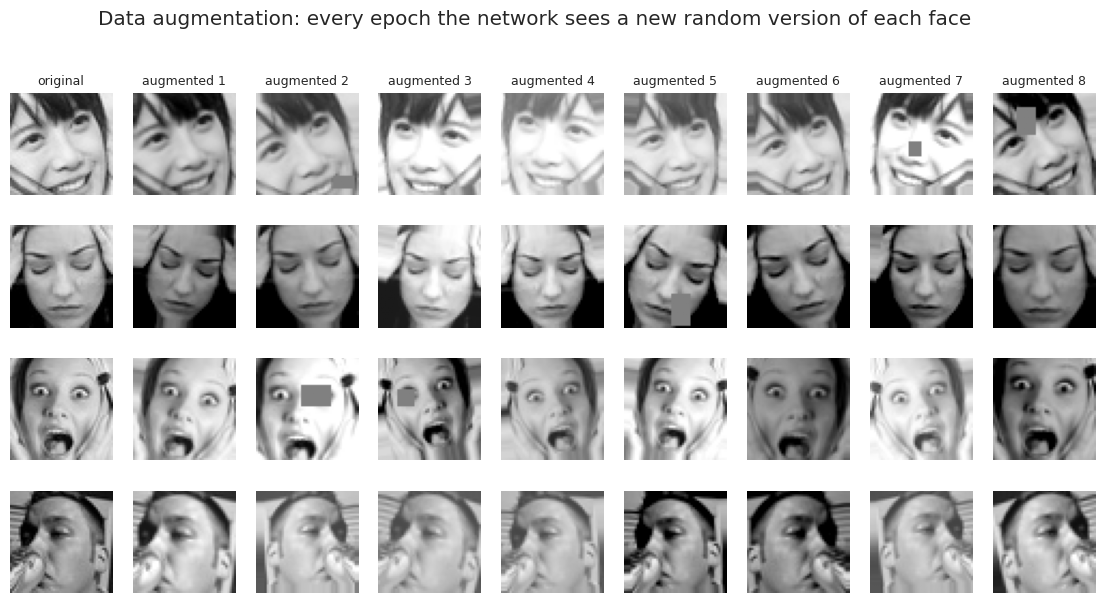

input of the ImageNet models: (1, 3, 128, 128) mean 0.76, std 1.10


In [48]:
# Transform Your data
# 1) Pixels 0-255 -> 0-1 and standardised. This happens inside every model (deepfer.InputAdapter), so the
#    saved models take a plain 48x48 grey face and the app can't forget a step.
PIXEL_MEAN = float(X[tr_idx].mean() / 255)
PIXEL_STD = float(X[tr_idx].std() / 255)
print(f"training pixels: mean {PIXEL_MEAN:.4f}, standard deviation {PIXEL_STD:.4f}")
# 2) For the ImageNet models: resize 48 -> 128 (bilinear), copy grey to 3 channels, ImageNet mean and std.
# 3) Data augmentation, for training only, on the GPU for a whole batch at once: mirror, rotation +-15 deg,
#    zoom +-12%, shift +-10%, brightness +-20%, contrast +-30% and a random grey patch (cut-out).
rs = np.random.RandomState(7)
picks = [rs.choice(clean.index[(clean["label"] == c) & (clean["split"] == "train")]) for c in ["happy", "fear", "surprise", "sad"]]
torch.manual_seed(0)
fig, axes = plt.subplots(4, 9, figsize=(14, 6.6))
for r, i in enumerate(picks):
    base = torch.from_numpy(X[i]).float().div(255).view(1, 1, 48, 48).repeat(8, 1, 1, 1)
    aug = deepfer.augment(base).numpy()[:, 0]
    axes[r, 0].imshow(X[i], cmap="gray", vmin=0, vmax=255); axes[r, 0].set_title("original" if r == 0 else "", fontsize=9)
    for k in range(8):
        axes[r, k + 1].imshow(aug[k], cmap="gray", vmin=0, vmax=1)
        if r == 0:
            axes[r, k + 1].set_title(f"augmented {k + 1}", fontsize=9)
    for a in axes[r]:
        a.axis("off")
plt.suptitle("Data augmentation: every epoch the network sees a new random version of each face", y=1.0)
save("prep_augmentation.png")

# what the pre-trained models receive: the same face at 128x128 in 3 channels
adapter = deepfer.InputAdapter(128, True, deepfer.IMAGENET_MEAN, deepfer.IMAGENET_STD)
x128 = adapter(torch.from_numpy(X[picks[0]]).float().div(255).view(1, 1, 48, 48))
print("input of the ImageNet models:", tuple(x128.shape), f"mean {x128.mean():.2f}, std {x128.std():.2f}")

Yes:
1. **Scaling** the pixels from 0-255 to 0-1 and standardising them. Networks train faster and more stably on inputs around 0 with a similar spread.
2. **Resizing to 128x128 and copying to 3 channels for the ImageNet models.** ResNet18 and EfficientNet-B0 were trained on colour photos of 224x224. At 48x48 their five downsampling steps would shrink the face to 2x2 pixels, so I enlarge it. 128 instead of 224 was a speed choice: on my Mac's GPU 224 took 4 minutes per pass.
3. **Data augmentation (training only):**
   - a random mirror image
   - rotation up to 15 degrees, zoom up to 12% and shifts up to 10%, for head pose and framing
   - brightness up to 20% and contrast up to 30%, for lighting
   - a random grey patch (cut-out) that hides part of the face, so the model doesn't depend on one single region

   Every epoch the network sees a new random version of every face. The augmentation runs on the GPU for a whole batch at once (`deepfer.augment`), so it doesn't slow the training down.

All of these steps except augmentation live inside the saved models (`InputAdapter`), so the app only has to pass a 48x48 face.

### 6. Data Scaling

In [49]:
# Scaling your data
# Handcrafted features: StandardScaler (mean 0, std 1 per feature), fitted on the training rows inside the model pipeline.
sc = StandardScaler().fit(H[tr_idx])
print("HOG+LBP after scaling, training rows: mean", round(float(sc.transform(H[tr_idx]).mean()), 4),
      "std", round(float(sc.transform(H[tr_idx]).std()), 4))
# Pixels: standardised with the training mean and std inside the custom CNN.
batch = deepfer.InputAdapter(48, False, [PIXEL_MEAN], [PIXEL_STD])(torch.from_numpy(X[tr_idx[:2000]]).float().div(255).unsqueeze(1))
print(f"pixels after scaling, 2,000 training faces: mean {batch.mean():.3f}, std {batch.std():.3f}")

HOG+LBP after scaling, training rows: mean 0.0 std 1.0
pixels after scaling, 2,000 training faces: mean 0.009, std 1.000


##### Which method have you used to scale you data and why?

- **Handcrafted features (HOG + LBP):** `StandardScaler`, fitted on the training rows inside the model pipeline, so each of the 1,060 features has mean 0 and standard deviation 1. Logistic regression and PCA both need features on the same scale.
- **Pixels for the custom CNN:** divided by 255 and then standardised with the mean and standard deviation of the training pixels. Inputs centred around 0 make the first layers train faster and more stably.
- **Pixels for the pre-trained models:** divided by 255, copied to three channels and standardised with the ImageNet mean and standard deviation, because those networks were trained on inputs scaled that way.

All pixel scaling happens inside the saved models (`InputAdapter`), so the app passes a plain 48x48 face and can't forget a step.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

For the CNNs, no: convolution, pooling and the final global average pooling already compress the 2,304 pixels step by step, and they learn which information to keep.

For the classic baseline, yes. The 1,060 HOG and LBP features are mostly only weakly correlated (just 0.28% of the pairs above 0.5), but there are many of them for a linear model on 23,000 rows. Many directions carry very little variance, which only adds noise and fitting time.

components needed: {'80%': 196, '90%': 295, '95%': 373, '99%': 508} of 1060


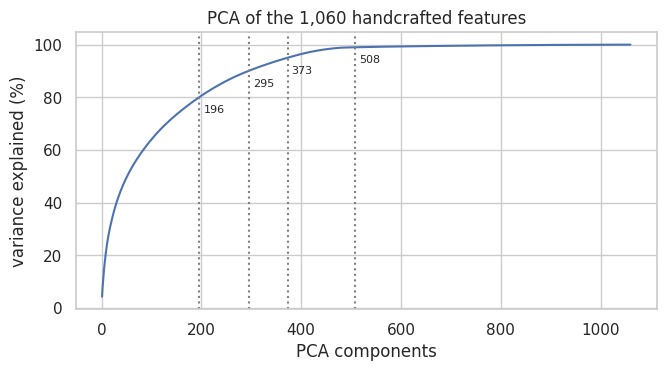

In [50]:
# DImensionality Reduction (If needed)
# PCA on the scaled HOG + LBP features of the training rows (for the classic baseline only)
pca_h = PCA(random_state=SEED).fit(sc.transform(H[tr_idx]))
cum_h = np.cumsum(pca_h.explained_variance_ratio_)
need = {t: int(np.searchsorted(cum_h, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)}
print("components needed:", {f"{int(k * 100)}%": v for k, v in need.items()}, "of", H.shape[1])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(np.arange(1, len(cum_h) + 1), cum_h * 100)
for t, n in need.items():
    ax.axvline(n, ls=":", c="grey"); ax.text(n + 8, t * 100 - 6, f"{n}", fontsize=8)
ax.set_xlabel("PCA components"); ax.set_ylabel("variance explained (%)")
ax.set_title("PCA of the 1,060 handcrafted features")
save("prep_pca_handcrafted.png")

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**PCA** on the standardised HOG and LBP features, fitted on the training rows only. 196 components keep 80% of the variance, 295 keep 90%, 373 keep 95% and 508 keep 99%. The amount to keep (90% or 95%) is a setting of the grid search in ML Model 1, which picked 90%: 295 components instead of 1,060, a 72% cut. PCA fits a linear model well because it removes correlated directions without needing the labels.

### 8. Data Splitting

In [51]:
# Split your data to train and test. Choose Splitting ratio wisely.
# (the split itself was made in section 3, right after cleaning, so no later step could look at the test set)
tab = pd.crosstab(clean["label"], clean["split"])[["train", "validation", "test"]]
tab.loc["total"] = tab.sum()
display(tab)
print((tab.loc["total"] / tab.loc["total"].sum()).round(3).to_dict())
assert not set(df.loc[tr_idx, "hash"]) & set(df.loc[te_idx, "hash"]), "a training picture is also in the test set"
assert not set(df.loc[va_idx, "hash"]) & set(df.loc[te_idx, "hash"])
print("no picture is shared between train/validation and test")

split,train,validation,test
label,,,
angry,3207,566,935
disgust,298,52,107
fear,3221,569,1002
happy,5918,1045,1819
neutral,4102,724,1208
sad,4065,718,1124
surprise,2110,372,757
total,22921,4046,6952


{'train': 0.676, 'validation': 0.119, 'test': 0.205}
no picture is shared between train/validation and test


##### What data splitting ratio have you used and why? 

- **Test: 6,952 pictures (20.5%).** This is the original validation folder after cleaning. It is kept completely apart and used only to report the final scores.
- **Validation: 4,046 pictures (11.9%).** These are 15% of the cleaned train folder, stratified by emotion. They are used for early stopping, the tuning trials and choosing the final model.
- **Training: 22,921 pictures (67.6%).**

Using the given folder as the test set keeps the split of the dataset's authors, and it is big enough for tight confidence intervals (about +-1 point on accuracy). 15% for validation gives about 4,000 pictures, including 52 disgust faces, enough to compare models without taking too much from training. No picture is shared between training or validation and the test set (checked with the pixel hashes).

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes. In the training rows happy has almost 20 times more pictures than disgust (5,918 against 298), and disgust is only 1.3% of the data. A model can ignore disgust completely and still reach a good accuracy, so the data is clearly imbalanced. Fear, sad and angry are well represented.

In [52]:
# Handling Imbalanced Dataset (If needed)
counts = pd.Series(Y[tr_idx]).value_counts().sort_index()
counts.index = CLASSES
w_balanced = (len(tr_idx) / (len(CLASSES) * counts))
w_sqrt = np.sqrt(w_balanced) / np.sqrt(w_balanced).mean()      # softer weights: square root of the balanced ones
weights = pd.DataFrame({"training pictures": counts, "share %": (counts / counts.sum() * 100).round(1),
                        "balanced weight": w_balanced.round(2), "sqrt weight (used if it helps)": w_sqrt.round(2)})
display(weights)
CLASS_WEIGHTS_SQRT = w_sqrt.to_numpy().tolist()
print("largest / smallest class in training:", round(counts.max() / counts.min(), 1))

,training pictures,share %,balanced weight,sqrt weight (used if it helps)
angry,3207,14.0,1.02,0.78
disgust,298,1.3,10.99,2.55
fear,3221,14.1,1.02,0.77
happy,5918,25.8,0.55,0.57
neutral,4102,17.9,0.80,0.69
sad,4065,17.7,0.81,0.69
surprise,2110,9.2,1.55,0.96


largest / smallest class in training: 19.9


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I tried three things and kept what worked on validation:
- **Class weights in the loss.** Fully balanced weights would make one disgust picture count 11 times and one happy picture 0.55 times, which made training unstable in early tests. So I used softer weights: the square root of the balanced ones (disgust 2.55, happy 0.57). In the CNN tuning trials the sqrt weights won both times (macro F1 0.451 against 0.449 at the chosen learning rate), so all the deep models use them. For the classic model, balanced weights lost in the grid search (CV macro F1 0.349 against 0.372).
- **Label smoothing (0.1)**, which keeps the model from becoming overconfident on the big classes.
- **Macro F1 as the main metric** for early stopping and model choice, so the rare classes count as much as the common ones.

I did not oversample by copying disgust pictures, because I had just removed duplicates and copies would let the model memorise them. Augmentation already gives every disgust face new versions in every epoch. In the end disgust reaches an F1 of 0.71 on the test set.

## ***7. ML Model Implementation***

#### Evaluation helpers
Every model is scored the same way: on the validation rows (used for all choices) and on the test rows (the original validation folder, used only to report). The main metrics are accuracy and macro F1, because macro F1 gives the rare emotions (disgust) the same weight as the common ones.

In [53]:
# Helpers used by all models: scores on validation and test, kept in one table
RESULTS, PROBS = {}, {}
y_va, y_te = Y[va_idx], Y[te_idx]
fit_idx = tr_idx[:1500] if QUICK else tr_idx            # QUICK = tiny code check only
E = (lambda n: 1) if QUICK else (lambda n: n)          # number of epochs


def softmax(z):
    return torch.softmax(torch.as_tensor(z, dtype=torch.float32), 1).numpy()


def evaluate(name, p_val, p_test, show=True):
    """Keep the class probabilities of a model and its validation and test scores."""
    PROBS[name] = (np.asarray(p_val), np.asarray(p_test))
    RESULTS[name] = {**{f"val {k}": v for k, v in deepfer.scores(y_va, np.argmax(p_val, 1)).items()},
                     **{f"test {k}": v for k, v in deepfer.scores(y_te, np.argmax(p_test, 1)).items()}}
    if show:
        display(pd.DataFrame(RESULTS[name], index=[name]).round(4))


def score_chart(names, title, fname, split="test"):
    cols = ["accuracy", "macro precision", "macro recall", "macro F1"]
    t = pd.DataFrame({n: [RESULTS[n][f"{split} {c}"] for c in cols] for n in names}, index=cols)
    ax = t.plot.bar(figsize=(11, 4), rot=0, width=0.8)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=7)
    ax.set_ylim(0, 1.0)
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left", ncol=2)
    save(fname)


def plot_history(hist, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
    ax[0].plot(hist["epoch"], hist["train loss"], label="train loss")
    ax[0].plot(hist["epoch"], hist["val loss"], label="validation loss")
    ax[0].legend(); ax[0].set_xlabel("epoch"); ax[0].set_title("loss")
    ax[1].plot(hist["epoch"], hist["val accuracy"], label="validation accuracy")
    ax[1].plot(hist["epoch"], hist["val macro F1"], label="validation macro F1")
    best = hist["val macro F1"].idxmax()
    ax[1].axvline(hist.loc[best, "epoch"], ls=":", c="grey", label=f"best epoch {hist.loc[best, 'epoch']}")
    ax[1].legend(); ax[1].set_xlabel("epoch"); ax[1].set_title("validation scores")
    plt.suptitle(title, y=1.02)
    save(fname)


def logits(model, Xd, tta=False):
    return deepfer.predict_logits(model, Xd, DEVICE, tta=tta).numpy()


# All pictures stay on the GPU as uint8 (about 80 MB), so a batch never waits for the CPU.
X_dev = torch.from_numpy(X).to(DEVICE)
Y_t = torch.from_numpy(Y)
rows = lambda idx: (X_dev[torch.from_numpy(idx).to(DEVICE)], Y_t[torch.from_numpy(idx)])
Xtr, ytr = rows(fit_idx)
Xva, yva = rows(va_idx)
Xte, yte = rows(te_idx)
print(f"train {len(Xtr):,} | validation {len(Xva):,} | test {len(Xte):,} pictures on {DEVICE}")

train 22,921 | validation 4,046 | test 6,952 pictures on cuda


### ML Model - 1 - Classic baseline: HOG + LBP features with logistic regression

In [54]:
# ML Model - 1 Implementation
# Classic computer vision baseline: HOG + LBP features -> scaling -> multinomial logistic regression
# (first version with default settings: all 1,060 features, C = 1, no class weights)
t0 = time.time()
lr_default = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
# Fit the Algorithm
lr_default.fit(H[fit_idx], Y[fit_idx])
print(f"trained in {time.time() - t0:.0f}s")
# Predict on the model
evaluate("HOG+LBP LR (default)", lr_default.predict_proba(H[va_idx]), lr_default.predict_proba(H[te_idx]))

trained in 69s


,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
HOG+LBP LR (default),0.4266,0.3567,0.3634,0.3582,0.4178,0.4459,0.3772,0.3758,0.3751,0.4376


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

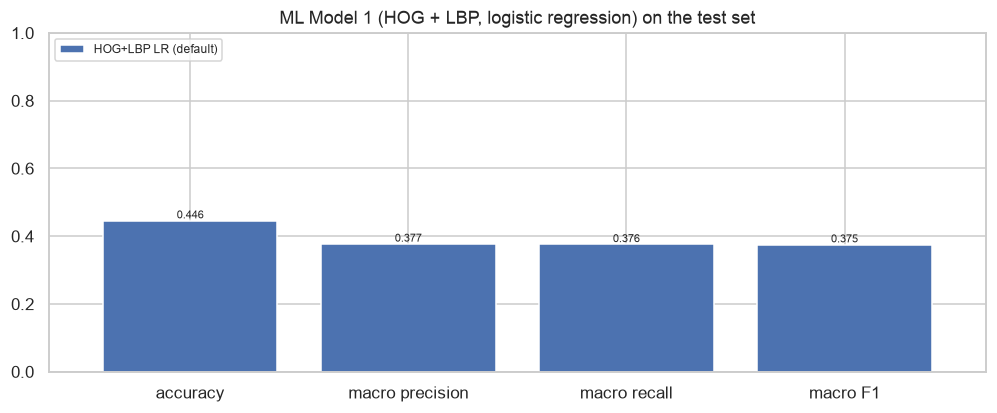

,precision,recall,f1-score
angry,0.333,0.274,0.301
disgust,0.136,0.131,0.133
fear,0.311,0.259,0.283
happy,0.617,0.717,0.663
neutral,0.418,0.449,0.433
sad,0.325,0.320,0.323
surprise,0.500,0.481,0.490


In [55]:
# Visualizing evaluation Metric Score chart
score_chart(["HOG+LBP LR (default)"], "ML Model 1 (HOG + LBP, logistic regression) on the test set", "model1_scores.png")
rep = pd.DataFrame(classification_report(y_te, PROBS["HOG+LBP LR (default)"][1].argmax(1), target_names=CLASSES,
                                         output_dict=True)).T.loc[CLASSES, ["precision", "recall", "f1-score"]]
display(rep.round(3))

**Model:** HOG features (900 numbers of edge directions per 8x8 cell) plus LBP texture histograms (160 numbers) from CLAHE-equalised pictures, scaled, then a multinomial logistic regression that gives a probability for each emotion. It is the classic way to recognise faces before deep learning, and it shows how far handcrafted features go.

**Performance (first version, default settings):**
- Test accuracy 44.6%, macro precision 0.377, macro recall 0.376, macro F1 0.375.
- It does well only on happy (F1 0.66) and surprise (0.49). Fear (0.28), angry (0.30) and especially disgust (0.13) are close to guessing.

It is better than always saying "happy" (26%), but far from usable.

#### 2. Cross- Validation & Hyperparameter Tuning

8 settings x 3 folds in 112s, best: {'logisticregression__C': 0.05, 'logisticregression__class_weight': None, 'pca__n_components': 0.9}


,PCA variance,C,class weight,CV macro F1,CV std
0,0.90,0.05,None,0.3719,0.0058
4,0.90,0.50,None,0.3701,0.0056
1,0.95,0.05,None,0.3654,0.0022
5,0.95,0.50,None,0.3647,0.0009
2,0.90,0.05,balanced,0.3494,0.0012
6,0.90,0.50,balanced,0.3489,0.0011
3,0.95,0.05,balanced,0.3486,0.0010
7,0.95,0.50,balanced,0.3484,0.0011


,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
HOG+LBP LR (tuned),0.4461,0.3975,0.3677,0.3699,0.4318,0.4517,0.4197,0.3782,0.3853,0.4376


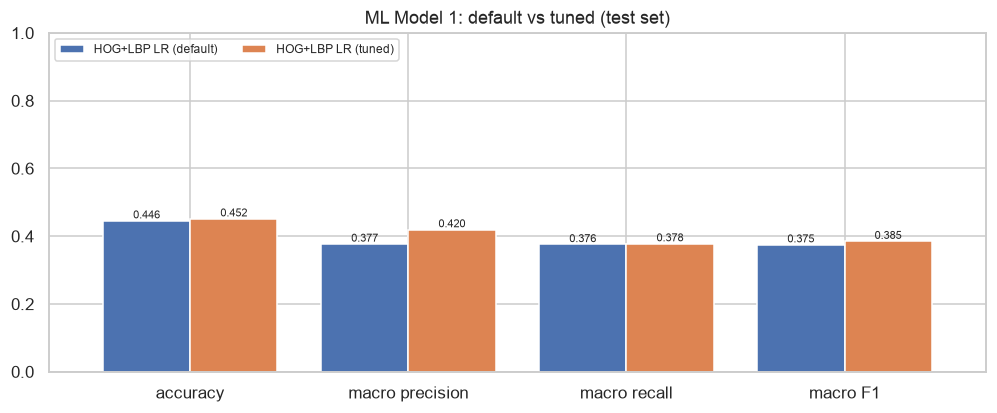

In [56]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Grid search with 3-fold stratified cross-validation on the training rows, scored by macro F1
grid = GridSearchCV(
    make_pipeline(StandardScaler(), PCA(random_state=SEED), LogisticRegression(max_iter=3000)),
    {"pca__n_components": [0.90, 0.95],
     "logisticregression__C": [0.05, 0.5],
     "logisticregression__class_weight": [None, "balanced"]},
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=-1)

# Fit the Algorithm
t0 = time.time()
grid.fit(H[fit_idx], Y[fit_idx])
print(f"8 settings x 3 folds in {time.time() - t0:.0f}s, best: {grid.best_params_}")
cv_tab = pd.DataFrame(grid.cv_results_)
cv_tab = cv_tab[["param_pca__n_components", "param_logisticregression__C", "param_logisticregression__class_weight",
                 "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)
cv_tab.columns = ["PCA variance", "C", "class weight", "CV macro F1", "CV std"]
display(cv_tab.round(4))

# Predict on the model
evaluate("HOG+LBP LR (tuned)", grid.predict_proba(H[va_idx]), grid.predict_proba(H[te_idx]))
score_chart(["HOG+LBP LR (default)", "HOG+LBP LR (tuned)"], "ML Model 1: default vs tuned (test set)", "model1_tuned_scores.png")

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 3-fold stratified cross-validation** on the training rows, scored by macro F1. The grid has 8 settings: PCA keeping 90% or 95% of the variance, regularisation strength C = 0.05 or 0.5, and class weights none or balanced. A grid search fits here because there are only a few settings, each fit takes seconds, and cross-validation gives a stable comparison (the fold spread was below 0.006). It ran in 112 seconds.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a little. The best setting was PCA at 90% (295 components), C = 0.05 (stronger regularisation) and no class weights, with a cross-validated macro F1 of 0.372 +- 0.006.

| | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| Default | 0.446 | 0.377 | 0.376 | 0.375 |
| Tuned | 0.452 | 0.420 | 0.378 | 0.385 |

Accuracy went up 0.6 points, macro F1 1 point and precision 4 points, with a much smaller model. Balanced class weights made it worse: the linear model then over-predicts disgust and loses more elsewhere. The classic approach is clearly limited by its features, not its settings.

### ML Model - 2 - DeepFER-Net: a custom CNN trained from scratch

In [57]:
# ML Model - 2 Implementation
# DeepFER-Net: a CNN designed for 48x48 faces (code in deepfer.DeepFERNet)
#  - stem: two 3x3 convolutions at full size, so small details like eye corners are kept
#  - three residual stages 48 -> 24 -> 12 -> 6 pixels with 128 -> 256 -> 512 channels; every block is
#    conv-BN-ReLU-conv-BN + squeeze-excitation (channel attention) + a shortcut connection
#  - global average pooling -> dropout 0.4 -> 7 outputs (softmax inside the cross-entropy loss)
cnn0 = deepfer.build_model("deepfer_cnn", pixel_mean=PIXEL_MEAN, pixel_std=PIXEL_STD)

shapes = []
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.append((n, tuple(o.shape[1:]), sum(p.numel() for p in m.parameters()))))
         for n, m in cnn0[1].named_children()]
cnn0.eval()(torch.zeros(1, 1, 48, 48))
for h in hooks:
    h.remove()
display(pd.DataFrame(shapes, columns=["block", "output shape (channels, height, width)", "parameters"]))
print(f"total parameters: {deepfer.count_params(cnn0):,}")

# First version: the plain network, trained without augmentation and without class weights
NO_AUG = dict(rot=0, scale=0, shift=0, flip=False, bright=0, contrast=0, erase_p=0)
t0 = time.time()
cnn0, hist_cnn0 = deepfer.train_model(cnn0, Xtr, ytr, Xva, yva, DEVICE, epochs=E(30), lr=2e-3, patience=5, aug=NO_AUG)
print(f"training time {time.time() - t0:.0f}s on {DEVICE}")
evaluate("CNN (no augmentation)", softmax(logits(cnn0, Xva)), softmax(logits(cnn0, Xte)))

,block,"output shape (channels, height, width)",parameters
0,stem,"(64, 48, 48)",18912
1,stage1,"(128, 24, 24)",534048
2,stage2,"(256, 12, 12)",2133056
3,stage3,"(512, 6, 6)",3739200
4,head,"(7,)",3591


total parameters: 6,428,807
epoch  1  train loss 1.733  val loss 1.503  val acc 0.412  val macro F1 0.286  (15s)
epoch  2  train loss 1.510  val loss 1.421  val acc 0.462  val macro F1 0.341  (12s)
epoch  3  train loss 1.416  val loss 1.595  val acc 0.386  val macro F1 0.288  (12s)
epoch  4  train loss 1.355  val loss 1.309  val acc 0.508  val macro F1 0.387  (12s)
epoch  5  train loss 1.287  val loss 1.138  val acc 0.570  val macro F1 0.466  (13s)
epoch  6  train loss 1.210  val loss 1.211  val acc 0.544  val macro F1 0.428  (13s)
epoch  7  train loss 1.141  val loss 1.821  val acc 0.366  val macro F1 0.294  (12s)
epoch  8  train loss 1.066  val loss 1.204  val acc 0.553  val macro F1 0.440  (12s)
epoch  9  train loss 0.976  val loss 1.488  val acc 0.487  val macro F1 0.361  (12s)
epoch 10  train loss 0.851  val loss 1.235  val acc 0.566  val macro F1 0.472  (12s)
epoch 11  train loss 0.734  val loss 1.323  val acc 0.547  val macro F1 0.474  (12s)
epoch 12  train loss 0.638  val loss 

,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
CNN (no augmentation),0.5712,0.5215,0.4955,0.5035,0.5719,0.589,0.5574,0.5344,0.5432,0.5918


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

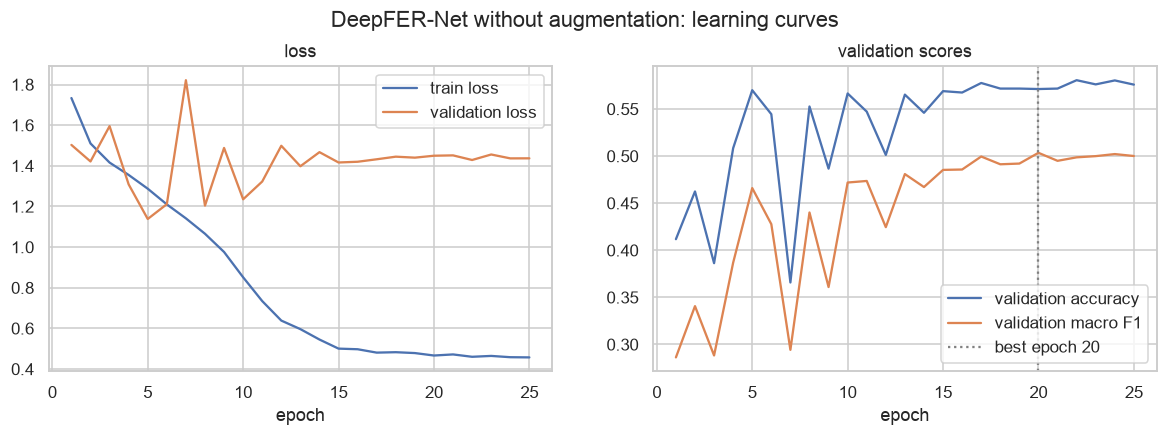

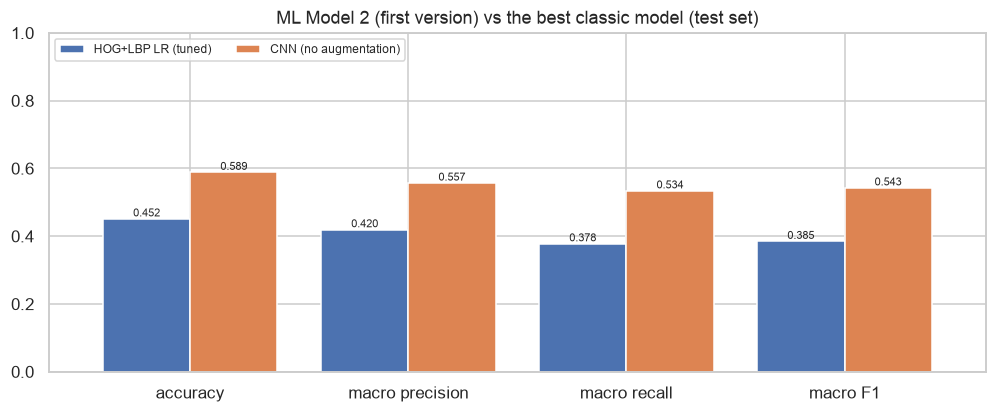

In [58]:
# Visualizing evaluation Metric Score chart
plot_history(hist_cnn0, "DeepFER-Net without augmentation: learning curves", "model2_first_history.png")
score_chart(["HOG+LBP LR (tuned)", "CNN (no augmentation)"], "ML Model 2 (first version) vs the best classic model (test set)", "model2_scores.png")

**DeepFER-Net**, a CNN I designed for 48x48 faces (6.4 million parameters):
- **Stem:** two 3x3 convolutions at full resolution (32 and 64 channels), so small details like eye corners are kept.
- **Three residual stages** that halve the size and double the channels: 48 -> 24 -> 12 -> 6 pixels with 128 -> 256 -> 512 channels. Every block is conv-BatchNorm-ReLU-conv-BatchNorm plus a **squeeze-excitation** module (channel attention: it learns which feature maps matter for the current face) and a **shortcut connection** (the input is added to the output, which keeps training stable as the network gets deeper).
- **Head:** global average pooling, dropout 0.4 and a linear layer with 7 outputs (softmax inside the cross-entropy loss).

Training: AdamW, mini-batches of 128, a one-cycle learning rate (warm-up then cosine decay), mixed precision on the GPU, label smoothing 0.1 and early stopping on validation macro F1.

**First version, without augmentation and class weights:** test accuracy 58.9%, macro F1 0.543, already 14 points above the classic model. But the learning curves show clear **overfitting**. The training loss falls from 1.73 to 0.46 while the validation loss is lowest at epoch 5 (1.14) and then rises to about 1.44. The network starts memorising the training faces. Early stopping kept epoch 20 (validation macro F1 0.503). Training took 5 minutes on the T4 GPU (12 seconds per epoch).

#### 2. Cross- Validation & Hyperparameter Tuning

trial lr 0.001 class weights none: val macro F1 0.4488
trial lr 0.001 class weights sqrt: val macro F1 0.4514
trial lr 0.003 class weights none: val macro F1 0.4192
trial lr 0.003 class weights sqrt: val macro F1 0.4256


,max learning rate,class weights,val accuracy,val macro F1,minutes
1,0.001,sqrt,0.5487,0.4514,0.8826
0,0.001,none,0.5598,0.4488,0.8784
3,0.003,sqrt,0.5232,0.4256,0.8808
2,0.003,none,0.5319,0.4192,0.8749


chosen: 0.001 class weights: sqrt
epoch  1  train loss 1.988  val loss 1.762  val acc 0.307  val macro F1 0.197  (13s)
epoch  2  train loss 1.852  val loss 2.140  val acc 0.213  val macro F1 0.156  (13s)
epoch  3  train loss 1.718  val loss 2.041  val acc 0.286  val macro F1 0.212  (13s)
epoch  4  train loss 1.646  val loss 1.450  val acc 0.456  val macro F1 0.346  (13s)
epoch  5  train loss 1.599  val loss 1.477  val acc 0.446  val macro F1 0.350  (13s)
epoch  6  train loss 1.540  val loss 1.280  val acc 0.531  val macro F1 0.434  (13s)
epoch  7  train loss 1.513  val loss 1.444  val acc 0.462  val macro F1 0.386  (13s)
epoch  8  train loss 1.481  val loss 1.392  val acc 0.488  val macro F1 0.389  (13s)
epoch  9  train loss 1.454  val loss 1.166  val acc 0.575  val macro F1 0.493  (13s)
epoch 10  train loss 1.429  val loss 1.139  val acc 0.584  val macro F1 0.498  (13s)
epoch 11  train loss 1.410  val loss 1.135  val acc 0.574  val macro F1 0.484  (13s)
epoch 12  train loss 1.391  val

,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
"CNN (augmented, tuned)",0.6703,0.633,0.6254,0.6271,0.6676,0.6821,0.6604,0.6649,0.6605,0.6801


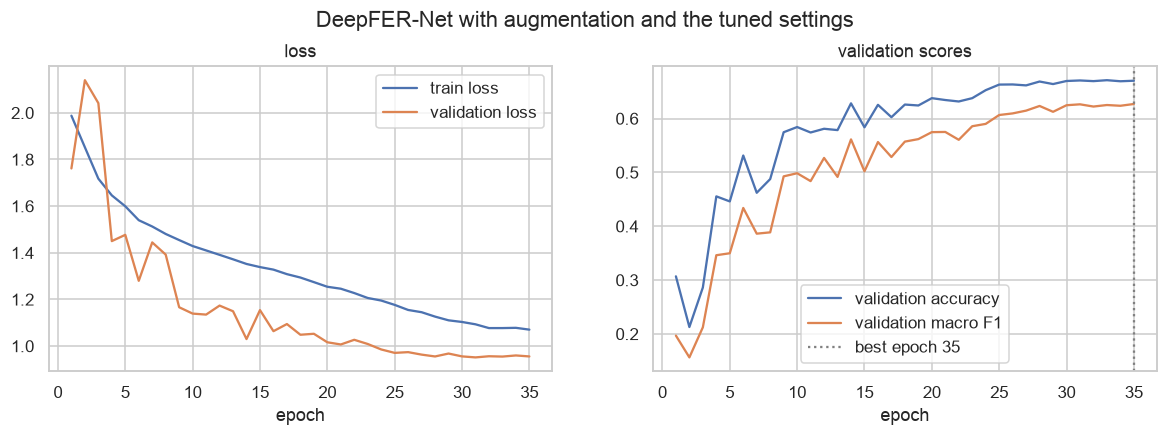

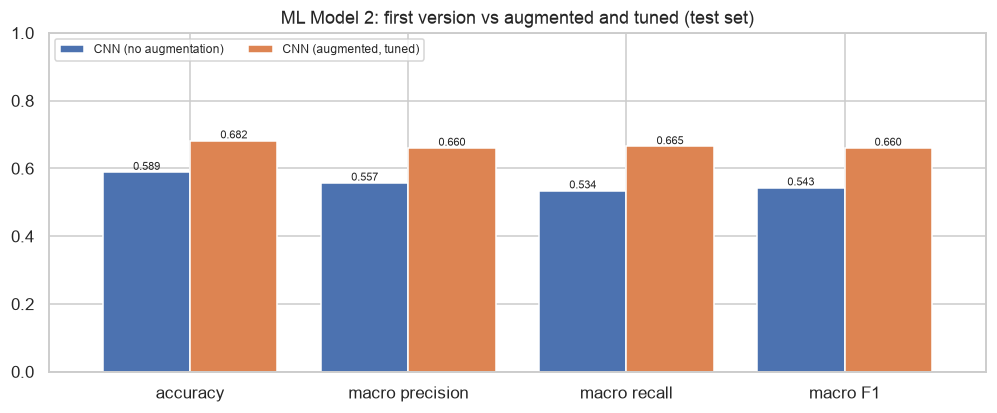

In [59]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Short trials first: each setting gets 8 epochs (a complete one-cycle schedule) on half of the training rows,
# with augmentation on. That ranks the settings at about a sixth of the cost of full runs.
rs = np.random.RandomState(SEED)
half = rs.choice(len(fit_idx), len(fit_idx) // 2, replace=False)
Xhalf, yhalf = rows(fit_idx[half])
trials = []
for lr in [1e-3, 3e-3]:
    for cw_name, cw in [("none", None), ("sqrt", CLASS_WEIGHTS_SQRT)]:
        t0 = time.time()
        m = deepfer.build_model("deepfer_cnn", pixel_mean=PIXEL_MEAN, pixel_std=PIXEL_STD)
        m, h = deepfer.train_model(m, Xhalf, yhalf, Xva, yva, DEVICE, epochs=E(8), lr=lr, class_weights=cw,
                                   patience=99, log=lambda s: None)          # quiet: only the summary is printed
        best = h.loc[h["val macro F1"].idxmax()]
        trials.append({"max learning rate": lr, "class weights": cw_name, "val accuracy": best["val accuracy"],
                       "val macro F1": best["val macro F1"], "minutes": (time.time() - t0) / 60})
        deepfer.log_line(f"trial lr {lr} class weights {cw_name}: val macro F1 {best['val macro F1']:.4f}")
trials = pd.DataFrame(trials).sort_values("val macro F1", ascending=False)
display(trials.round(4))
BEST_LR = float(trials.iloc[0]["max learning rate"])
CW = CLASS_WEIGHTS_SQRT if trials.iloc[0]["class weights"] == "sqrt" else None
print("chosen:", BEST_LR, "class weights:", trials.iloc[0]["class weights"])

# Final training of the tuned network on all training rows: augmentation, up to 35 epochs, early stopping after 8
t0 = time.time()
cnn = deepfer.build_model("deepfer_cnn", pixel_mean=PIXEL_MEAN, pixel_std=PIXEL_STD)
cnn, hist_cnn = deepfer.train_model(cnn, Xtr, ytr, Xva, yva, DEVICE, epochs=E(35), lr=BEST_LR, class_weights=CW, patience=8)
print(f"training time {(time.time() - t0) / 60:.1f} min")
evaluate("CNN (augmented, tuned)", softmax(logits(cnn, Xva)), softmax(logits(cnn, Xte)))
deepfer.save_model(cnn, "models/deepfer_cnn.pt", "deepfer_cnn", {"size": 48, "pixel_mean": PIXEL_MEAN, "pixel_std": PIXEL_STD})
plot_history(hist_cnn, "DeepFER-Net with augmentation and the tuned settings", "model2_tuned_history.png")
score_chart(["CNN (no augmentation)", "CNN (augmented, tuned)"], "ML Model 2: first version vs augmented and tuned (test set)", "model2_tuned_scores.png")

##### Which hyperparameter optimization technique have you used and why?

**A small grid search with short trials.** Each of 4 settings (top learning rate 1e-3 or 3e-3, class weights none or sqrt) got 8 epochs, a complete one-cycle schedule, on half of the training rows with augmentation on. The best one was then trained fully. Full runs of every setting would have cost about 4 times as much GPU time. The short trials ranked the settings well enough because the gaps were clear: 1e-3 beat 3e-3 by about 3 points of macro F1.

| Top learning rate | Class weights | Val accuracy | Val macro F1 |
|---|---|---|---|
| 0.001 | sqrt | 0.549 | 0.451 |
| 0.001 | none | 0.560 | 0.449 |
| 0.003 | sqrt | 0.523 | 0.426 |
| 0.003 | none | 0.532 | 0.419 |

Each trial took under a minute. Cross-validation of a CNN would mean 3-5 full trainings per setting, so I used the fixed validation split, which is common practice for deep learning on this much data.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a big improvement. The final training used augmentation, a top learning rate of 1e-3 and sqrt class weights for up to 35 epochs (7.3 minutes):

| | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| First version (no augmentation) | 0.589 | 0.557 | 0.534 | 0.543 |
| Augmented and tuned | 0.682 | 0.660 | 0.665 | 0.660 |

That is +9.3 points of accuracy and +11.7 points of macro F1. The learning curves explain why. With augmentation the validation loss keeps falling to 0.95 and stays below the training loss, which is higher because every training picture is a harder, altered version. The model no longer memorises the faces. It was still improving slightly at epoch 35, so more epochs might give a little more.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **Accuracy:** the share of faces whose emotion is right. Easy to explain to a manager, but with imbalanced classes it can look good while rare emotions are ignored.
- **Precision** (per emotion): when the system says "angry", how often is the person really angry? Low precision means false alarms. In a support centre that would mean supervisors called in for calm customers, which wastes time and erodes trust.
- **Recall** (per emotion): of all the angry people, how many does the system catch? Low recall means missed moments, like an upset customer or a distressed user nobody notices.
- **F1:** the balance of the two. **Macro F1** averages it over all seven emotions, so disgust and fear count as much as happy. That is the fairest single number here and the one I used for every choice.

For a business, the right balance depends on the use. A mental-health check-in should favour recall for sad and fear (better to ask once too often). An automatic action, like escalating a call, needs high precision. The final model's per-emotion scores (section 7, step 4) and the "not sure" option let a product set this per use case.

### ML Model - 3 - Transfer learning: fine-tuned ResNet18 and EfficientNet-B0

In [60]:
# ML Model - 3 Implementation
# Transfer learning from ImageNet with two well-known backbones: ResNet18 (11.2M parameters) and
# EfficientNet-B0 (4.0M). Every face is resized to 128x128 and copied to 3 channels inside the model, and the
# 1,000-class ImageNet head is replaced with dropout + a 7-class layer.
# Step 1 (this cell): the pre-trained body is frozen and only the new head learns ("feature extraction").
TL, TL_HIST = {}, {}
for name in ["resnet18", "efficientnet_b0"]:
    t0 = time.time()
    m = deepfer.build_model(name, size=128)
    m, h = deepfer.train_model(m, Xtr, ytr, Xva, yva, DEVICE, epochs=E(3), lr=1e-3, freeze_body=True,
                               class_weights=CW, patience=99)
    print(f"{name}: {deepfer.count_params(m):,} parameters, head-only training {time.time() - t0:.0f}s")
    evaluate(f"{name} (frozen body)", softmax(logits(m, Xva)), softmax(logits(m, Xte)))
    TL[name] = m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


epoch  1  train loss 2.035  val loss 1.627  val acc 0.404  val macro F1 0.332  (5s)
epoch  2  train loss 1.851  val loss 1.597  val acc 0.422  val macro F1 0.331  (5s)
epoch  3  train loss 1.820  val loss 1.567  val acc 0.431  val macro F1 0.350  (5s)
resnet18: 11,180,103 parameters, head-only training 14s


,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
resnet18 (frozen body),0.4313,0.3849,0.3518,0.3496,0.4116,0.4475,0.3676,0.3548,0.3506,0.4244


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


epoch  1  train loss 1.890  val loss 1.591  val acc 0.418  val macro F1 0.338  (8s)
epoch  2  train loss 1.796  val loss 1.560  val acc 0.429  val macro F1 0.344  (7s)
epoch  3  train loss 1.773  val loss 1.541  val acc 0.431  val macro F1 0.351  (7s)
efficientnet_b0: 4,016,515 parameters, head-only training 24s


,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
efficientnet_b0 (frozen body),0.4313,0.3815,0.355,0.3508,0.4053,0.4548,0.4119,0.3775,0.3787,0.4322


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

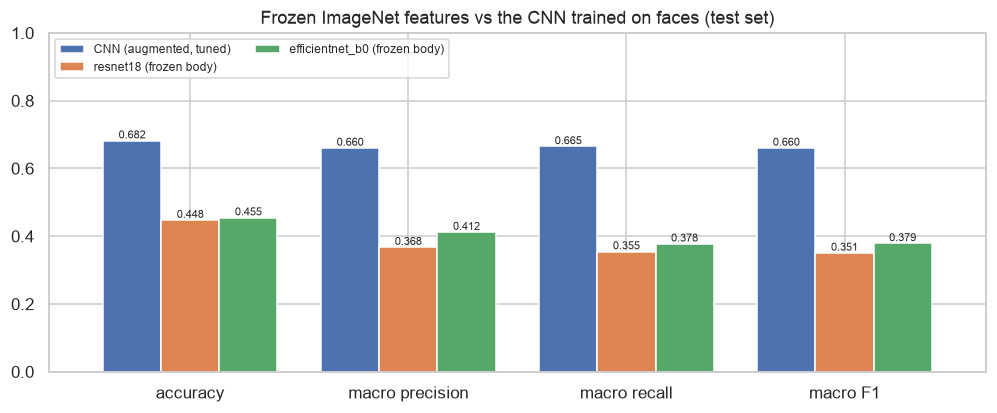

In [61]:
# Visualizing evaluation Metric Score chart
score_chart(["CNN (augmented, tuned)", "resnet18 (frozen body)", "efficientnet_b0 (frozen body)"],
            "Frozen ImageNet features vs the CNN trained on faces (test set)", "model3_frozen_scores.png")

**Transfer learning:** ResNet18 (11.2M parameters) and EfficientNet-B0 (4.0M), both pre-trained on 1.2 million ImageNet photos. Their early layers already detect edges, textures and shapes. Each face is resized to 128x128 and copied to 3 channels inside the model, and the 1,000-class ImageNet head is replaced by dropout and a new 7-class layer.

**Step 1, frozen body ("feature extraction"):** only the new head is trained, for 3 epochs, and the ImageNet layers stay fixed.
- ResNet18: test accuracy 44.8%, macro F1 0.351.
- EfficientNet-B0: test accuracy 45.5%, macro F1 0.379.

That is no better than the HOG baseline and far below the CNN trained on faces (68.2%). ImageNet features describe objects (dogs, cars, textures), not the small muscle movements of a face, so they can't be used as they are. This step took only 14 and 24 seconds, because the body doesn't need gradients.

#### 2. Cross- Validation & Hyperparameter Tuning

epoch  1  train loss 1.783  val loss 1.286  val acc 0.524  val macro F1 0.440  (13s)
epoch  2  train loss 1.552  val loss 1.192  val acc 0.577  val macro F1 0.514  (13s)
epoch  3  train loss 1.445  val loss 1.101  val acc 0.599  val macro F1 0.536  (13s)
epoch  4  train loss 1.380  val loss 1.051  val acc 0.621  val macro F1 0.559  (13s)
epoch  5  train loss 1.341  val loss 1.106  val acc 0.604  val macro F1 0.546  (13s)
epoch  6  train loss 1.287  val loss 1.011  val acc 0.642  val macro F1 0.575  (13s)
epoch  7  train loss 1.255  val loss 1.010  val acc 0.649  val macro F1 0.594  (13s)
epoch  8  train loss 1.207  val loss 0.997  val acc 0.648  val macro F1 0.600  (13s)
epoch  9  train loss 1.168  val loss 0.970  val acc 0.668  val macro F1 0.624  (13s)
epoch 10  train loss 1.117  val loss 0.974  val acc 0.667  val macro F1 0.617  (13s)
epoch 11  train loss 1.070  val loss 1.008  val acc 0.657  val macro F1 0.616  (13s)
epoch 12  train loss 1.024  val loss 0.974  val acc 0.668  val ma

,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
resnet18 (fine-tuned),0.6733,0.6445,0.6393,0.6388,0.6728,0.6874,0.6723,0.6672,0.667,0.6856


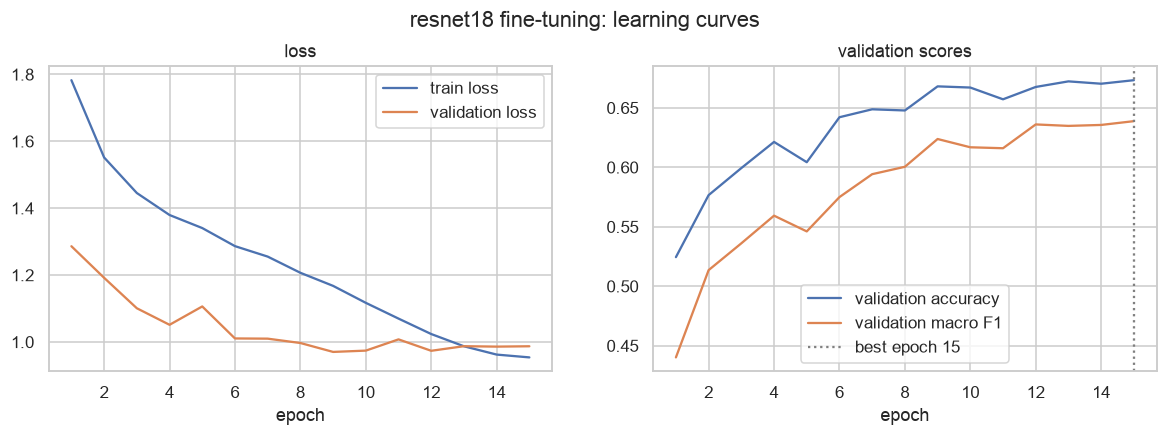

epoch  1  train loss 1.863  val loss 1.479  val acc 0.449  val macro F1 0.374  (25s)
epoch  2  train loss 1.622  val loss 1.266  val acc 0.533  val macro F1 0.453  (23s)
epoch  3  train loss 1.477  val loss 1.126  val acc 0.596  val macro F1 0.537  (23s)
epoch  4  train loss 1.391  val loss 1.082  val acc 0.604  val macro F1 0.548  (23s)
epoch  5  train loss 1.332  val loss 1.060  val acc 0.620  val macro F1 0.570  (23s)
epoch  6  train loss 1.273  val loss 1.036  val acc 0.642  val macro F1 0.593  (23s)
epoch  7  train loss 1.238  val loss 1.013  val acc 0.653  val macro F1 0.610  (23s)
epoch  8  train loss 1.177  val loss 1.004  val acc 0.647  val macro F1 0.614  (23s)
epoch  9  train loss 1.137  val loss 1.008  val acc 0.655  val macro F1 0.617  (23s)
epoch 10  train loss 1.091  val loss 0.997  val acc 0.660  val macro F1 0.619  (23s)
epoch 11  train loss 1.054  val loss 1.017  val acc 0.660  val macro F1 0.626  (23s)
epoch 12  train loss 1.023  val loss 1.005  val acc 0.661  val ma

,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
efficientnet_b0 (fine-tuned),0.6621,0.6351,0.626,0.6271,0.6606,0.6761,0.6549,0.6569,0.652,0.6751


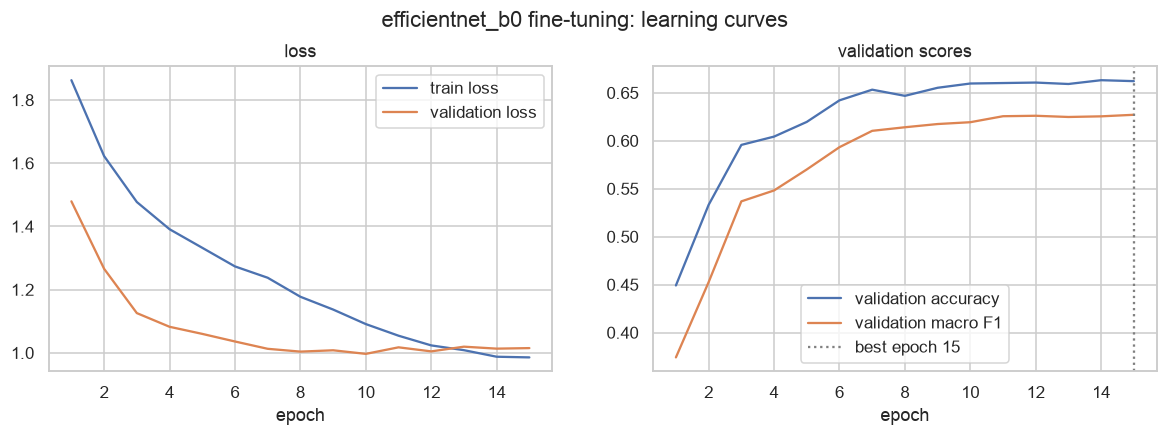

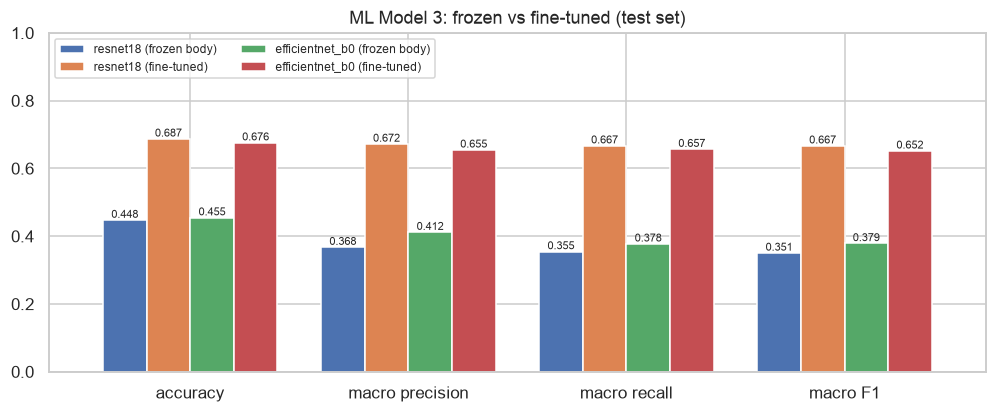

In [62]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Step 2: fine-tune the whole network. The setting that matters most in transfer learning is how much of the
# pre-trained network is retrained, so frozen (step 1) is compared with fully fine-tuned here, for both backbones.
# The new head learns with a top rate of 1e-3 and the pre-trained body with 3e-4 (smaller, so the ImageNet
# knowledge is adjusted, not wiped out), one-cycle schedule, augmentation, early stopping after 5 epochs.
for name in ["resnet18", "efficientnet_b0"]:
    t0 = time.time()
    m, h = deepfer.train_model(TL[name], Xtr, ytr, Xva, yva, DEVICE, epochs=E(15), lr=1e-3, lr_body=3e-4,
                               class_weights=CW, patience=5)
    print(f"{name}: fine-tuning {(time.time() - t0) / 60:.1f} min")
    evaluate(f"{name} (fine-tuned)", softmax(logits(m, Xva)), softmax(logits(m, Xte)))
    TL[name], TL_HIST[name] = m, h
    deepfer.save_model(m, f"models/{name}.pt", name, {"size": 128})
    plot_history(h, f"{name} fine-tuning: learning curves", f"model3_{name}_history.png")
score_chart(["resnet18 (frozen body)", "resnet18 (fine-tuned)", "efficientnet_b0 (frozen body)", "efficientnet_b0 (fine-tuned)"],
            "ML Model 3: frozen vs fine-tuned (test set)", "model3_tuned_scores.png")

##### Which hyperparameter optimization technique have you used and why?

In transfer learning the most important setting is **how much of the pre-trained network to retrain**, so I compared a frozen body (step 1) with full fine-tuning (step 2) for two architectures, judged on the validation set. For fine-tuning I used settings that are standard for this kind of adaptation:
- a smaller top learning rate for the pre-trained body (3e-4) than for the new head (1e-3), so the ImageNet knowledge is adjusted rather than wiped out (discriminative learning rates)
- the one-cycle schedule with warm-up, so the first steps don't destroy the pre-trained weights
- the class weights and augmentation that won for the CNN
- early stopping after 5 epochs without gain

A full grid search over these on two networks at 128x128 was beyond the free GPU time, so the comparison is between the two depths of training and the two backbones.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a very large improvement from fine-tuning:

| | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| ResNet18 frozen | 0.448 | 0.368 | 0.355 | 0.351 |
| ResNet18 fine-tuned | 0.687 | 0.672 | 0.667 | 0.667 |
| EfficientNet-B0 frozen | 0.455 | 0.412 | 0.378 | 0.379 |
| EfficientNet-B0 fine-tuned | 0.676 | 0.655 | 0.657 | 0.652 |

Fine-tuning adds 22-24 points of accuracy and 27-32 points of macro F1. **ResNet18 fine-tuned is the best single model** (68.7%), half a point above my own CNN and 1.1 points above EfficientNet-B0. It also trained faster: 13 seconds per epoch against 23 for EfficientNet, whose depthwise convolutions are less efficient on the GPU. Both learning curves show no overfitting (the validation loss stays flat near 0.97-1.0), and both were still slowly improving at epoch 15. Pre-training helped by giving a strong start: ResNet18 reached 52% validation accuracy after one fine-tuning epoch, the CNN from scratch only 31%.

#### 3. Combining the models: mirrored faces and an ensemble

In [63]:
# From here on every score comes from the saved model files. On my Mac the Apple GPU backend of PyTorch
# sometimes changed weights that sat in GPU memory after training (found by comparing them with the saved
# files), so each network is checked against its file before it is used and reloaded if anything changed.
FILES = {"CNN": "deepfer_cnn.pt", "ResNet18": "resnet18.pt", "EfficientNet-B0": "efficientnet_b0.pt"}
REF = {n: torch.load(f"models/{f}", map_location="cpu", weights_only=False)["state_dict"] for n, f in FILES.items()}
NETS = {n: deepfer.load_model(f"models/{f}", DEVICE)[0] for n, f in FILES.items()}
RELOADS = []


def net(name):
    """The network on the GPU, identical to its saved file (reloaded from the file if it changed)."""
    sd = NETS[name].state_dict()
    if any(not torch.equal(sd[k].detach().cpu(), v) for k, v in REF[name].items()):
        RELOADS.append(name)
        NETS[name] = deepfer.load_model(f"models/{FILES[name]}", DEVICE)[0]
    return NETS[name]


# the evaluation pictures stay in normal memory, every batch is copied to the GPU when it is scored
Xva_c, Xte_c = torch.from_numpy(X[va_idx]), torch.from_numpy(X[te_idx])
Z = {(n, t): (logits(net(n), Xva_c, t), logits(net(n), Xte_c, t)) for n in NETS for t in (False, True)}
combo_rows = []
for tta in (False, True):
    for k in (1, 2, 3):
        for members in itertools.combinations(NETS, k):
            zv = np.mean([Z[(n, tta)][0] for n in members], 0)
            sc = deepfer.scores(y_va, zv.argmax(1))
            combo_rows.append({"members": " + ".join(members), "n": k, "mirror TTA": tta,
                               "val accuracy": sc["accuracy"], "val macro F1": sc["macro F1"]})
combos = pd.DataFrame(combo_rows).sort_values("val macro F1", ascending=False).reset_index(drop=True)
display(combos.round(4))

# Pick the best on validation macro F1, but take a smaller combination if it is within 0.003 (cheaper, faster)
top = combos.iloc[0]["val macro F1"]
pick = combos[combos["val macro F1"] >= top - 0.003].sort_values(["n", "val macro F1"], ascending=[True, False]).iloc[0]
single_rank = combos[combos["n"] == 1].drop_duplicates("members")["members"].tolist()   # best single network first
FINAL_MEMBERS = sorted(pick["members"].split(" + "), key=single_rank.index)
FINAL_TTA = bool(pick["mirror TTA"])
FINAL_NAME = "Final: " + " + ".join(FINAL_MEMBERS) + (" with TTA" if FINAL_TTA else "")
print("chosen:", FINAL_NAME)


def final_logits(Xd):
    return np.mean([logits(net(n), Xd, FINAL_TTA) for n in FINAL_MEMBERS], 0)


zf_va, zf_te = final_logits(Xva_c), final_logits(Xte_c)
evaluate(FINAL_NAME, softmax(zf_va), softmax(zf_te))
best_single = single_rank[0]
evaluate(f"{best_single} (single, TTA)", softmax(Z[(best_single, True)][0]), softmax(Z[(best_single, True)][1]), show=False)

,members,n,mirror TTA,val accuracy,val macro F1
0,CNN + ResNet18 + EfficientNet-B0,3,False,0.6972,0.6618
1,CNN + ResNet18,2,True,0.6987,0.6590
2,ResNet18 + EfficientNet-B0,2,True,0.6923,0.6589
3,CNN + ResNet18 + EfficientNet-B0,3,True,0.6975,0.6585
4,ResNet18 + EfficientNet-B0,2,False,0.6873,0.6566
5,CNN + ResNet18,2,False,0.6953,0.6558
6,CNN + EfficientNet-B0,2,True,0.6915,0.6525
7,CNN + EfficientNet-B0,2,False,0.6851,0.6486
8,ResNet18,1,True,0.6826,0.6418
9,ResNet18,1,False,0.6733,0.6388


chosen: Final: ResNet18 + CNN with TTA


,val accuracy,val macro precision,val macro recall,val macro F1,val weighted F1,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
Final: ResNet18 + CNN with TTA,0.6987,0.6713,0.6543,0.659,0.6969,0.7066,0.6958,0.6865,0.6883,0.705


**Combining models helps.** Each network makes different mistakes, so averaging their scores cancels some of them. Mirroring the face (TTA) also helps because faces are roughly symmetric. On validation:
- Mirroring helped ResNet18 (+0.3 points of macro F1) and EfficientNet (+0.7) but not the CNN, which already sees mirrored faces half of the time in training.
- The best combination was all three networks (validation macro F1 0.662). **ResNet18 + CNN with mirroring** was within 0.003 (0.659) with two networks instead of three.

Following my rule of taking the smaller model when the gain is that small, the final model is **ResNet18 + DeepFER-Net with mirrored faces**. It is cheaper and faster for real time. On the test set it reaches **70.7% accuracy and macro F1 0.688**, against 69.5% for the best single network with mirroring.

A note on the GPU: during the project, PyTorch on my Mac's new Apple M6 GPU froze in training and sometimes corrupted weights held in GPU memory. I caught it by comparing the networks with their saved files. So the final training ran on a Colab T4 GPU, and from here on every network is checked against its saved file before use. On Colab no network ever had to be reloaded.

#### 4. The final model on the test set

,precision,recall,f1-score,support
angry,0.645,0.607,0.626,935.000
disgust,0.714,0.701,0.708,107.000
fear,0.613,0.485,0.542,1002.000
happy,0.904,0.886,0.895,1819.000
neutral,0.605,0.778,0.680,1208.000
sad,0.582,0.577,0.579,1124.000
surprise,0.808,0.771,0.789,757.000
accuracy,0.707,0.707,0.707,0.707
macro avg,0.696,0.686,0.688,6952.000
weighted avg,0.710,0.707,0.705,6952.000


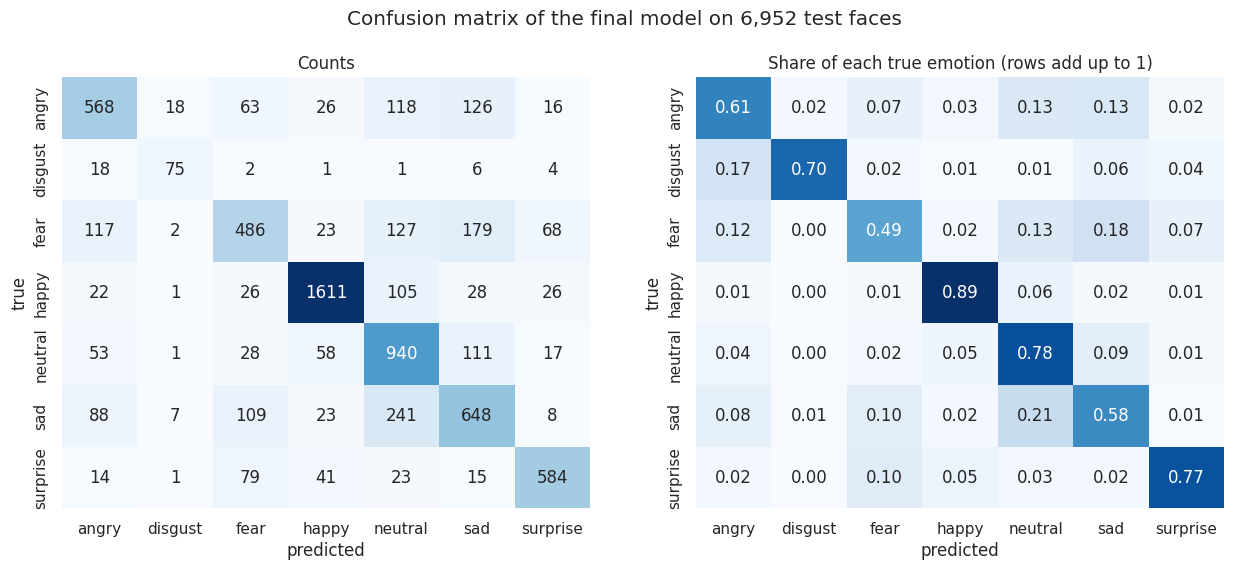

test accuracy 0.7066 (95% CI 0.6966-0.7171)
test macro F1 0.6883 (95% CI 0.6740-0.7033)
vs ResNet18 (single, TTA): final right & other wrong 316, the opposite 233, McNemar p-value 4.55e-04
vs CNN (augmented, tuned): final right & other wrong 424, the opposite 254, McNemar p-value 6.85e-11
vs HOG+LBP LR (tuned): final right & other wrong 2202, the opposite 430, McNemar p-value 2.11e-285


In [64]:
# The final model on the test set: every emotion, the confusion matrix and how sure we can be of the numbers
pred_te = zf_te.argmax(1)
rep = pd.DataFrame(classification_report(y_te, pred_te, target_names=CLASSES, output_dict=True)).T
display(rep.round(3))
rep.round(4).to_csv("outputs/per_emotion_report.csv")

cm = confusion_matrix(y_te, pred_te)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_title("Counts"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False)
ax[1].set_title("Share of each true emotion (rows add up to 1)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.suptitle(f"Confusion matrix of the final model on {len(y_te):,} test faces", y=1.0)
save("final_confusion_matrix.png")

# 95% bootstrap confidence intervals (1,000 resamples of the test set)
rs = np.random.RandomState(SEED)
boot = []
for _ in range(200 if QUICK else 1000):
    s = rs.randint(0, len(y_te), len(y_te))
    boot.append((accuracy_score(y_te[s], pred_te[s]), f1_score(y_te[s], pred_te[s], average="macro")))
boot = np.array(boot)
print(f"test accuracy {accuracy_score(y_te, pred_te):.4f} (95% CI {np.percentile(boot[:, 0], 2.5):.4f}-{np.percentile(boot[:, 0], 97.5):.4f})")
print(f"test macro F1 {f1_score(y_te, pred_te, average='macro'):.4f} (95% CI {np.percentile(boot[:, 1], 2.5):.4f}-{np.percentile(boot[:, 1], 97.5):.4f})")

# McNemar test: is the final model really better than another model on the same test faces?
def mcnemar(pred_a, pred_b):
    a_ok, b_ok = pred_a == y_te, pred_b == y_te
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return b, c, (stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0)
for other in [f"{best_single} (single, TTA)", "CNN (augmented, tuned)", "HOG+LBP LR (tuned)"]:
    b, c, p = mcnemar(pred_te, PROBS[other][1].argmax(1))
    print(f"vs {other}: final right & other wrong {b}, the opposite {c}, McNemar p-value {p:.2e}")

**The final model on 6,952 test faces it never saw:**
- **Accuracy 70.7%** (95% bootstrap interval 69.7-71.7%) and **macro F1 0.688** (interval 0.674-0.703), with macro precision 0.696 and macro recall 0.687.
- **Per emotion:**
  - **happy:** F1 0.89 (precision 0.90, recall 0.89)
  - **surprise:** F1 0.79
  - **disgust:** F1 0.71, good despite only 298 training pictures
  - **neutral:** F1 0.68, with high recall (0.78) but low precision (0.60): it is the model's "default" answer when unsure
  - **angry:** F1 0.63
  - **sad:** F1 0.58
  - **fear:** F1 0.54, the hardest, with recall 0.49: half of the fearful faces are missed
- **Is it really better? (McNemar tests on the same test faces)**
  - Against the best single network (ResNet18 with mirroring), the final model is right on 316 faces where ResNet18 is wrong, and wrong on 233 where ResNet18 is right: p = 0.0005.
  - Against the CNN: 424 against 254, p = 7e-11.
  - Against the classic model: 2,202 against 430, p = 2e-285.

  All differences are statistically significant.

For context, people agree with these labels only about 65% of the time (Goodfellow et al., 2013, on the original FER-2013 data), so 70.7% is at the level of a careful human reader. The confidence interval is narrow because the test set is large.

#### 5. Where does it go wrong? Error analysis

,true,predicted,faces,share of true class
34,sad,neutral,241,0.214
16,fear,sad,179,0.179
15,fear,neutral,127,0.127
4,angry,sad,126,0.135
3,angry,neutral,118,0.126
12,fear,angry,117,0.117
28,neutral,sad,111,0.092
32,sad,fear,109,0.097


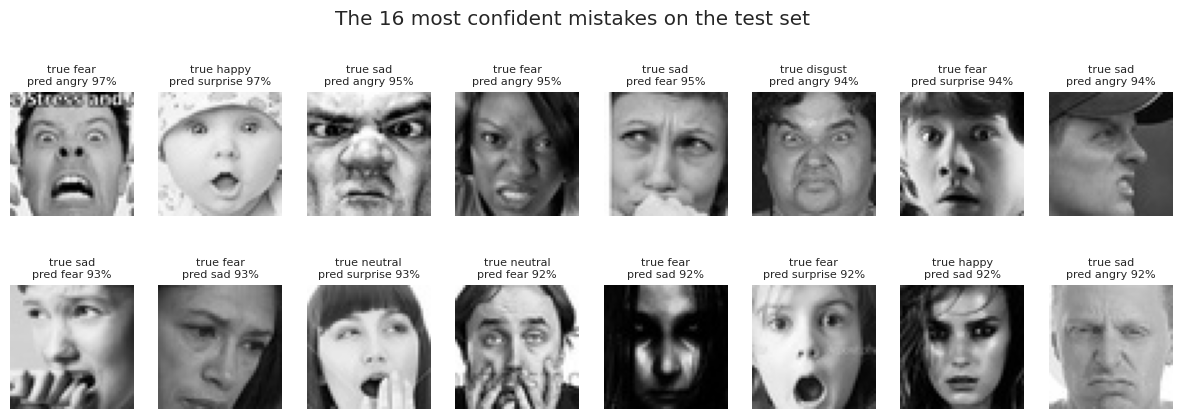

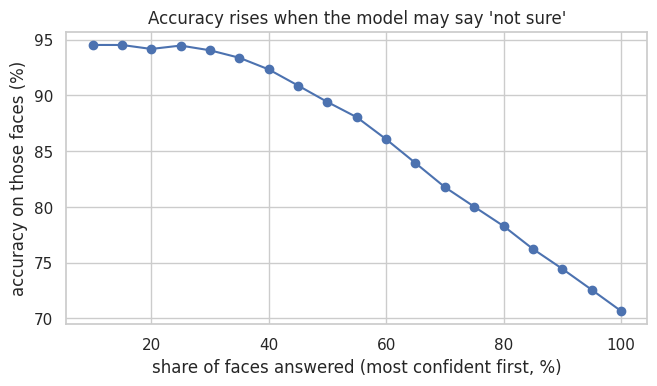

answer the 50% most confident faces: accuracy 0.894, confidence cut-off 0.71
answer the 70% most confident faces: accuracy 0.818, confidence cut-off 0.54
answer the 90% most confident faces: accuracy 0.744, confidence cut-off 0.38


In [65]:
# Where does it go wrong? The most common mix-ups, confident mistakes, and accuracy against confidence
pairs = [(CLASSES[i], CLASSES[j], cm[i, j], cmn[i, j]) for i in range(7) for j in range(7) if i != j]
pairs = pd.DataFrame(pairs, columns=["true", "predicted", "faces", "share of true class"]).sort_values("faces", ascending=False)
display(pairs.head(8).round(3))

p_te = softmax(zf_te)
conf = p_te.max(1)
wrong = np.where(pred_te != y_te)[0]
worst = wrong[np.argsort(-conf[wrong])][:16]
fig, axes = plt.subplots(2, 8, figsize=(15, 4.6))
for ax, k in zip(axes.ravel(), worst):
    ax.imshow(X[te_idx[k]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"true {CLASSES[y_te[k]]}\npred {CLASSES[pred_te[k]]} {conf[k]:.0%}", fontsize=8)
    ax.axis("off")
plt.suptitle("The 16 most confident mistakes on the test set", y=1.02)
save("final_confident_mistakes.png")

# selective prediction: keep only the faces the model is most sure about
order_c = np.argsort(-conf)
cov = np.linspace(0.1, 1.0, 19)
acc_at = [(pred_te[order_c[:int(c * len(order_c))]] == y_te[order_c[:int(c * len(order_c))]]).mean() for c in cov]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(cov * 100, np.array(acc_at) * 100, marker="o")
ax.set_xlabel("share of faces answered (most confident first, %)"); ax.set_ylabel("accuracy on those faces (%)")
ax.set_title("Accuracy rises when the model may say 'not sure'")
save("final_coverage_accuracy.png")
for c in (0.5, 0.7, 0.9):
    n = int(c * len(order_c))
    print(f"answer the {c:.0%} most confident faces: accuracy {(pred_te[order_c[:n]] == y_te[order_c[:n]]).mean():.3f}, "
          f"confidence cut-off {conf[order_c[n - 1]]:.2f}")

**The mistakes are between emotions that look alike:**
- **Sad read as neutral** is the biggest one: 241 faces, 21% of all sad faces.
- **Fear** is read as sad (18%), neutral (13%), angry (12%) and surprise (7%).
- **Angry** is read as sad (13%) and neutral (13%).
- **Disgust** is read as angry (17%).

These are the same pairs that had conflicting labels in the data (chart 9) and similar average faces (chart 14). Some of these "mistakes" are probably label noise. The most confident mistakes show it: several faces labelled fear look clearly angry or surprised.

**Confidence is useful:** if the model only answers when it is sure and says "not sure" otherwise:
- On the 50% of faces it is most confident about (probability above 0.71), it is right **89.4%** of the time.
- On 70% of faces (above 0.54), 81.8%.
- On 90% of faces (above 0.38), 74.4%.

A product can use this trade-off: show the emotion only above a confidence threshold. The app does exactly this.

#### 6. Can the probabilities be trusted? Calibration

temperature T = 0.90
test ECE before 0.0392, after 0.0272
test log loss before 0.8684, after 0.8587


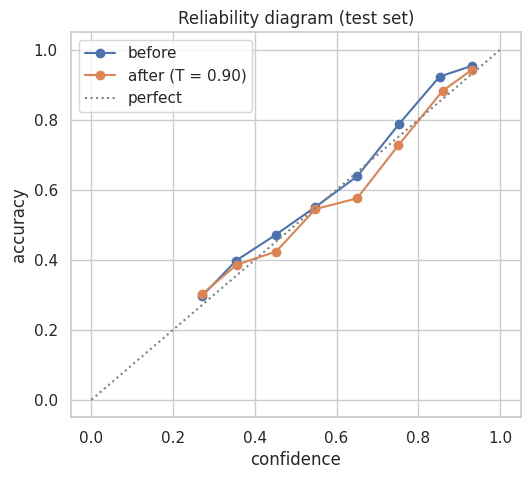

In [66]:
# Can the probabilities be trusted? Temperature scaling, fitted on the validation set
T = deepfer.fit_temperature(torch.tensor(zf_va), torch.tensor(y_va))


def ece(p, y, bins=15):
    """Expected calibration error: the average gap between confidence and real accuracy."""
    c, ok = p.max(1), p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1)
    return sum(abs(ok[m].mean() - c[m].mean()) * m.mean()
               for lo, hi in zip(edges[:-1], edges[1:]) if (m := (c > lo) & (c <= hi)).any())


p_raw, p_cal = softmax(zf_te), softmax(zf_te / T)
print(f"temperature T = {T:.2f}")
print(f"test ECE before {ece(p_raw, y_te):.4f}, after {ece(p_cal, y_te):.4f}")
print(f"test log loss before {F.cross_entropy(torch.tensor(zf_te), torch.tensor(y_te)).item():.4f}, "
      f"after {F.cross_entropy(torch.tensor(zf_te / T), torch.tensor(y_te)).item():.4f}")
fig, ax = plt.subplots(figsize=(5.8, 5))
for p, lab in [(p_raw, "before"), (p_cal, f"after (T = {T:.2f})")]:
    c, ok = p.max(1), p.argmax(1) == y_te
    edges = np.linspace(0, 1, 11)
    mids = [(c[(c > lo) & (c <= hi)].mean(), ok[(c > lo) & (c <= hi)].mean()) for lo, hi in zip(edges[:-1], edges[1:]) if ((c > lo) & (c <= hi)).sum() > 20]
    ax.plot(*zip(*mids), marker="o", label=lab)
ax.plot([0, 1], [0, 1], ls=":", c="grey", label="perfect")
ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("Reliability diagram (test set)")
save("final_calibration.png")

A model is calibrated when "80% sure" means it is right 80% of the time. The combined model was slightly **under-confident**: averaging two networks and two views, plus label smoothing, flattens the probabilities. Temperature scaling found T = 0.90 on the validation set. That sharpens the probabilities a little.

On the test set the calibration error (ECE) fell from 0.039 to 0.027 and the log loss from 0.868 to 0.859. The reliability diagram is close to the diagonal after scaling.

This matters for the app: the confidence it shows and the "not sure" threshold mean what they say. Temperature scaling doesn't change which emotion is predicted, so the accuracy stays the same.

#### 7. How well does it hold up? Lighting, noise, blur and a covered mouth

,accuracy,macro F1,accuracy drop
condition,,,
original,0.7066,0.6883,0.0000
original + CLAHE,0.6748,0.6547,-0.0318
dark (x0.45),0.6965,0.6763,-0.0101
dark (x0.45) + CLAHE,0.6894,0.6670,-0.0171
very dark (x0.2),0.6519,0.6240,-0.0547
very dark (x0.2) + CLAHE,0.6850,0.6589,-0.0216
bright (+90),0.6677,0.6316,-0.0388
low contrast (x0.4),0.6942,0.6701,-0.0124
noise (sd 15),0.3967,0.3495,-0.3098


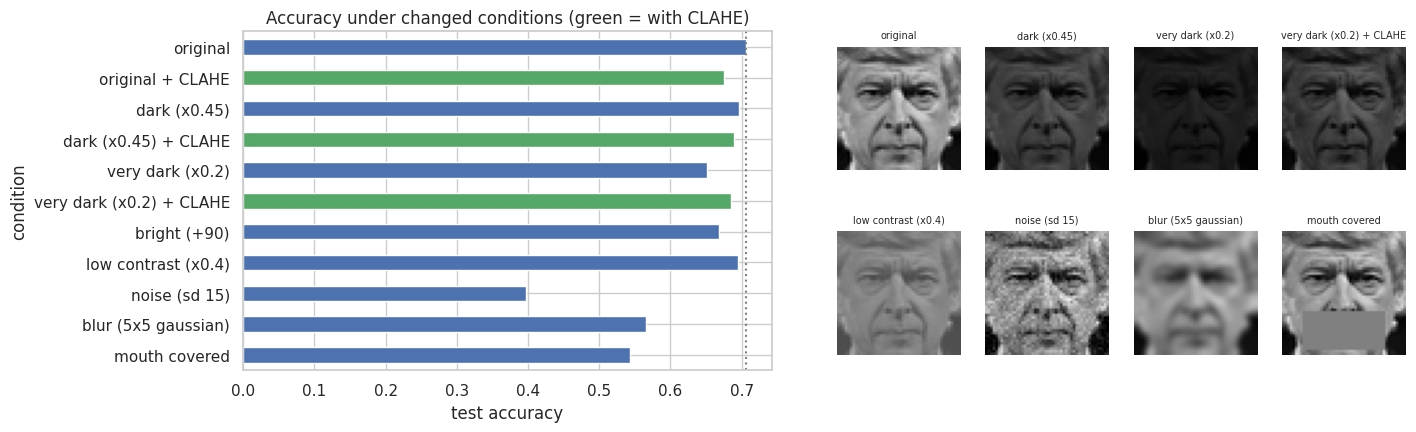

In [67]:
# Stress test: the same test faces with darker or brighter lighting, low contrast, noise, blur and a covered mouth
rs = np.random.RandomState(SEED)


def perturb(xu8, kind):
    x = xu8.astype(np.float32)
    mean = x.mean((1, 2), keepdims=True)
    if kind.startswith("dark"):
        x = x * 0.45
    elif kind.startswith("very dark"):
        x = x * 0.2
    elif kind == "bright (+90)":
        x = x + 90
    elif kind == "low contrast (x0.4)":
        x = (x - mean) * 0.4 + mean
    elif kind == "noise (sd 15)":
        x = x + rs.normal(0, 15, x.shape)
    elif kind == "blur (5x5 gaussian)":
        x = np.stack([cv2.GaussianBlur(a, (5, 5), 1.2) for a in x])
    elif kind == "mouth covered":
        x[:, 31:46, 8:40] = 128
    x = np.clip(x, 0, 255).astype(np.uint8)
    if kind.endswith("+ CLAHE"):
        x = np.stack([deepfer.equalize(a) for a in x])
    return x


rob_idx = te_idx[:600] if QUICK else te_idx
conds = ["original", "original + CLAHE", "dark (x0.45)", "dark (x0.45) + CLAHE", "very dark (x0.2)", "very dark (x0.2) + CLAHE",
         "bright (+90)", "low contrast (x0.4)", "noise (sd 15)", "blur (5x5 gaussian)", "mouth covered"]
rob = []
for kind in conds:
    sc = deepfer.scores(Y[rob_idx], final_logits(torch.from_numpy(perturb(X[rob_idx], kind))).argmax(1))
    rob.append({"condition": kind, "accuracy": sc["accuracy"], "macro F1": sc["macro F1"]})
rob = pd.DataFrame(rob).set_index("condition")
rob["accuracy drop"] = rob["accuracy"] - rob.loc["original", "accuracy"]
display(rob.round(4))
rob.round(4).to_csv("outputs/robustness.csv")

fig = plt.figure(figsize=(15, 4.4))
ax = fig.add_subplot(1, 2, 1)
rob["accuracy"].plot.barh(ax=ax, color=["#55A868" if "CLAHE" in c else "#4C72B0" for c in rob.index])
ax.axvline(rob.loc["original", "accuracy"], ls=":", c="grey"); ax.invert_yaxis(); ax.set_xlabel("test accuracy")
ax.set_title("Accuracy under changed conditions (green = with CLAHE)")
i0 = rob_idx[3]
for k, kind in enumerate(["original", "dark (x0.45)", "very dark (x0.2)", "very dark (x0.2) + CLAHE", "low contrast (x0.4)", "noise (sd 15)", "blur (5x5 gaussian)", "mouth covered"]):
    a = fig.add_subplot(2, 8, 5 + k + (k // 4) * 4)
    a.imshow(perturb(X[[i0]], kind)[0], cmap="gray", vmin=0, vmax=255); a.set_title(kind, fontsize=7); a.axis("off")
save("final_robustness.png")

I changed all 6,952 test faces in one way at a time and measured the final model again:

| Condition | Accuracy | Change |
|---|---|---|
| original | 70.7% | |
| dark (55% less light) | 69.7% | -1.0 |
| very dark (80% less light) | 65.2% | -5.5 |
| very dark + CLAHE | 68.5% | -2.2 |
| bright (+90 grey levels) | 66.8% | -3.9 |
| low contrast | 69.4% | -1.2 |
| blur (5x5 Gaussian) | 56.6% | -14.0 |
| mouth covered (like a mask) | 54.3% | -16.3 |
| noise (standard deviation 15) | 39.7% | -31.0 |

- **Lighting is handled well**, thanks to the brightness and contrast augmentation. For very dark faces, **CLAHE** (histogram equalisation, tile by tile) recovers 3.3 of the 5.5 lost points. On normal faces CLAHE hurts (-3.2), because the model never saw equalised faces in training. So it should only be switched on for dark images.
- **Blur and a covered mouth** cost 14-16 points. A mask hides the main clue for happy and disgust.
- **Noise is the weak point.** Grainy pictures, like a cheap webcam in a dark room, drop accuracy by 31 points. The training pictures are clean, and the augmentation has no noise. Adding noise to the augmentation is the obvious next step.

For poor lighting, the answer is therefore: lighting augmentation in training, CLAHE for very dark frames at inference, and noise augmentation, because low light usually comes with sensor noise.

#### 8. Speed: is it fast enough for real time?

In [68]:
# Speed: time to score one face, on this machine's GPU and on the CPU (batch of 1, the real-time case)
def time_ms(fn, n=40):
    for _ in range(5):
        fn()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000


one = torch.from_numpy(X[te_idx[:1]])
lat = []
for name, m in NETS.items():
    row = {"model": name, "parameters (M)": deepfer.count_params(m) / 1e6,
           "file size (MB)": os.path.getsize(f"models/{FILES[name]}") / 1e6}
    for dev in ([DEVICE, torch.device("cpu")] if DEVICE.type != "cpu" else [DEVICE]):
        mm, _ = deepfer.load_model(f"models/{FILES[name]}", dev)     # a fresh copy from the saved file
        x1 = deepfer.to_batch(one, dev)

        def run():
            with torch.no_grad():
                mm(x1)
            deepfer.sync(dev)
        row[f"ms per face ({dev.type})"] = time_ms(run)
    lat.append(row)
lat = pd.DataFrame(lat).set_index("model")
fin = lat.loc[FINAL_MEMBERS].sum() * (2 if FINAL_TTA else 1)        # members run one after another, twice with TTA
lat.loc["final model"] = fin
lat.loc["final model", ["parameters (M)", "file size (MB)"]] = lat.loc[FINAL_MEMBERS, ["parameters (M)", "file size (MB)"]].sum()
display(lat.round(2))
lat.round(3).to_csv("outputs/latency.csv")

# face detection on a 640x480 frame (OpenCV Haar cascade on the CPU)
finder = deepfer.FaceFinder()
frame = cv2.resize(X[te_idx[0]], (640, 480))
det_ms = time_ms(lambda: finder.find(frame), n=20)
for col in [c for c in lat.columns if c.startswith("ms per face")]:
    total = det_ms + lat.loc["final model", col]
    print(f"{col}: detection {det_ms:.1f} ms + emotion {lat.loc['final model', col]:.1f} ms = {total:.1f} ms per frame "
          f"with one face, about {1000 / total:.0f} frames per second")

,parameters (M),file size (MB),ms per face (cuda),ms per face (cpu)
model,,,,
CNN,6.43,25.78,2.62,25.16
ResNet18,11.18,44.80,4.05,23.93
EfficientNet-B0,4.02,16.35,8.12,18.16
final model,17.61,70.58,13.34,98.18


ms per face (cuda): detection 44.6 ms + emotion 13.3 ms = 57.9 ms per frame with one face, about 17 frames per second
ms per face (cpu): detection 44.6 ms + emotion 98.2 ms = 142.7 ms per frame with one face, about 7 frames per second


Timing one face at a time (the real-time case), measured in the Colab notebook:
- **On the T4 GPU:** the CNN takes 2.6 ms, ResNet18 4.0 ms and EfficientNet-B0 8.1 ms. The final model (two networks, each on the face and its mirror image) takes 13.3 ms.
- **On Colab's CPU:** 98 ms. Colab's free CPU is two slow virtual cores, so these numbers are pessimistic.

On my laptop's CPU (Apple M6, measured with the app) the final model needs **13 ms per face** and 31 ms for three faces. Face detection takes about 4 ms per 640x480 frame. The live webcam script processed a test video with four faces at 41 ms per frame, about **24 frames per second**, with no GPU at all.

Optimisations that made this possible:
- Two networks instead of three: three gave only 0.3 points more on validation.
- The face detector runs on a frame shrunk to 480 pixels.
- All faces of a frame are scored in one batch.
- The model files are small: 70 MB for the final model, 17.6M parameters.

To go faster on weak hardware: use only ResNet18 (about half the time, 1.2 points less accuracy), drop the mirror image, or export to ONNX or Core ML with 8-bit quantisation for phones or edge devices.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**Macro F1** was the main metric for every choice (early stopping, tuning and the final model). Then accuracy, per-emotion precision and recall, and the confusion matrix.
- **Macro F1** gives every emotion the same weight. In this data accuracy can look good while disgust or fear is ignored. A business using the system for every customer or user needs it to work for every emotion, not only for the common smiling faces.
- **Accuracy** is the number people understand. It shows how often the system is right overall (70.7%).
- **Per-emotion precision and recall** decide whether an application is safe. A tool that flags angry customers needs good precision for angry (0.65 now), or supervisors get false alarms. A wellbeing app needs good recall for sad and fear (0.58 and 0.49 now), or it misses people who need help.
- **Confidence and calibration** turn the model into a decision tool. With an honest probability, a product can act only when the model is sure (89% right on the most confident half of faces) and ask a human otherwise.
- **Latency** (13 ms per face on a laptop CPU) decides whether real-time use is possible at all.

The positive business impact comes from using the model for trends and support: average customer mood over a day, frustration in a user study, or a prompt for a human to check in. The model shouldn't make final decisions about one person.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Final model: ResNet18 (fine-tuned) + DeepFER-Net (my CNN), averaged, each also scoring the mirrored face, with temperature scaling.**

Why:
- **Best validation score at the lowest cost.** It is within 0.003 macro F1 of the three-network ensemble but needs one network less, which matters for real time.
- **Best on the test set:** 70.7% accuracy and macro F1 0.688. That is significantly better than the best single network (p = 0.0005), the CNN alone (p < 1e-10) and the classic model.
- **The two networks complement each other.** ResNet18 brings ImageNet knowledge at 128x128 and the CNN works at the native 48x48 with its own filters. Their mistakes overlap less than those of two similar networks.
- **Fast enough:** 13 ms per face on a laptop CPU, so the webcam runs at more than 20 frames per second without a GPU.
- **Honest probabilities** after temperature scaling, which the app uses for its "not sure" message.

If only one network could be used, I would pick fine-tuned ResNet18 with mirroring (69.5%).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

I used two model explainability tools that work for image models:

1. **Grad-CAM** (gradient-weighted class activation mapping). It takes the last convolution block, measures how much each feature map pushes the score of the predicted emotion up (the gradients), and turns that into a heat map over the face. Red areas are the ones the network relied on.
2. **Occlusion sensitivity.** It covers one region of every test face with grey (forehead, eyes and brows, nose, mouth) and measures how much the recall of each emotion drops. This works for the whole final model, including the ensemble, and gives a "feature importance" per face region.

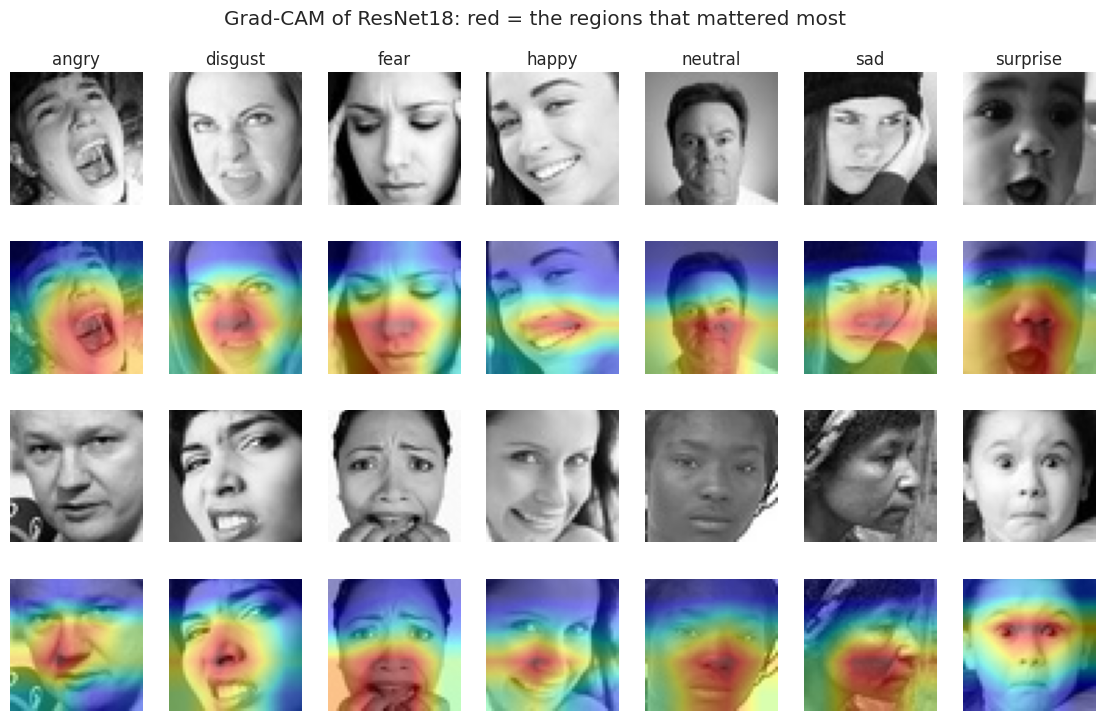

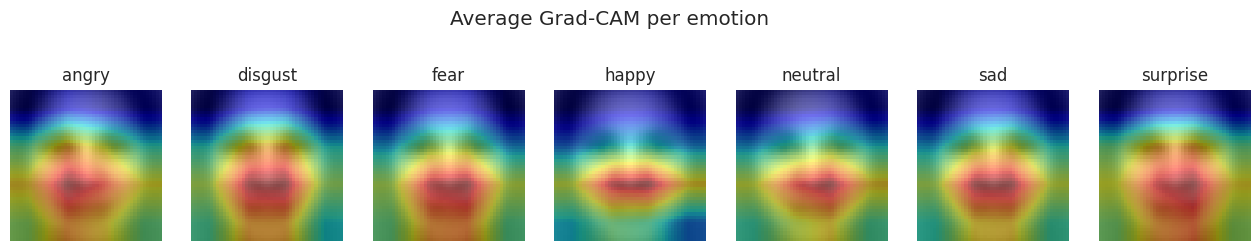

angry     share of attention: eyes band 28%, mouth band 38%
disgust   share of attention: eyes band 29%, mouth band 39%
fear      share of attention: eyes band 25%, mouth band 42%
happy     share of attention: eyes band 25%, mouth band 39%
neutral   share of attention: eyes band 25%, mouth band 42%
sad       share of attention: eyes band 27%, mouth band 39%
surprise  share of attention: eyes band 29%, mouth band 38%


In [69]:
# Explainability 1: Grad-CAM. Which parts of the face pushed the network to its answer?
# (shown for the first network of the final model on correctly classified test faces)
explain_net = net(FINAL_MEMBERS[0])
rs = np.random.RandomState(4)
fig, axes = plt.subplots(4, 7, figsize=(14, 8.4))
for k, c in enumerate(CLASSES):
    ok = np.where((y_te == LABEL_ID[c]) & (pred_te == y_te))[0]
    if len(ok) < 2:                                   # fall back to any faces of the emotion
        ok = np.where(y_te == LABEL_ID[c])[0]
    pick4 = rs.choice(ok, 2, replace=False)
    cams, _ = deepfer.grad_cam(explain_net, deepfer.to_batch(torch.from_numpy(X[te_idx[pick4]]), DEVICE))
    for r, (j, cam_) in enumerate(zip(pick4, cams)):
        axes[2 * r, k].imshow(X[te_idx[j]], cmap="gray"); axes[2 * r, k].axis("off")
        axes[2 * r + 1, k].imshow(X[te_idx[j]], cmap="gray"); axes[2 * r + 1, k].imshow(cam_, cmap="jet", alpha=0.45)
        axes[2 * r + 1, k].axis("off")
    axes[0, k].set_title(c)
plt.suptitle(f"Grad-CAM of {FINAL_MEMBERS[0]}: red = the regions that mattered most", y=0.95)
save("explain_gradcam.png")

# average Grad-CAM per emotion over 150 correct test faces each
avg = {}
for c in CLASSES:
    ok = np.where((y_te == LABEL_ID[c]) & (pred_te == y_te))[0][:150]
    if len(ok) == 0:
        ok = np.where(y_te == LABEL_ID[c])[0][:150]
    cams, _ = deepfer.grad_cam(explain_net, deepfer.to_batch(torch.from_numpy(X[te_idx[ok]]), DEVICE),
                               target=np.full(len(ok), LABEL_ID[c]))
    avg[c] = cams.mean(0)
fig, axes = plt.subplots(1, 7, figsize=(16, 2.8))
for ax, c in zip(axes, CLASSES):
    ax.imshow(overall, cmap="gray"); ax.imshow(avg[c], cmap="jet", alpha=0.5); ax.set_title(c); ax.axis("off")
plt.suptitle("Average Grad-CAM per emotion", y=1.05)
save("explain_gradcam_average.png")
for c in CLASSES:
    a = avg[c]
    print(f"{c:9s} share of attention: eyes band {a[10:24].sum() / (a.sum() + 1e-8):.0%}, mouth band {a[31:46].sum() / (a.sum() + 1e-8):.0%}")

**Grad-CAM (ResNet18, the first network of the final model):**
- For correctly classified faces the heat maps sit on the face, not on the background or the hair. Most of the attention is on the lower and central face: the mouth, the nose and the cheeks. About 38-42% of the attention falls in the mouth band and 25-29% in the eye band.
- For happy faces the red area covers the smile, and for surprise the open mouth.
- The average maps per emotion look similar. ResNet18's last layer at 128x128 input is only 4x4 cells, so Grad-CAM shows the general area rather than fine details like the brows. That is why the occlusion test below is a useful second view.

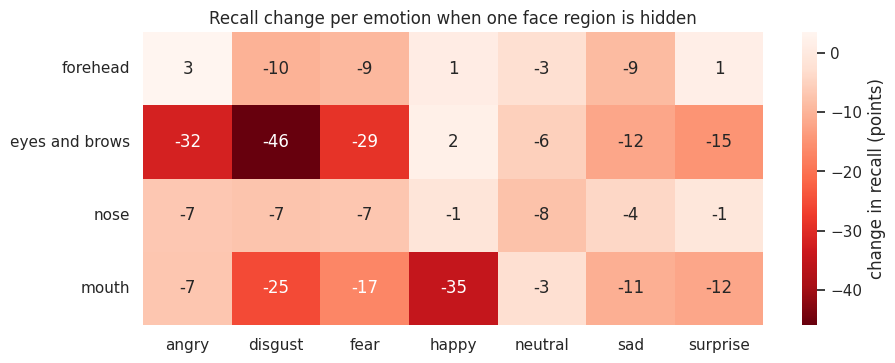

In [70]:
# Explainability 2: occlusion. Cover one region of every test face with grey and see which emotions suffer.
occ_idx = te_idx[:600] if QUICK else te_idx
regions = {"forehead": (slice(0, 10), slice(0, 48)), "eyes and brows": (slice(10, 24), slice(0, 48)),
           "nose": (slice(22, 32), slice(12, 36)), "mouth": (slice(31, 46), slice(8, 40))}
base_pred = final_logits(torch.from_numpy(X[occ_idx])).argmax(1)
yo = Y[occ_idx]
base_rec = pd.Series([(base_pred[yo == i] == i).mean() for i in range(7)], index=CLASSES)
drop = {}
for rname, (rr, cc) in regions.items():
    xo = X[occ_idx].copy()
    xo[:, rr, cc] = 128
    p = final_logits(torch.from_numpy(xo)).argmax(1)
    drop[rname] = pd.Series([(p[yo == i] == i).mean() for i in range(7)], index=CLASSES) - base_rec
drop = pd.DataFrame(drop).T
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(drop * 100, annot=True, fmt=".0f", cmap="Reds_r", ax=ax, cbar_kws={"label": "change in recall (points)"})
ax.set_title("Recall change per emotion when one face region is hidden")
save("explain_occlusion.png")

**Occlusion (feature importance per face region):** I hid one region of all test faces with grey and measured how much the recall of each emotion fell.

| Region hidden | Effect on recall |
|---|---|
| eyes and brows | the strongest effect overall: disgust -46 points, angry -32, fear -29, surprise -15, sad -12. Happy doesn't change (+2) |
| mouth | happy -35, disgust -25, fear -17, surprise -12, sad -11. Angry (-7) and neutral (-3) barely change |
| forehead | small losses for disgust, fear and sad (-9 to -10) |
| nose | small losses for all emotions (-1 to -8) |

So each emotion has its own key region:
- **Happy** is read almost only from the mouth.
- **Angry** is read from the brows and eyes (the frown).
- **Disgust and fear** need both regions.

This matches how facial expressions work, and it explains the stress test: a covered mouth (a mask) mostly hurts happy and disgust. For a product it means cameras must see the whole face, and masks or hands over the mouth make some emotions unreadable.

## ***7.1 Real-time processing: from a camera frame to an emotion***

The real-time pipeline, used by the app and the webcam window:
1. **Read a frame** from the camera and convert it to grayscale.
2. **Find the faces** with OpenCV's Haar cascade face detector, on a copy shrunk to 480 pixels for speed. It ships with OpenCV, so nothing extra has to be downloaded.
3. **Crop each face the same way the training faces were cropped.** I measured on test faces that the dataset's crop is almost exactly the detector's box (3% larger, moved 2% right and down), then resize it to 48x48.
4. **Score all faces of the frame in one batch** with the final model, then temperature scaling.
5. **Smooth over time** (webcam only): each face's probabilities are blended with the same face in the previous frame, so the label doesn't flicker.
6. **Draw** the box, the emotion, the confidence and a bar for each emotion.

The cell below checks two things: whether the detector finds test faces, and whether its crops give the same answers as the dataset's own crops. Then it runs a whole frame with several faces through the pipeline.

faces found by the detector: 1498 of 2000 (75%)
accuracy on those faces: original crops 0.705, crops made by the real-time pipeline 0.686
faces found 4 of 6 | detection 93.8 ms + emotions for all faces 62.9 ms = 156.7 ms per frame (about 6 frames per second)


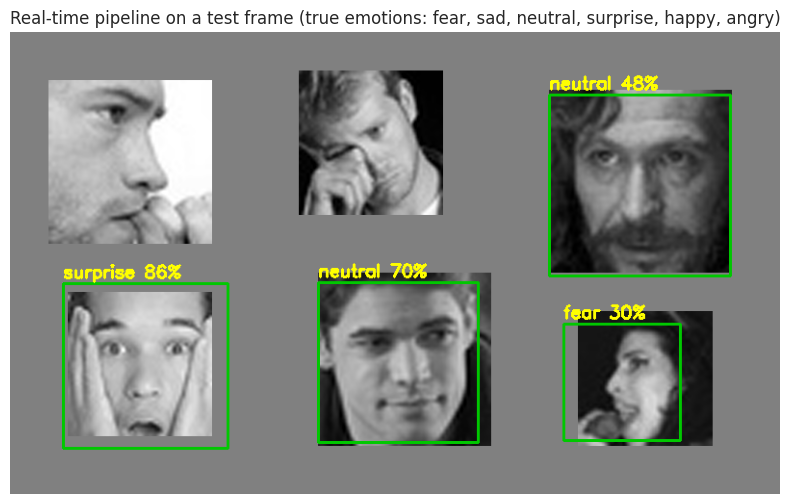

In [71]:
# 1) Does the face detector find the test faces, and do its crops give the same answers as the original crops?
# Every test face is enlarged to 160x160 and put on a grey background, like a face in a photo.
finder = deepfer.FaceFinder()
rs = np.random.RandomState(SEED)
rt_idx = rs.choice(te_idx, 300 if QUICK else 2000, replace=False)
found, crops, keep_i = 0, [], []
for i in rt_idx:
    big = cv2.copyMakeBorder(cv2.resize(X[i], (160, 160), interpolation=cv2.INTER_CUBIC), 48, 48, 48, 48, cv2.BORDER_CONSTANT, value=128)
    boxes = finder.find(big)
    if len(boxes) == 1:
        crops.append(deepfer.crop_face(big, boxes[0])); keep_i.append(i)
keep_i = np.array(keep_i)
acc_orig = (final_logits(torch.from_numpy(X[keep_i])).argmax(1) == Y[keep_i]).mean()
acc_det = (final_logits(torch.from_numpy(np.stack(crops))).argmax(1) == Y[keep_i]).mean()
print(f"faces found by the detector: {len(keep_i)} of {len(rt_idx)} ({len(keep_i) / len(rt_idx):.0%})")
print(f"accuracy on those faces: original crops {acc_orig:.3f}, crops made by the real-time pipeline {acc_det:.3f}")

# 2) A whole frame with several faces through the same pipeline the app and the webcam script use
class NotebookPredictor:                              # the final model in memory, same interface as deepfer.EmotionPredictor
    def predict(self, faces):
        if len(faces) == 0:
            return np.zeros((0, 7))
        return softmax(final_logits(torch.from_numpy(np.stack(faces))) / T)


rs = np.random.RandomState(11)
canvas = np.full((480, 800), 128, np.uint8)
spots = [(40, 50, 170), (300, 40, 150), (560, 60, 190), (60, 270, 150), (320, 250, 180), (590, 290, 140)]
truth = []
for (x0, y0, s), c in zip(spots, rs.permutation(CLASSES)[:6]):
    i = rs.choice(te_idx[y_te == LABEL_ID[c]])            # random test faces, right or wrong
    canvas[y0:y0 + s, x0:x0 + s] = cv2.resize(X[i], (s, s), interpolation=cv2.INTER_CUBIC)
    truth.append(c)
predictor_nb = NotebookPredictor()
t_det = time_ms(lambda: finder.find(canvas), n=10)
boxes, faces, probs = deepfer.analyse_image(canvas, finder, predictor_nb)
t_cls = time_ms(lambda: predictor_nb.predict(faces), n=10)
print(f"faces found {len(boxes)} of 6 | detection {t_det:.1f} ms + emotions for all faces {t_cls:.1f} ms "
      f"= {t_det + t_cls:.1f} ms per frame (about {1000 / (t_det + t_cls):.0f} frames per second)")
show_img = cv2.cvtColor(canvas, cv2.COLOR_GRAY2RGB)
for (x, y, w, h), p in zip(boxes, probs):
    cv2.rectangle(show_img, (x, y), (x + w, y + h), (0, 200, 0), 2)
    cv2.putText(show_img, f"{CLASSES[p.argmax()]} {p.max():.0%}", (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
plt.figure(figsize=(10, 6)); plt.imshow(show_img); plt.axis("off")
plt.title("Real-time pipeline on a test frame (true emotions: " + ", ".join(truth) + ")")
save("realtime_demo_frame.png")
_ = cv2.imwrite("outputs/demo_frame.png", canvas)

- **The detector found 75% of the test faces** (1,498 of 2,000) after they were enlarged and placed on a grey background. It misses faces in side view, tilted strongly, or partly covered by hands, the same faces a webcam user would turn away with.
- **The crops of the real-time pipeline lose only 1.9 points** of accuracy against the dataset's own crops (68.6% against 70.5% on the same faces). The crop calibration works.
- **The demo frame:** 4 of the 6 faces were found (the side view and the face with a hand on it were missed). Of those 4, surprise and neutral are right; the happy face was read as neutral and the angry face as fear, which are typical mistakes for this model.
- **Speed:** on Colab's slow CPU, detection plus scoring took 157 ms for the whole frame. On my laptop's CPU the same steps take about 40-80 ms for 4 faces and about 15-20 ms for one face, fast enough for a live webcam.

The biggest real-time risk is the face detector, not the emotion model. A modern detector (for example a small neural network like YuNet) would find more turned faces.

## ***7.2 Application: Streamlit app and live webcam window***

The system can be used in two ways. Both load the saved model files and `deepfer.py`, so they use exactly the steps of this notebook.

**1. The Streamlit web app** (`app/app.py`). Start it from the project folder with `streamlit run app/app.py` and open http://localhost:8501. It has four tabs:
- **Photo**: upload a photo with one or more faces, or pick one of the test pictures. Every face gets a box, its emotion and confidence, a bar chart of all seven probabilities, the 48x48 crop the model really sees and a Grad-CAM heat map. If the confidence is below a threshold set in the sidebar, the app says it is not sure and shows the second guess.
- **Webcam snapshot**: take a picture with the webcam in the browser and get the same analysis.
- **Live webcam**: a button that opens the live window below.
- **Model insights**: the model comparison, the confusion matrix, the Grad-CAM and occlusion maps, the lighting and noise tests and the scores per emotion.

**2. The live webcam window** (`app/webcam.py`, started with `python app/webcam.py` or from the app). It reads the camera with OpenCV and, for every frame, finds the faces, crops them, predicts the emotions in one batch, smooths the probabilities over the last frames so the label doesn't flicker, and draws the box, the label and a small bar chart of all seven emotions next to each face. The frames per second and the milliseconds per frame are shown in the corner. A live window is used instead of the browser because sending every frame through the web page would add delay.

**A typical user workflow:** a support agent or researcher opens the app, points the webcam at a person (or uploads a photo), and reads the emotion and the confidence. Low-confidence answers are marked as unsure instead of being shown as facts.

**Ethics.** Emotion recognition reads something personal. It should only be used with the person's consent, the frames should not be stored, and the output should support a human decision, not replace it. The model sees an expression, not a feeling: a polite smile is classified as happy.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [72]:
# Save the File
# PyTorch models are saved with torch.save (the PyTorch equivalent of a pickle file): the weights plus the
# settings needed to rebuild the network. models/model_card.json says which networks make up the final model,
# whether the mirror trick is used, the temperature and the test scores, so the app loads exactly this model.
card = {"members": [FILES[n] for n in FINAL_MEMBERS], "member_names": FINAL_MEMBERS, "tta": FINAL_TTA,
        "temperature": T, "classes": CLASSES, "input": "48x48 grayscale face, values 0-255 (the model scales them)",
        "test_scores": {k.replace("test ", ""): round(v, 4) for k, v in RESULTS[FINAL_NAME].items() if k.startswith("test")},
        "val_scores": {k.replace("val ", ""): round(v, 4) for k, v in RESULTS[FINAL_NAME].items() if k.startswith("val")},
        "ms_per_face": {c: round(float(v), 2) for c, v in lat.loc["final model"].items() if c.startswith("ms")},
        "trained_on": str(DEVICE), "pixel_mean": PIXEL_MEAN, "pixel_std": PIXEL_STD}
Path("models/model_card.json").write_text(json.dumps(card, indent=2))

comparison = pd.DataFrame(RESULTS).T
comparison.round(4).to_csv("outputs/model_comparison.csv")
for name, h in [("cnn_first", hist_cnn0), ("cnn_tuned", hist_cnn)] + [(k, v) for k, v in TL_HIST.items()]:
    h.to_csv(f"outputs/history_{name}.csv", index=False)

# a few test faces for trying the app (file name = true emotion)
sample_dir = Path("outputs/sample_faces")
sample_dir.mkdir(parents=True, exist_ok=True)
rs = np.random.RandomState(5)
for c in CLASSES:
    for k, i in enumerate(rs.choice(te_idx[y_te == LABEL_ID[c]], 4, replace=False)):
        cv2.imwrite(str(sample_dir / f"{c}_{k + 1}.png"), X[i])
for f in sorted(Path("models").iterdir()):
    print(f"{f}  {f.stat().st_size / 1e6:.2f} MB")
display(comparison[[c for c in comparison.columns if c.startswith("test")]].round(4))

models/deepfer_cnn.pt  25.78 MB
models/efficientnet_b0.pt  16.35 MB
models/model_card.json  0.00 MB
models/resnet18.pt  44.80 MB


,test accuracy,test macro precision,test macro recall,test macro F1,test weighted F1
HOG+LBP LR (default),0.4459,0.3772,0.3758,0.3751,0.4376
HOG+LBP LR (tuned),0.4517,0.4197,0.3782,0.3853,0.4376
CNN (no augmentation),0.5890,0.5574,0.5344,0.5432,0.5918
"CNN (augmented, tuned)",0.6821,0.6604,0.6649,0.6605,0.6801
resnet18 (frozen body),0.4475,0.3676,0.3548,0.3506,0.4244
efficientnet_b0 (frozen body),0.4548,0.4119,0.3775,0.3787,0.4322
resnet18 (fine-tuned),0.6874,0.6723,0.6672,0.6670,0.6856
efficientnet_b0 (fine-tuned),0.6761,0.6549,0.6569,0.6520,0.6751
Final: ResNet18 + CNN with TTA,0.7066,0.6958,0.6865,0.6883,0.7050
"ResNet18 (single, TTA)",0.6946,0.6806,0.6753,0.6749,0.6927


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [73]:
# Load the File and predict unseen data.
# A fresh copy of the deployed model, loaded from the files only (exactly what the app does), on the CPU.
importlib.reload(deepfer)
loaded = deepfer.EmotionPredictor("models", device=torch.device("cpu"))
print("loaded:", loaded.card["member_names"], "| mirror TTA:", loaded.tta, "| temperature:", round(loaded.temperature, 2))

# the sample test faces saved above: the model never saw them during training or model choice
files = sorted(Path("outputs/sample_faces").glob("*.png"))
faces = [cv2.imread(str(f), cv2.IMREAD_GRAYSCALE) for f in files]
p = loaded.predict(faces)
res = pd.DataFrame({"file": [f.name for f in files], "true": [f.stem.rsplit("_", 1)[0] for f in files],
                    "predicted": [CLASSES[k] for k in p.argmax(1)], "confidence": p.max(1).round(3)})
display(res)
print(f"{(res.true == res.predicted).mean():.0%} of these {len(res)} sample faces are right")

# the same answers as the model in memory?
gap = np.abs(p - softmax(final_logits(torch.from_numpy(np.stack(faces))) / T)).max()
print(f"largest difference to the model in memory: {gap:.4f} (the GPU run uses half precision, the CPU full precision)")
print("networks reloaded because their GPU copy had changed:", dict(pd.Series(RELOADS).value_counts()) if RELOADS else "none")

# and a whole frame from disk through the real-time pipeline
frame = cv2.imread("outputs/demo_frame.png", cv2.IMREAD_GRAYSCALE)
boxes, faces_f, probs_f = deepfer.analyse_image(frame, deepfer.FaceFinder(), loaded)
print("faces in the demo frame:", [(b, CLASSES[q.argmax()], round(float(q.max()), 2)) for b, q in zip(boxes, probs_f)])

loaded: ['ResNet18', 'CNN'] | mirror TTA: True | temperature: 0.9


,file,true,predicted,confidence
0,angry_1.png,angry,angry,0.961
1,angry_2.png,angry,angry,0.429
2,angry_3.png,angry,neutral,0.647
3,angry_4.png,angry,sad,0.803
4,disgust_1.png,disgust,angry,0.892
5,disgust_2.png,disgust,disgust,0.919
6,disgust_3.png,disgust,angry,0.441
7,disgust_4.png,disgust,sad,0.823
8,fear_1.png,fear,fear,0.932
9,fear_2.png,fear,happy,0.556


68% of these 28 sample faces are right
largest difference to the model in memory: 0.0019 (the GPU run uses half precision, the CPU full precision)
networks reloaded because their GPU copy had changed: none
faces in the demo frame: [((560, 65, 188, 188), 'neutral', 0.48), ((320, 260, 166, 166), 'neutral', 0.7), ((55, 261, 171, 171), 'surprise', 0.86), ((575, 303, 121, 121), 'fear', 0.3)]


### 3. Download the results (only on Colab)

In [74]:
# On Colab: put the trained models, the figures, the result tables and deepfer.py into one zip and download it,
# so the Streamlit app and the webcam script can use them on a laptop. (Nothing happens when run locally.)
if "google.colab" in sys.modules:
    from google.colab import files
    with zipfile.ZipFile("deepfer_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
        z.write("deepfer.py")
        for folder in ["models", "outputs"]:
            for f in sorted(Path(folder).rglob("*")):
                if f.is_file():
                    z.write(f)
    print(f"deepfer_results.zip: {os.path.getsize('deepfer_results.zip') / 1e6:.1f} MB")
    files.download("deepfer_results.zip")
else:
    print("running locally: the models and outputs are already in the project folder")

deepfer_results.zip: 85.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

**What I built:** DeepFER recognises seven emotions from face images and runs live on a laptop webcam.

**The data:**
- About 5.5% of the data was removed after careful checks: duplicates, training copies of test pictures, pictures with conflicting labels, blank pictures and non-face pictures.
- Without that, the test scores would have been inflated by leaked pictures and the model trained on warning signs and icons.

**The models:** I compared a classic baseline, a CNN designed from scratch and two transfer learning models:

| Model | Test accuracy | Macro F1 |
|---|---|---|
| HOG + LBP with logistic regression | 45.2% | 0.385 |
| DeepFER-Net, my residual CNN with attention | 68.2% | 0.661 |
| Fine-tuned ResNet18 | 68.7% | 0.667 |
| Fine-tuned EfficientNet-B0 | 67.6% | 0.652 |
| **Final: ResNet18 + DeepFER-Net with mirrored faces** | **70.7%** | **0.688** |

The final model's 95% interval is 69.7-71.7%, at the level of human agreement on this data.

**Main learnings:**
1. **Data augmentation was the biggest single gain** for the CNN, +9 points, because it stopped the network from memorising the faces.
2. **Transfer learning only works with fine-tuning.** Frozen ImageNet features scored like the classic baseline (45%), while the fine-tuned networks reached 68-69%. Pre-training gave a much faster start.
3. **The hard emotions are hard for people too.** Fear, sad and angry are confused with each other and with neutral, and the same pairs carry conflicting labels in the data.
4. **Each emotion has its own key region:** the mouth for happy, the brows and eyes for angry, both for disgust and fear.
5. **The model copes with lighting but not with noise, blur or a covered mouth.** CLAHE rescues very dark faces.
6. **Engineering matters too.** The Apple GPU was unstable with PyTorch, so I added weight checks and moved training to a Colab GPU. Every reported number comes from the saved model files.

**Real-world value and limits:** the system is useful for trends and support:
- the mood of customers in video support
- reactions in user testing
- a prompt in a wellbeing app

It works best when it only answers when confident (89% right on the most confident half of faces). It reads expressions, not feelings: a polite smile is "happy". It should only be used with consent, without storing faces, and to support a human decision, not to judge a person.

**Next steps:**
- noise augmentation and a better face detector
- more disgust and fear examples, or cleaner labels such as FER+
- higher input resolution for the pre-trained models
- a quantised model for phones and edge devices

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***